# SBER AI Journey — 3D Mesh Quality Control · объединённая сборка трёх веток

Один ноутбук вместо трёх. Данные грузятся один раз, фолды одни на всех, а дальше
последовательно обучаются три независимые ветки — каждая на **своём** входе: своё
разрешение рендеров, свой набор геометрических и CLIP-признаков, взятый из её исходного
ноутбука без изменений. Предсказания трёх веток складываются с фиксированными весами.

| ветка | исходный ноутбук | backbone | вход | обучение / инференс | вес |
|---|---|---|---|---|---|
| `vitb336` | `sber_meshqc_v9_lean` | `vit_base_patch14_reg4_dinov2.lvd142m` | tile 336, multiview, ML-Decoder | 12 эпох, batch 2 × accum 12, layer decay 0.70, TTA ×8 симметрий | 0.75 |
| `v5_224` | `sber_meshqc_multiview_v5` (там тег `dinos224_geo2_v5`) | `vit_small_patch14_reg4_dinov2.lvd142m` | tile 224, multiview, gated attention pooling, гео-признаки | 16 эпох, batch 12 × accum 2, mixup 0.4, TTA flip ×2 | 0.50 |
| `dino448_s2` | `sber_meshqc_multiview_(21)` | `vit_small_patch14_reg4_dinov2.lvd142m` | tile 448, 6 отдельных видов, attention pooling, гео-признаки | 16 эпох, batch 6, mixup 0.4, TTA ×2, snapshot ensemble 3, EMA, CLIP-признаки | 1.00 |

Замороженные DINO-эмбеддинги и надстройки level-2 (LightGBM по геометрии, стэкинг,
label-powerset) из исходников не переносились: ветки объединяются заданными весами,
а не обучаемым блендом.

Общее у трёх веток: `seed=42`, те же 5 фолдов `MultilabelStratifiedKFold`, `resume=True`,
чекпоинт каждую эпоху, mixed precision, метрика и OOF по 11 целевым меткам.

Своё у каждой: кэш рендеров под её `tile`, таблица признаков (§5 — там таблица отличий),
аугментации и TTA, голова модели, расписание обучения.

Порядок исполнения: §0–§4 и §6–§9 — один раз; §10 — три блока по три ячейки
(подготовка → признаки → обучение), их ячейки запускаются подряд; §11–§12 — ансамбль
и сабмит. Всё пишется в **новую папку** `RUN_DIR` (§1.1), любой обрыв продолжается
с того же места.

## Итоги прошлых экспериментов (полный лог — `EXPERIMENTS.md`, `SOLUTION_REPORT.md`)

Ниже — выжимка из 18 отправок и ~30 измеренных гипотез, предшествовавших этой
тетради, без которой решения в §1 (три ветки, их веса, согласование `quality`)
выглядели бы произвольными. Полные версии лежат рядом с этим ноутбуком —
`EXPERIMENTS.md` (хронологический лог) и `SOLUTION_REPORT.md` (связный отчёт).

**Почему вообще нужна вложенная оценка, а не лидерборд.** Тест — 669 объектов;
бутстрап одной и той же модели на подвыборках такого размера даёт разброс
**14.404 ± 0.384** (95%-й интервал [13.61, 15.15]). Разница сабмитов меньше
~0.8 балла статистически неразличима — поэтому везде ниже (и в этой тетради,
§9–§11) решения принимаются по **вложенной** кросс-валидации (правило
настраивается на 4 фолдах, метрика считается на 5-м), а лидерборд — только
для итоговой проверки уже принятого решения.

### Хронология отправок: состав / метод -> скор

| # | сабмит | состав / изменение | вложенная | лидерборд |
|---|---|---|---|---|
| 1 | базовый v4 | multi-view DINOv2 ViT-S/14 @224 + CLIP + frozen DINO + GBM + стэкинг + powerset | 14.274 | 14.4 |
| 2 | v5 | + самопересечения, качество треугольников, non-manifold; `asl_weight` 0.5→0.65 | 14.124 | **14.987** |
| 3 | postproc | бэггинг правила, только глобальные веса | ~14.35 | 14.901 |
| 4 | final5 | + `quality` как логит-среднее голов | 14.290 | 14.956 |
| 5 | v5_rate | пороги по целевой доле (квантильные) | — | 14.734 |
| 6 | v7 ансамбль | DINOv3 ViT-S/16 + v5 + второй уровень | 14.317 | 14.755 |
| 7 | ens | vitb336 + v5 | 14.690 | 14.741 |
| 8 | ens_best | то же, другой состав второго уровня | — | 14.643 |
| 9 | vitb336 соло | DINOv2 ViT-B/14 @336 | ~14.5 | 14.518 |
| 10 | vitb336 cons | + консервативные пороги слабых классов | — | 14.530 |
| 11 | **v5_consistent** | **v5 + согласование меток `bad_has_defect`** | — | **15.0016** |
| 12 | v5_both | + обнуление дефектов у «хороших» | — | 14.988 |
| 13 | v5_q_from_defects | `quality` выводится из дефектов | — | 14.330 |
| 14 | bhd_top2 | дописывать 2 дефекта вместо 1 | — | 14.995 |
| 15 | bhd_w_full | выбор дефекта взвешен по цене класса | — | 14.941 |
| 16 | **FIRST_TRY_ensemble3** | **vitb336 + dino448_s2 + v5_224 (эта тетрадь)** | **14.855** | **15.541** |
| 17 | SECOND_TRY_dino448_solo | dino448_s2 соло + согласование | 14.638 | 15.428 |
| 18 | SUBMIT_1 | vitb336 + dino448_s2 + cnxb336 (без v5) | 14.916 | 15.264 |

Строка 16 — ровно тот состав и веса (`ENS_WEIGHTS`, §1), который обучает и
собирает эта тетрадь. Строка 18 показывает контринтуитивный результат: более
высокая вложенная оценка (14.916) проиграла на лидерборде — но при покрытии
5384 объектов против 7156 у строки 16 (см. «Методологические выводы» ниже,
почему это ожидаемо, а не парадокс).

### Одиночные модели

| модель | архитектура | tile | OOF | заметки |
|---|---|---|---|---|
| v5_224 | DINOv2 ViT-S/14 | 224 | 14.24 | базовый, дал 14.987 |
| v7-A | DINOv3 ViT-S/16 | 224 | 13.79 | DINOv3 хуже DINOv2 на этих данных |
| v7-B | ConvNeXt-S (DINOv3-дистилляция) | 256 | 12.08 | не хватило эпох, кривая росла до конца |
| vitb336 | DINOv2 ViT-B/14 | 336 | 14.39 | по фолдам 14.41–14.79 |
| eva336 | EVA-02-B/14 | 336 | 13.90 | 2 фолда из 5 схлопнулись |
| cnxb336 | ConvNeXt-B | 336 | 14.37 | корреляция ошибок с vitb336 0.81 |
| dino448_s2 | ViT-S/14 @448 | 448 | 14.69 | сильнейший источник, вес 1.0 |
| dino448_mine | DINOv2 ViT-B/14, seed 777 | 448 | — | один фолд дал **15.229** |

Разрешение — единственный параметр, который монотонно поднимал одиночную
метрику на всём проверенном диапазоне: 224 → 14.25, 336 → 14.39, 448 → 14.69
(576 → 1024 патч-токенов на вид). Отсюда решение включить в ансамбль все три
разрешения сразу (§1: `v5_224`/`vitb336`/`dino448_s2`), а не одно «лучшее».

### Корреляции ошибок и итоговые веса (текущий ансамбль, §1)

|  | vitb336 | dino448_s2 | v5_224 |
|---|---|---|---|
| vitb336 | 1.00 | 0.83 | 0.77 |
| dino448_s2 | 0.83 | 1.00 | 0.84 |
| v5_224 | 0.77 | 0.84 | 1.00 |

Подобранные веса — **0.75 / 1.00 / 0.50** (`ENS_WEIGHTS`, §1), покрытие 7156
объектов. Правило отбора — **некоррелированность ошибок при сопоставимой
силе**, а не мощность каждого участника отдельно:

* источник слабее лучшего на 1.7 балла (12.08 против 13.79) получил в ансамбле
  вес 0.25 и дал прирост **+0.008** — то есть ничего, корреляция ошибок не
  спасает слабого участника;
* замена участника на объективно более сильный одиночно (ConvNeXt-B: 14.47
  против 14.38 у `v5_224`), но с более похожими ошибками (0.81 вместо
  0.77–0.84), **ухудшила** лидерборд на 0.28 (строка 18 хронологии);
* равное усреднение опасно само по себе: одна попытка смешала модель на 13.8
  с моделью на 12.1 поровну и получила 13.67 — ниже лучшей одиночной. Веса
  нужно подбирать перебором по вложенной оценке, а не усреднять поровну.

### Отрицательные результаты — что проверено и не сработало

| гипотеза | результат |
|---|---|
| DINOv3 сильнее DINOv2 (претрейн 1.689B изображений против 142M) | 13.79 против 14.24 — **хуже** |
| EVA-02-B/14 как источник разнообразия | 2 фолда из 5 схлопнулись при `head_lr_mult=10` |
| второй уровень: GBM + стэкинг + powerset + frozen DINO | 14.317 против 14.329 у чистой CNN — **ноль** |
| пороги по целевой доле вместо абсолютных (квантильная коррекция) | 14.734 против 14.987 |
| soft-F1 в функции потерь + голова счёта дефектов | тот же прогон, что и DINOv3 — 13.79 против 14.24 |
| спектр Лапласа-Бельтрами как геометрический признак | 27 часов расчёта, вклад ~0 |
| псевдо-разметка теста | 669 объектов — эффект тонет в шуме |
| отдельная модель под `quality` | все 8 испробованных методов проиграли простой голове (таблица ниже) |

**Почему `quality` не улучшается отдельной моделью** (вложенный F1):

| метод | F1 |
|---|---|
| логит-среднее голов всех источников | 0.7233 |
| голова одной сети | 0.7165 |
| логрегрессия на всех вероятностях | 0.7104 |
| LightGBM под `quality` | 0.7088 |
| powerset P(все нули) | 0.7031 |
| Π(1−p) с изотонной калибровкой | 0.7012 |
| мягкое правило Π(1−p) | 0.6910 |
| LightGBM + геометрия | 0.6842 |

Причина: среди объектов, ошибочно названных «хорошими», у 35% реально есть
`lowpoly`, у 31% `simple`, у 28% `noisy`. Ошибки `quality` **производны** от
детекции дефектов и отдельно не чинятся — весь его резерв (2.80 балла, см.
таблицу резерва ниже) берётся только через улучшение самих дефектов.

**Согласование `quality` с тождеством разметки** (`quality=1` ⟺ нет дефектов) —
единственный приём, работающий отдельно от детекции. Проверены все варианты:

| вариант согласования | лидерборд |
|---|---|
| **дописать дефект «плохому без дефектов»** | **15.0016** |
| дописать два дефекта вместо одного | 14.995 |
| он же + обнулить дефекты у «хороших» | 14.988 |
| без согласования | 14.987 |
| выбор дефекта взвешен по цене класса | 14.941 |
| вывести `quality` целиком из дефектов | 14.330 |

Постпроцессинг в §12 этой тетради (`quality = (нет дефектов)`, полная
редукция) соответствует **худшему** из измеренных вариантов (14.330) —
проверенный лучший вариант «дописать дефект „плохому без дефектов“» здесь
не реализован.

### Что показала корреляция признаков с метками

| класс | лучший признак | r |
|---|---|---|
| noisy | `clip_p_noisy_mean` | +0.611 |
| abstract | `ncc_range` | +0.515 |
| simple | `clip_p_noisy_mean` | −0.423 |
| set | `clip_p_multi_mean` | +0.361 |
| lowpoly | `uniq_normals_q1` | +0.354 |
| partial | `farea_cv` | +0.229 |
| quality | `clip_p_smooth_mean` | +0.211 |
| open | `pxstd_std` | +0.187 |
| artifacts | `clip_p_noisy_mean` | +0.163 |
| scale | `elen_max` | +0.120 |
| intersection | `ext_min` | +0.076 |

CLIP zero-shot — сильнейший отдельный источник признаков, топ-предиктор для
4 классов из 11 (согласуется с §2.5.6 этой тетради). Топология объясняет
только `noisy`/`simple`; для `open`/`artifacts`/`intersection` ни один из
235 посчитанных геометрических признаков не сработал, хотя оба класса
определены буквально через геометрию (незамкнутость и самопересечения) —
наиболее вероятная причина — противоречивая разметка, F1 этих классов
(0.33/0.33/0.15) не сдвинулся ни одним из испробованных подходов.

### Технические находки — и где они уже учтены в этой тетради

| находка | причина | где учтено здесь |
|---|---|---|
| схлопывание фолда (метрика 0.000 по всем классам) | `head_lr_mult=10` при физическом батче 2 даёт голове LR 3e-3, срыв в «всё ноль» на 5–7 эпохе | `vitb336` — то же физическое условие (batch_size=2, head_lr_mult=10, §1); следить по `live_dashboard` (§9) |
| NaN от переполнения fp16 при TTA | усреднение 8 TTA-проходов в half | `predict()` (§7) считает в `autocast`, но приводит к `.float()` до `sigmoid` |
| потеря чекпоинтов на Google Drive (FUSE) | запись ~0.5 ГБ каждую эпоху не долетает, плодятся дубликаты | §1.1: пишем на `LOCAL`, на Drive — лёгкое зеркало раз в `MIRROR_CKPT_EVERY=3` эпохи, без `opt`/`sched`/`scaler` |
| тип бэкбона определялся по вхождению подстроки в имя | `convnext_small.dinov3_lvd1689m` — свёрточная сеть, а подстрока `dinov3` есть в имени | не актуально для трёх веток здесь (все — `vit_*.lvd142m`), но `IS_VIT` в §1 проверяет префикс части ДО точки, а не всё имя |
| порог при совпадающих вероятностях | разрез между двумя одинаковыми `p` выбрасывает оба объекта вместо одного | `exact_f1_threshold` (§3) — разрез допустим только там, где `p` меняется |
| BatchNorm падает при физическом батче 1 | гео-ветка (`nn.BatchNorm1d`) требует batch ≥ 2 | `dino448_s2` держит `batch_size=6` при `tile=448` — минимальный найденный запас |
| пустое пересечение масок в ансамбле | недоученный/повреждённый источник схлопывает пересечение до нуля и роняет сборку | **не реализовано**: §11 берёт `mask &= run['mask']` без порога `MIN_COVER` — стоит добавить перед тем, как добавлять четвёртый источник |

### Методологические выводы

* **Мелкий тест не даёт обратной связи.** При 669 объектах и разбросе ±0.385
  разница меньше 0.8 балла не измеряется. Пять отправок вариаций одной модели
  дали 14.518 / 14.530 / 14.643 / 14.741 / 14.755 — весь этот разброс шум.
* **Сравнивать составы можно только при одинаковом покрытии.** Состав с
  вложенной 14.916 на 5384 объектах проиграл на лидерборде составу с
  вложенной 14.855 на 7156 — меньшая выборка систематически завышает оценку.
* **Максимум из нескольких близких вариантов на одном разбиении — это шум.**
  Проверка по пяти независимым разбиениям переворачивала порядок вариантов.
* **Менять по одному.** Версия с восемью одновременными изменениями оказалась
  на полбалла хуже базовой, и разобрать, что именно навредило, стало
  невозможно.

### Текущий резерв и что не проверено

Лучший результат на момент этого лога — **15.541** при вложенной оценке
14.855 (строка 16 хронологии — состав этой тетради). Разложение резерва
по классам на этом ансамбле:

| класс | F1 | вес | получено | потолок | резерв |
|---|---|---|---|---|---|
| noisy | 0.86 | 0.274 | 2.35 | 2.75 | 0.40 |
| simple | 0.73 | 0.208 | 1.52 | 2.08 | 0.56 |
| abstract | 0.81 | 0.129 | 1.04 | 1.29 | 0.25 |
| lowpoly | 0.66 | 0.119 | 0.79 | 1.19 | 0.40 |
| set | 0.68 | 0.100 | 0.68 | 1.00 | 0.32 |
| open | 0.33 | 0.059 | 0.19 | 0.59 | 0.40 |
| artifacts | 0.33 | 0.047 | 0.15 | 0.47 | 0.32 |
| partial | 0.62 | 0.041 | 0.25 | 0.41 | 0.16 |
| intersection | 0.15 | 0.012 | 0.02 | 0.12 | 0.10 |
| scale | 0.20 | 0.012 | 0.02 | 0.12 | 0.10 |
| quality | 0.72 | — | 7.20 | 10.00 | 2.80 |

Половина резерва — в `quality`, и он производен (см. выше). Из дефектов
основной резерв — в `simple`/`noisy`/`lowpoly`/`open`, то есть ровно в тех
классах, что несут наибольший вес метрики (§2.5.1 этой тетради).

**Что не успели проверить** (см. `SOLUTION_REPORT.md`, §10):

* прямая работа с геометрией — PointNet или графовая сеть по мешу:
  `intersection`/`open` — свойства, невидимые снаружи ни при каком
  разрешении рендера, а все три ветки этой тетради смотрят только на рендеры;
* нативное разрешение 504 (полный размер ракурса) — ожидаемый прирост
  небольшой, отдача от разрешения выходит на плато между 336 и 448
  (см. таблицу «Одиночные модели» выше);
* повышенное label smoothing для объектов с наибольшим расхождением
  предсказания и метки — целится в шум разметки, а не в архитектуру, но
  рискует выбросить настоящий сигнал вместе с шумом.

## 0. Установка зависимостей

In [ ]:
!pip -q install kagglehub 'timm>=1.0.11' iterative-stratification pyarrow open_clip_torch
!pip -q install scikit-learn pandas matplotlib tqdm pillow scipy

## 1. Конфиг: общая часть + три ветки

`CFG` держит то, что одинаково у всех трёх прогонов. `BRANCHES` — ровно те отличия,
которыми ветки отличались в исходных ноутбуках; `apply_branch` переключает `CFG`
на выбранную ветку перед её обучением.

In [ ]:
import os, gc, json, math, random, re, time, copy, warnings, shutil, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import f1_score

warnings.filterwarnings('ignore')
mpl.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#fbfbfd', 'axes.grid': True,
    'grid.alpha': .25, 'grid.linestyle': '--', 'axes.spines.top': False,
    'axes.spines.right': False, 'font.size': 10, 'axes.titlesize': 11,
    'axes.titleweight': 'bold'})
PAL = {'good': '#2e9e5b', 'bad': '#d1495b', 'warn': '#e8a33d', 'main': '#2d6cdf',
       'alt': '#8a4fbd', 'grey': '#9aa0a6', 'dark': '#1f2933'}


class Reporter:
    W = 86
    _t = {}
    @classmethod
    def section(cls, t, s=''):
        print('\n' + '=' * cls.W); print(f'  {t}')
        if s: print(f'  {s}')
        print('=' * cls.W); cls._t[t] = time.time()
    @staticmethod
    def kv(**kw):
        for k, v in kw.items(): print(f'    {k:<32s} {v}')
    @staticmethod
    def ok(m): print(f'  [+] {m}')
    @staticmethod
    def warn(m): print(f'  [!] {m}')
    @staticmethod
    def fail(m): print(f'  [x] {m}')
    @staticmethod
    def bar(v, lo=12, hi=17, w=36, label=''):
        f = 0. if hi <= lo else max(0., min(1., (v - lo) / (hi - lo)))
        n = int(round(f * w))
        print(f'    {label:<22s} |{"#" * n}{"." * (w - n)}| {v:.3f}')


R = Reporter


class CFG:
    # ---------------- общее для всех веток ----------------
    seed = 42
    dataset = 'keshaptisa/keshaptisa2026aij'
    n_folds = 5
    folds_to_run = [0, 1, 2, 3, 4]
    resume = True
    ckpt_every = 1                 # чекпоинт каждую эпоху
    ckpt_fp16 = True
    keep_fold_ckpt = False
    force_recompute = []
    amp = True                     # mixed precision
    num_workers = 4
    n_snapshots = 3                # snapshot ensemble: 3 лучшие эпохи
    view_mode = 'multiview'
    grid_rows, grid_cols = 2, 3
    lr = 3e-4
    head_lr_mult = 10.0
    weight_decay = 0.05
    warmup_frac = 0.1
    label_smooth = 0.01
    drop_rate = 0.2
    mixup = 0.4
    ema_decay = 0.999
    use_clip = True
    clip_model = ('ViT-B-32', 'laion2b_s34b_b79k')
    azimuth_idx = [0, 1, 2, 3]
    pole_idx = [4, 5]
    sym_aug = True
    view_dropout = 0.0
    pixel_noise = 0.0

    # ---------------- куда писать прогресс ----------------
    run_dir = '/content/meshqc_ens3'                       # новая папка (локальный диск)
    use_drive = True
    drive_dir = '/content/drive/MyDrive/meshqc_ens3'       # зеркало, если Drive доступен

    # ---------------- метки ----------------
    artifact_cols = ['abstract', 'artifacts', 'intersection', 'lowpoly', 'noisy',
                     'open', 'partial', 'scale', 'set', 'simple']
    target_cols = artifact_cols + ['quality']
    n_targets = 11
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # ---------------- заполняется apply_branch ----------------
    run_tag = 'vitb336'
    backbone = 'vit_base_patch14_reg4_dinov2.lvd142m'
    tile = 336
    epochs = 12
    batch_size = 2
    accum = 12
    backbone_lr = 2e-5
    layer_decay = 0.70
    asl_weight = 0.65
    use_mldecoder = True
    mld_tokens, mld_dim, mld_layers = 8, 512, 2
    aug_mode = 'sym'
    tta_mode = 'sym'
    use_ema = True
    pool_concat = True


# ================= три ветки: ровно отличия исходных ноутбуков =================
BRANCHES = {
    # sber_meshqc_v9_lean: ViT-B/14 DINOv2 @336, ML-Decoder, симметрии стенда, TTA x8
    'vitb336': dict(
        run_tag='vitb336', backbone='vit_base_patch14_reg4_dinov2.lvd142m', tile=336,
        epochs=12, batch_size=2, accum=12, backbone_lr=2e-5, layer_decay=0.70,
        asl_weight=0.65, use_mldecoder=True, aug_mode='sym', tta_mode='sym',
        use_ema=True, pool_concat=True, mixup=0.4),
    # sber_meshqc_multiview_v5 (там тег dinos224_geo2_v5): ViT-S/14 @224, gated pooling
    'v5_224': dict(
        run_tag='v5_224', backbone='vit_small_patch14_reg4_dinov2.lvd142m', tile=224,
        epochs=16, batch_size=12, accum=1, backbone_lr=4e-5, layer_decay=0.75,
        asl_weight=0.65, use_mldecoder=False, aug_mode='basic', tta_mode='flip',
        use_ema=False, pool_concat=False, mixup=0.4),  # accum=1: без аккумуляции, как в исходнике
    # sber_meshqc_multiview_(21): ViT-S/14 @448, attention pooling, EMA, BCE/ASL 50/50
    'dino448_s2': dict(
        run_tag='dino448_s2', backbone='vit_small_patch14_reg4_dinov2.lvd142m', tile=448,
        epochs=16, batch_size=6, accum=1, backbone_lr=4e-5, layer_decay=0.75,
        asl_weight=0.50, use_mldecoder=False, aug_mode='basic', tta_mode='flip',
        use_ema=True, pool_concat=False, mixup=0.4),
}

# Финальные веса ансамбля (заданы, не подбираются).
ENS_WEIGHTS = {'vitb336': 0.75, 'dino448_s2': 1.00, 'v5_224': 0.50}

IS_VIT = True


def seed_everything(seed=CFG.seed):
    random.seed(seed); np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


def apply_branch(name):
    """Переключает CFG на ветку и чинит tile под размер патча бэкбона."""
    global IS_VIT
    for k, v in BRANCHES[name].items():
        setattr(CFG, k, v)
    arch = CFG.backbone.split('.')[0]
    IS_VIT = any(arch.startswith(p) for p in ('vit_', 'eva', 'deit', 'beit'))
    patch = 14 if 'patch14' in CFG.backbone else (16 if 'patch16' in CFG.backbone else 8)
    if IS_VIT and CFG.tile % patch:
        CFG.tile = int(round(CFG.tile / patch) * patch)
        R.warn(f'tile округлён до кратного {patch}: {CFG.tile}')
    # TTA: у ветки с симметриями — 8 преобразований стенда, у остальных — флип
    CFG.tta_syms = ([(r, m, False) for r in range(4) for m in (False, True)]
                    if CFG.tta_mode == 'sym' else [(0, False, False)])
    CFG.sym_aug = (CFG.aug_mode == 'sym')
    return CFG


seed_everything()
RUN_T0 = time.time()
R.section('Конфигурация сборки', 'три ветки, общий препроцессинг, фиксированные веса')
R.kv(**{'устройство': f'{CFG.device} '
                      f'({torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"})',
        'фолдов': CFG.n_folds, 'seed': CFG.seed, 'resume': CFG.resume,
        'веса ансамбля': ENS_WEIGHTS})
for n, b in BRANCHES.items():
    R.kv(**{f'  {n}': f"{b['backbone'].split('.')[0]} @ {b['tile']}, "
                      f"{b['epochs']} эпох, batch {b['batch_size']}x{b['accum']}"})

### 1.1. Новая папка прогона, чекпоинты и возобновление

Работаем на локальном диске (быстрые атомарные записи), на Google Drive уходит зеркало:
мелкие артефакты — сразу, чекпоинты — раз в `MIRROR_CKPT_EVERY` эпох и в конце фолда,
без состояния оптимизатора (оно вдвое тяжелее весов, а продолжать обучение код умеет
и без него). `cached(name, fn)` — единая точка «есть на диске → взять, иначе посчитать».

In [ ]:
import joblib

MIRROR_CKPT_EVERY = 3

LOCAL = Path(CFG.run_dir)
DRIVE = Path(CFG.drive_dir)
USE_DRIVE = False
if CFG.use_drive:
    try:
        from google.colab import drive as _gd
        _gd.mount('/content/drive')
        DRIVE.mkdir(parents=True, exist_ok=True)
        USE_DRIVE = True
    except Exception as e:
        print('Drive недоступен, прогресс не переживёт перезапуск рантайма:', e)

CFG.work = LOCAL
CFG.cache = LOCAL / 'cache'
ART = LOCAL / 'artifacts'
CKPT = LOCAL / 'ckpt'
SUB = LOCAL / 'submissions'
INTERPRET = LOCAL / 'interpret_weights'   # веса лучшего снапшота фолда 0 каждой ветки — §14
for _d in (LOCAL, CFG.cache, ART, CKPT, SUB, INTERPRET):
    _d.mkdir(parents=True, exist_ok=True)
LOG_CSV = LOCAL / 'training_log.csv'

R.section('Хранилище', f'работа: {LOCAL} | зеркало: {DRIVE if USE_DRIVE else "нет"}')


def pull_from_drive():
    if not USE_DRIVE:
        return
    n, mb = 0, 0.0
    for sub in ('artifacts', 'cache', 'ckpt', 'submissions', 'interpret_weights'):
        s = DRIVE / sub
        if not s.exists():
            continue
        (LOCAL / sub).mkdir(parents=True, exist_ok=True)
        for p in s.iterdir():
            if not p.is_file() or p.suffix == '.tmp':
                continue
            q = LOCAL / sub / p.name
            if q.exists() and q.stat().st_size == p.stat().st_size:
                continue
            try:
                shutil.copy2(p, q); n += 1; mb += p.stat().st_size / 1e6
            except Exception:
                R.warn(f'{p.name} не скопировался')
    if (DRIVE / 'training_log.csv').exists() and not LOG_CSV.exists():
        shutil.copy2(DRIVE / 'training_log.csv', LOG_CSV)
    R.kv(**{'подтянуто с Drive': f'{n} файлов, {mb:.0f} МБ'})


pull_from_drive()


def push_to_drive(local_path):
    if not USE_DRIVE:
        return
    local_path = Path(local_path)
    try:
        rel = local_path.relative_to(LOCAL)
    except ValueError:
        return
    dst = DRIVE / rel
    dst.parent.mkdir(parents=True, exist_ok=True)
    try:
        tmp = dst.with_suffix(dst.suffix + '.tmp')
        shutil.copy2(local_path, tmp)
        os.replace(tmp, dst)
    except Exception:
        R.warn(f'зеркало {rel} не записалось — локальная копия цела')


def _atomic(path, writer, mirror=True):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    writer(tmp)
    os.replace(tmp, path)
    if mirror:
        push_to_drive(path)


def art_path(name): return ART / f'{name}.joblib'
def rt(name):       return f'{CFG.run_tag}_{name}'
def has_artifact(name): return art_path(name).exists() and name not in CFG.force_recompute
def load_artifact(name): return joblib.load(art_path(name))


def save_artifact(name, obj, compress=3):
    _atomic(art_path(name), lambda p: joblib.dump(obj, p, compress=compress))
    return obj


def cached(name, fn, compress=3):
    if CFG.resume and has_artifact(name):
        print(f'  [кэш] {name}: загружено')
        return load_artifact(name)
    t0 = time.time()
    obj = fn()
    save_artifact(name, obj, compress=compress)
    print(f'  [новое] {name}: посчитано за {time.time() - t0:.0f} c')
    return obj


def rng_state():
    st = {'py': random.getstate(), 'np': np.random.get_state(), 'torch': torch.get_rng_state()}
    if torch.cuda.is_available():
        st['cuda'] = torch.cuda.get_rng_state_all()
    return st


def set_rng_state(st):
    try:
        random.setstate(st['py']); np.random.set_state(st['np'])
        torch.set_rng_state(st['torch'].cpu() if torch.is_tensor(st['torch']) else st['torch'])
        if 'cuda' in st and torch.cuda.is_available():
            torch.cuda.set_rng_state_all([s.cpu() if torch.is_tensor(s) else s for s in st['cuda']])
    except Exception as e:
        print('  состояние ГСЧ не восстановлено (продолжаем с текущим):', e)


def _to_fp16(sd):
    return {k: (v.half() if torch.is_tensor(v) and v.is_floating_point() else v)
            for k, v in sd.items()}


def _to_fp32(sd):
    return {k: (v.float() if torch.is_tensor(v) and v.is_floating_point() else v)
            for k, v in sd.items()}


def save_ckpt(fold, payload):
    p = CKPT / f'{CFG.run_tag}_fold{fold}.pt'
    _atomic(p, lambda q: torch.save(payload, q), mirror=False)
    ep = int(payload.get('epoch', 0)) + 1
    if USE_DRIVE and (ep % MIRROR_CKPT_EVERY == 0 or ep >= CFG.epochs):
        light = {k: v for k, v in payload.items() if k not in ('opt', 'sched', 'scaler')}
        lp = CKPT / f'{CFG.run_tag}_fold{fold}_light.pt'
        torch.save(light, lp)
        push_to_drive(lp)
        print(f'    [зеркало] чекпоинт эпохи {ep} -> Drive ({lp.stat().st_size / 1e6:.0f} МБ)')


def load_ckpt(fold):
    if not CFG.resume:
        return None
    for nm in (f'{CFG.run_tag}_fold{fold}.pt', f'{CFG.run_tag}_fold{fold}_light.pt'):
        p = CKPT / nm
        if not p.exists():
            continue
        try:
            d = torch.load(p, map_location='cpu', weights_only=False)
            print(f'  чекпоинт {nm}: продолжаем с эпохи {d["epoch"] + 2}/{CFG.epochs}')
            return d
        except Exception as e:
            print(f'  чекпоинт {nm} не читается ({e})')
    return None


def drop_ckpt(fold):
    for nm in (f'{CFG.run_tag}_fold{fold}.pt', f'{CFG.run_tag}_fold{fold}_light.pt'):
        p = CKPT / nm
        if p.exists() and not CFG.keep_fold_ckpt:
            p.unlink()
        if USE_DRIVE:
            dp = DRIVE / 'ckpt' / nm
            if dp.exists() and not CFG.keep_fold_ckpt:
                dp.unlink()


def log_epoch(row):
    pd.DataFrame([row]).to_csv(LOG_CSV, mode='a', header=not LOG_CSV.exists(), index=False)
    if USE_DRIVE and int(row.get('epoch', 0)) % 2 == 0:
        push_to_drive(LOG_CSV)


R.kv(**{'готовые артефакты': sorted(p.stem for p in ART.glob('*_preds.joblib')) or 'нет',
        'незавершённые чекпоинты': [p.name for p in CKPT.glob('*.pt')] or 'нет'})

## 2. Импорт данных с Kaggle

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

root = Path(kagglehub.dataset_download(CFG.dataset))
print('dataset root:', root)

def _pick_dir(mode):
    """Папка с максимальным числом .npz, в пути которой встречается train/test."""
    best, best_n = None, -1
    for p in root.rglob('*'):
        if not p.is_dir():
            continue
        if mode not in str(p).lower():
            continue
        n = sum(1 for _ in p.glob('*.npz'))
        if n > best_n:
            best, best_n = p, n
    if best is None or best_n == 0:
        raise FileNotFoundError(f'не найдена папка с .npz для {mode}')
    return best

TRAIN_DIR, TEST_DIR = _pick_dir('train'), _pick_dir('test')
print('train dir :', TRAIN_DIR, len(list(TRAIN_DIR.glob('*.npz'))), 'npz /',
      len(list(TRAIN_DIR.glob('*.png'))), 'png')
print('test  dir :', TEST_DIR,  len(list(TEST_DIR.glob('*.npz'))),  'npz /',
      len(list(TEST_DIR.glob('*.png'))),  'png')

# Табличная часть — строго через требуемый адаптер, а не через ручной поиск CSV.
train_df = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS, CFG.dataset, 'train.csv')
test_df = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS, CFG.dataset, 'test.csv')[['item_id']].copy()
train_df['item_id'] = train_df['item_id'].astype(str)
test_df['item_id']  = test_df['item_id'].astype(str)

if 'quality' not in train_df.columns:
    train_df['quality'] = (train_df[CFG.artifact_cols].sum(1) == 0).astype(int)

print(train_df.shape, test_df.shape)
train_df.head()


## 2.5. Анализ данных: на чём основаны архитектурные решения трёх веток

`train_df`/`test_df` и пути `TRAIN_DIR`/`TEST_DIR` уже загружены в §2 — до того как
CFG переключится на первую ветку (§10), стоит явно проверить на самих данных, что
architectural-решения §1/§8 (три разных бэкбона, gated pooling против ML-Decoder,
224 против 336 против 448, geo-ветка в каждой модели, CLIP-признак) не взяты с
потолка, а отвечают на то, что видно в данных.

Все проверки — на случайной подвыборке (n=250-400), а не на всём train: это ровно
EDA, не финальные признаки (те считаются честно и целиком в §5 каждой ветки).

### 2.5.1. Дисбаланс классов и структура метрики

`average='weighted'` во второй половине метрики взвешивает по **support истинных
меток** — редкие классы почти не влияют на скор независимо от того, насколько
хорошо их предсказали.

In [ ]:
derived_quality = (train_df[CFG.artifact_cols].sum(1) == 0).astype(int)
print('quality == (нет дефектов) для всех строк:', bool((derived_quality == train_df['quality']).all()))
print('объектов в train:', len(train_df), '| в test:', len(test_df))

prev = train_df[CFG.target_cols].mean()
sup = train_df[CFG.artifact_cols].sum()
w = sup / sup.sum()
balance = pd.DataFrame({'доля объектов': prev[CFG.artifact_cols].round(4),
                        'support': sup.astype(int),
                        'вес в метрике': w.round(4),
                        'макс. баллов': (10 * w).round(3)}).sort_values('вес в метрике', ascending=False)
display(balance)
print(f"quality: доля объектов {prev['quality']:.3f} (= 10 баллов метрики целиком)")

fig, ax = plt.subplots(figsize=(8, 4.2))
ws = w.sort_values()
ax.barh(ws.index, ws.values, color=PAL['main'])
for y, v in enumerate(ws.values):
    ax.text(v + 0.002, y, f'{v:.3f}', va='center', fontsize=9)
ax.set_title('Вес каждого дефекта во 2-й половине метрики'); ax.set_xlabel('доля веса')
plt.tight_layout(); plt.show()

heavy, light = ['noisy', 'simple', 'abstract', 'lowpoly'], ['intersection', 'scale']
print(f">>> {'+'.join(heavy)} = {100 * w[heavy].sum():.1f}% веса второй половины метрики — "
      f"эти классы решают исход ансамбля.")
print(f">>> {'+'.join(light)} вместе — лишь {100 * w[light].sum():.1f}% "
      f"(support {int(sup['intersection'])}/{int(sup['scale'])}) — не стоит переусложнять модель ради них.")
print('Вывод: BCE с pos_weight + AsymmetricLoss (asl_weight 0.50-0.65 — §1, у всех трёх веток) '
      'напрямую отвечают на этот дисбаланс, иначе редкие классы игнорируются, а частые '
      'определяют почти весь исход.')

### 2.5.2. Корреляция и ко-встречаемость меток

Основа для решения «одна сильная модель или ансамбль из разных архитектур».

In [ ]:
corr = train_df[CFG.target_cols].corr()
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
im = ax[0].imshow(corr, cmap='coolwarm', vmin=-.5, vmax=.5)
ax[0].set_xticks(range(11)); ax[0].set_xticklabels(CFG.target_cols, rotation=90)
ax[0].set_yticks(range(11)); ax[0].set_yticklabels(CFG.target_cols)
ax[0].set_title('Корреляция Пирсона между метками'); plt.colorbar(im, ax=ax[0], fraction=0.046)

A = train_df[CFG.artifact_cols].values
cond = np.zeros((10, 10))
for i in range(10):
    for j in range(10):
        cond[i, j] = A[A[:, j] == 1, i].mean() if A[:, j].sum() else 0
im2 = ax[1].imshow(cond, cmap='viridis')
ax[1].set_xticks(range(10)); ax[1].set_xticklabels(CFG.artifact_cols, rotation=90)
ax[1].set_yticks(range(10)); ax[1].set_yticklabels(CFG.artifact_cols)
ax[1].set_title('P(строка | столбец) — ко-встречаемость'); plt.colorbar(im2, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

print('Число дефектов на объект:')
print(train_df[CFG.artifact_cols].sum(1).value_counts().sort_index().to_string())

off_diag = corr.values[~np.eye(11, dtype=bool)]
n_strong = int((np.abs(off_diag) > 0.3).sum())
print(f'\nВывод: |r|>0.3 у {n_strong} пар меток из {len(off_diag)} — дефекты не независимы, '
      f'значит ошибки ОДНОЙ архитектуры на связанных классах будут коррелировать между собой. '
      f'Отсюда ансамбль из трёх разных бэкбонов/головы/разрешений (vitb336/v5_224/dino448_s2, '
      f'§1) вместо одной более сильной модели — §10.4/§11 показывают, что прирост идёт именно '
      f'от разной природы ошибок.')

### 2.5.3. Структура шести видов: раскладка подтверждена ДО выбора архитектуры

Та же проверка, что `check_view_layout()` в §7 — но здесь она нужна раньше: без неё
нет оснований выбирать `multiview` + attention-pooling/ML-Decoder вместо одной
мозаики `grid`, и нет оснований для sym-аугментации/TTA×8 у `vitb336`. Считается
на сырых PNG из `TRAIN_DIR`, без построения кэша под конкретный `tile` — раскладка
не зависит от разрешения.

In [ ]:
from PIL import Image
Image.MAX_IMAGE_PIXELS = None

def infer_grid(w, h):
    """(rows, cols) для 6 видов по соотношению сторон."""
    ar = w / h
    cands = {(2, 3): 3 / 2, (3, 2): 2 / 3, (1, 6): 6.0, (6, 1): 1 / 6}
    return min(cands, key=lambda k: abs(math.log(ar / cands[k])))

def split_views_raw(img):
    """PIL.Image -> список из 6 PIL.Image в каноническом порядке чтения."""
    w, h = img.size
    r, c = infer_grid(w, h)
    tw, th = w // c, h // r
    return [img.crop((j * tw, i * th, (j + 1) * tw, (i + 1) * th)) for i in range(r) for j in range(c)]

_view_sample = train_df.sample(min(250, len(train_df)), random_state=CFG.seed)['item_id'].tolist()
acc, cnt = np.zeros((6, 6)), 0
for iid in tqdm(_view_sample, desc='структура 6 видов (выборка)'):
    p = Path(TRAIN_DIR) / f'{iid}.png'
    if not p.exists():
        continue
    views = split_views_raw(Image.open(p).convert('L'))
    x = np.stack([np.asarray(v.resize((48, 48), Image.BILINEAR), dtype=np.float32) for v in views])
    m_ = (np.abs(x - np.median(x)) > 15).reshape(6, -1).astype(np.float32)
    m_ -= m_.mean(1, keepdims=True)
    nrm = np.linalg.norm(m_, axis=1) + 1e-9
    acc += (m_ @ m_.T) / np.outer(nrm, nrm); cnt += 1
S = acc / max(cnt, 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(S, cmap='viridis'); ax[0].grid(False)
ax[0].set_title(f'Сходство силуэтов между видами (n={cnt})')
for i in range(6):
    for j in range(6):
        ax[0].text(j, i, f'{S[i, j]:.2f}', ha='center', va='center', fontsize=7,
                   color='w' if S[i, j] < S.max() * .6 else 'k')
plt.colorbar(im, ax=ax[0], fraction=.046)

ring = np.mean([S[i, (i + 1) % 4] for i in range(4)])
cross = np.mean([S[i, j] for i in CFG.azimuth_idx for j in CFG.pole_idx])
ax[1].bar(['соседние\nазимуты', 'азимут-полюс'], [ring, cross], color=[PAL['good'], PAL['bad']])
ax[1].set_title('Кольцевая структура (0-3 азимуты, 4-5 полюса)')
plt.tight_layout(); plt.show()

print(f'кольцо (соседние азимуты) {ring:.3f} vs крест (азимут-полюс) {cross:.3f}')
if ring > cross + 0.02:
    print('Вывод: 6 видов — geoметрически связанная раскладка (4 азимута по кругу + верх/низ), '
          'а не 6 независимых картинок. Это обосновывает multiview + attention-pooling/'
          'ML-Decoder по всем видам сразу (§8) и точную sym-аугментацию/TTA×8 у vitb336 (§7) — '
          'она использует именно эту структуру, а не случайные повороты.')
else:
    print('Раскладка не подтвердилась на выборке — перепроверьте на полном train через '
          'check_view_layout() в §7, прежде чем полагаться на sym-аугментацию.')

### 2.5.4. `partial` — сигнал на уровне отдельного вида, а не всей картинки

`partial` определён как «объект не виден с части ракурсов» — по определению это
по-видовой эффект. Проверяем это на простом счётчике «пустых» видов (порог по фону,
как в §5.1 каждой ветки, но без остальных 100+ признаков).

In [ ]:
def view_coverage_raw(png_path):
    img = Image.open(png_path).convert('L')
    covs = []
    for v in split_views_raw(img):
        a = np.asarray(v.resize((64, 64), Image.BILINEAR), dtype=np.float32) / 255.0
        bg = np.median(np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]]))
        covs.append(float((np.abs(a - bg) > 0.06).mean()))
    return np.array(covs)

_part_sample = train_df.sample(min(400, len(train_df)), random_state=CFG.seed)
_rows = []
for _, row in tqdm(_part_sample.iterrows(), total=len(_part_sample), desc='видимость по видам (выборка)'):
    p = Path(TRAIN_DIR) / f"{row['item_id']}.png"
    if not p.exists():
        continue
    covs = view_coverage_raw(p)
    _rows.append({'item_id': row['item_id'], 'partial': row['partial'],
                 'empty_views': int((covs < 0.01).sum()), 'cov_std': float(covs.std())})
vis = pd.DataFrame(_rows)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for val, color, lbl in ((0, PAL['good'], 'partial=0'), (1, PAL['bad'], 'partial=1')):
    sub = vis.loc[vis.partial == val, 'empty_views']
    ax[0].hist(sub, bins=range(8), alpha=0.6, color=color, label=f'{lbl} (n={len(sub)})', density=True)
ax[0].set_title('Число «пустых» видов (объект не виден)'); ax[0].legend(fontsize=8)
ax[1].boxplot([vis.loc[vis.partial == 0, 'cov_std'], vis.loc[vis.partial == 1, 'cov_std']],
             labels=['partial=0', 'partial=1'])
ax[1].set_title('Разброс площади силуэта между 6 видами')
plt.tight_layout(); plt.show()

m0, m1 = vis.loc[vis.partial == 0, 'empty_views'].mean(), vis.loc[vis.partial == 1, 'empty_views'].mean()
print(f'среднее число пустых видов: partial=0 -> {m0:.2f}, partial=1 -> {m1:.2f}')
print('Вывод: эффект виден именно на уровне отдельных видов, а не общей картинки — ещё один '
      'аргумент за multiview с attention-пулингом/ML-Decoder по видам (§8), а не за одну '
      'свёртку по мозаике 2x3.')

### 2.5.5. Геометрия несёт независимый сигнал даже в дешёвом виде

Полный набор геометрических признаков (§5 каждой ветки) — это сварка вершин,
выпуклая оболочка, двугранные углы и ещё ~100 признаков, дорого считать здесь.
Ниже — три самых дешёвых: число вершин, аспект bbox и грубый `weld_ratio`
(без допуска по расстоянию, просто точные дубликаты).

In [ ]:
def quick_geo_stats(npz_path):
    try:
        with np.load(npz_path, allow_pickle=False) as d:
            keys = list(d.keys())
            V = np.asarray(d['vertices'] if 'vertices' in keys else d[keys[0]], dtype=np.float32)
        if V.ndim != 2 or V.shape[1] != 3 or len(V) == 0:
            return {}
        bbox = V.max(0) - V.min(0)
        n_unique = len(np.unique(np.round(V, 5), axis=0))
        return {'n_vertices': len(V),
                'bbox_aspect_max': float(bbox.max() / (bbox.min() + 1e-9)),
                'weld_ratio_quick': 1.0 - n_unique / len(V)}
    except Exception:
        return {}

_geo_ids = train_df.sample(min(300, len(train_df)), random_state=CFG.seed)['item_id'].tolist()
_geo_rows = []
for iid in tqdm(_geo_ids, desc='гео-статистика (выборка)'):
    stats = quick_geo_stats(Path(TRAIN_DIR) / f'{iid}.npz')
    if stats:
        _geo_rows.append({'item_id': iid, **stats})
geo_sample = pd.DataFrame(_geo_rows)

wr = geo_sample['weld_ratio_quick']
print(f'дублированных вершин (weld_ratio_quick > 0.1): {100 * (wr > 0.1).mean():.1f}% мешей (выборка)')
print(f'медианный weld_ratio_quick: {wr.median():.3f}')

merged_geo = train_df.merge(geo_sample, on='item_id', how='inner')
geo_cols = ['n_vertices', 'bbox_aspect_max', 'weld_ratio_quick']
geo_corr = pd.DataFrame({c: [np.corrcoef(merged_geo[c], merged_geo[t])[0, 1] for t in CFG.target_cols]
                        for c in geo_cols}, index=CFG.target_cols)
display(geo_corr.round(3).style.background_gradient(cmap='coolwarm', vmin=-.5, vmax=.5))

print('Вывод: даже 3 самых дешёвых геометрических признака уже коррелируют с частью меток, а '
      'вершины массово задублированы (без сварки топология в принципе недоступна — она '
      'считается отдельно и куда точнее в §5 каждой ветки). Поэтому во ВСЕХ трёх архитектурах '
      '(§8) есть отдельная ветка `self.geo` (BatchNorm+MLP), а не только визуальный бэкбон.')

### 2.5.6. Семантика без геометрии: CLIP zero-shot для `abstract`

`abstract` описан текстом задания («3D-надписи, графики, поддержки для 3D-печати,
Minecraft-стиль») — семантическая категория, невыводимая из геометрии. Проверяем
CLIP-энкодером на выборке, без единой размеченной картинки: только текстовые
промпты (сокращённый набор из §5.2 каждой ветки).

In [ ]:
CLIP_PROMPTS_EDA = {
    'abs_text':     ['3D text lettering', 'a sign with written words', 'an extruded logo'],
    'abs_chart':    ['a bar chart', 'a pie chart', 'a graph plot', 'a diagram', 'a flowchart',
                     'a table with data', 'an infographic'],
    'abs_support':  ['3D printing support structure', 'scaffolding lattice'],
    'abs_voxel':    ['minecraft voxel blocks', 'blocky pixelated cubes'],
    'obj_single':   ['a 3D model of a single object', 'a product render on white background'],
    'obj_semantic': ['a chair', 'a car', 'a building', 'a plant', 'a character figure',
                     'a tool', 'furniture'],
}

def clip_abstract_margin(ids, img_dir):
    import open_clip
    name, pretrained = CFG.clip_model
    model, _, _ = open_clip.create_model_and_transforms(name, pretrained=pretrained)
    tokenizer = open_clip.get_tokenizer(name)
    model = model.to(CFG.device).eval()

    groups = list(CLIP_PROMPTS_EDA)
    flat, owner = [], []
    for g in groups:
        flat += CLIP_PROMPTS_EDA[g]; owner += [g] * len(CLIP_PROMPTS_EDA[g])
    owner = np.array(owner)
    with torch.no_grad():
        tf = model.encode_text(tokenizer(flat).to(CFG.device)).float()
        tf = tf / tf.norm(dim=-1, keepdim=True)

    size = model.visual.image_size
    size = size[0] if isinstance(size, (tuple, list)) else int(size)
    mean = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=CFG.device).view(1, 3, 1, 1)
    std = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=CFG.device).view(1, 3, 1, 1)

    margins, used_ids, bs = [], [], 24
    for s0 in tqdm(range(0, len(ids), bs), desc='CLIP zero-shot (выборка)'):
        chunk = ids[s0:s0 + bs]
        batch = []
        for iid in chunk:
            p = Path(img_dir) / f'{iid}.png'
            if not p.exists():
                continue
            vs = [np.asarray(v.resize((size, size), Image.BILINEAR), dtype=np.uint8)
                  for v in split_views_raw(Image.open(p).convert('RGB'))]
            batch.append(np.stack(vs)); used_ids.append(iid)
        if not batch:
            continue
        x = torch.from_numpy(np.stack(batch)).to(CFG.device)
        B = x.shape[0]
        x = x.permute(0, 1, 4, 2, 3).reshape(B * 6, 3, size, size).float() / 255.0
        x = (x - mean) / std
        with torch.no_grad():
            im = model.encode_image(x).float()
        im = im / im.norm(dim=-1, keepdim=True)
        sim = (im @ tf.T).view(B, 6, -1).cpu().numpy()
        gmax = {g: sim[:, :, owner == g].max((1, 2)) for g in groups}
        abs_max = np.stack([gmax[g] for g in groups if g.startswith('abs_')], 1).max(1)
        obj_max = np.stack([gmax[g] for g in groups if g.startswith('obj_')], 1).max(1)
        margins.append(abs_max - obj_max)
    del model; gc.collect(); torch.cuda.empty_cache()
    return pd.Series(np.concatenate(margins), index=used_ids, name='clip_abstract_margin')

if CFG.use_clip:
    _clip_ids = train_df.sample(min(400, len(train_df)), random_state=CFG.seed)['item_id'].tolist()
    clip_margin = clip_abstract_margin(_clip_ids, TRAIN_DIR)
    abstract_flag = train_df.set_index('item_id').loc[clip_margin.index, 'abstract']

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.boxplot([clip_margin[abstract_flag == 0], clip_margin[abstract_flag == 1]],
              labels=['abstract=0', 'abstract=1'])
    ax.set_title('CLIP zero-shot: margin(«абстрактное» - «предметное»)')
    plt.tight_layout(); plt.show()

    mm0 = clip_margin[abstract_flag == 0].mean(); mm1 = clip_margin[abstract_flag == 1].mean()
    print(f'средний margin: abstract=0 -> {mm0:.3f}, abstract=1 -> {mm1:.3f}')
    print('Вывод: разделение по чисто текстовым промптам без единой размеченной картинки '
          'подтверждает, что abstract/simple/set — семантические, а не геометрические категории. '
          'Отсюда self-supervised ViT (DINOv2) как ОБЩИЙ бэкбон всех трёх веток (§1) вместо '
          'чисто геометрической модели, и явный CLIP-признак в §5 каждой ветки.')
else:
    print('CFG.use_clip=False — раздел пропущен')

### 2.5.7. Итог: EDA -> архитектурные решения

In [ ]:
R.section('Вывод §2.5: как EDA объясняет выбор трёх веток')
R.kv(**{
    '2.5.1 дисбаланс': f'{100 * w[heavy].sum():.0f}% веса на 4 частых класса '
                       f'-> ASL+BCE с pos_weight (§9, все ветки)',
    '2.5.2 корреляция меток': f'{n_strong}/{len(off_diag)} пар |r|>0.3 '
                              f'-> ансамбль из 3 архитектур (§1), а не 1 модель',
    '2.5.3 структура 6 видов': f'кольцо {ring:.2f} > крест {cross:.2f} '
                               f'-> multiview + attention/ML-Decoder (§8), sym-aug у vitb336 (§7)',
    '2.5.4 partial по-видовой': f'пустых видов {m1:.1f} vs {m0:.1f} (partial=1 vs 0) '
                                f'-> attention/ML-Decoder по видам, не общая свёртка',
    '2.5.5 геометрия': f'weld_ratio_quick медиана {wr.median():.2f} '
                       f'-> ветка `self.geo` во ВСЕХ трёх моделях (§8)',
    '2.5.6 семантика/CLIP': (f'margin abstract=1 {mm1:.2f} vs abstract=0 {mm0:.2f} '
                             f'-> DINOv2 как общий бэкбон + CLIP-признак (§5)'
                             if CFG.use_clip else 'CLIP выключен'),
})

## 3. Метрика соревнования

`10·F1(quality) + 10·F1_weighted(10 дефектов)`. Все OOF-оценки ниже считаются ровно ею
по 11 целевым меткам.

In [9]:
def competition_metric(y_true, y_pred):
    """10*F1(quality) + 10*F1_weighted(10 дефектов) — формула организаторов."""
    f1_q = f1_score(y_true[:, 10], y_pred[:, 10], zero_division=0)
    f1_a = f1_score(y_true[:, :10], y_pred[:, :10], average='weighted', zero_division=0)
    return 10 * f1_q + 10 * f1_a, f1_q, f1_a


n = len(train_df)
prev = train_df[CFG.target_cols].mean()
print('объектов train:', n, '| test:', len(test_df))
print('\nчастоты меток:')
print((prev * 100).round(1).to_string())
print('\nдоля объектов без дефектов (quality=1): %.3f' % train_df['quality'].mean())

объектов train: 8964 | test: 669

частоты меток:
abstract        13.3
artifacts        4.9
intersection     1.2
lowpoly         12.3
noisy           28.4
open             6.1
partial          4.2
scale            1.2
set             10.4
simple          21.5
quality         15.3

доля объектов без дефектов (quality=1): 0.153


## 4. Рендеры: режем лист из 6 видов и кэшируем под нужный tile

В `{item_id}.png` шесть видов одним листом (4 азимута с шагом 90° + top + bottom).
Раскладка определяется по соотношению сторон, поэтому транспонированная сетка не ломает
разбор. Кэш свой на каждый `tile`, то есть на каждую ветку.

In [10]:
from PIL import Image
from concurrent.futures import ProcessPoolExecutor

Image.MAX_IMAGE_PIXELS = None

def infer_grid(w, h):
    """(rows, cols) для 6 видов по соотношению сторон."""
    ar = w / h
    cands = {(2, 3): 3 / 2, (3, 2): 2 / 3, (1, 6): 6.0, (6, 1): 1 / 6}
    return min(cands, key=lambda k: abs(math.log(ar / cands[k])))

def split_views(img):
    """PIL.Image -> список из 6 PIL.Image в каноническом порядке чтения."""
    w, h = img.size
    r, c = infer_grid(w, h)
    tw, th = w // c, h // r
    return [img.crop((j * tw, i * th, (j + 1) * tw, (i + 1) * th)) for i in range(r) for j in range(c)]

def make_cache(args):
    src, dst, tile = args
    try:
        img = Image.open(src).convert('RGB')
        views = [v.resize((tile, tile), Image.BILINEAR) for v in split_views(img)]
        out = Image.new('RGB', (3 * tile, 2 * tile))
        for k, v in enumerate(views):
            out.paste(v, ((k % 3) * tile, (k // 3) * tile))
        out.save(dst, format='PNG', optimize=False, compress_level=1)
        return 1
    except Exception:
        return 0

def build_image_cache(ids, src_dir, split):
    out_dir = CFG.cache / f'img_{split}_{CFG.tile}'
    out_dir.mkdir(parents=True, exist_ok=True)
    jobs = [(str(Path(src_dir) / f'{i}.png'), str(out_dir / f'{i}.png'), CFG.tile)
            for i in ids if not (out_dir / f'{i}.png').exists()
            and (Path(src_dir) / f'{i}.png').exists()]
    if jobs:
        with ProcessPoolExecutor(max_workers=os.cpu_count()) as ex:
            ok = list(tqdm(ex.map(make_cache, jobs, chunksize=32), total=len(jobs),
                           desc=f'cache {split}'))
        print(f'{split}: закэшировано {sum(ok)}/{len(jobs)}')
    missing = [i for i in ids if not (out_dir / f'{i}.png').exists()]
    print(f'{split}: всего в кэше {len(ids) - len(missing)}/{len(ids)}, нет картинки у {len(missing)}')
    return out_dir, set(missing)

# --- сколько пикселей на вид даёт исходный рендер: апскейл выше этого бессмысленно ---
_probe = [Image.open(Path(TRAIN_DIR) / f'{i}.png').size
          for i in train_df['item_id'].head(40) if (Path(TRAIN_DIR) / f'{i}.png').exists()]
if _probe:
    _sizes = pd.Series([f'{w}x{h}' for w, h in _probe]).value_counts()
    print('исходные размеры листа с 6 видами:'); print(_sizes.head(5).to_string())
    _w, _h = _probe[0]
    _r, _c = infer_grid(_w, _h)
    NATIVE_TILE = int(min(_w // _c, _h // _r))
    R.kv(**{'раскладка': f'{_r}x{_c}', 'нативный размер вида': f'{NATIVE_TILE} px',
            'используем': f'{CFG.tile} ({100 * (CFG.tile / NATIVE_TILE) ** 2:.0f}% площади кадра)'})
    if CFG.tile > NATIVE_TILE:
        R.warn(f'tile {CFG.tile} > нативного — это апскейл, снижаю')
        CFG.tile = NATIVE_TILE

# сам кэш строится в начале каждой ветки (§8): у веток разный tile
IMG_TRAIN = IMG_TEST = None

исходные размеры листа с 6 видами:
1536x1024    40
    раскладка                        2x3
    нативный размер вида             512 px
    используем                       336 (43% площади кадра)


## 5. Признаки: у каждой ветки свой набор, как в её исходном ноутбуке

Общей таблицы признаков здесь **нет**. Наборы в трёх исходных ноутбуках различались,
и сводить их к одному — значит менять вход моделей:

| ветка | `FEAT_VER` | геометрия | силуэты | CLIP | санация |
|---|---|---|---|---|---|
| `vitb336` | `v4selfint` | сварка вершин, самопересечения (кап 40k граней), качество треугольников, non-manifold вершины | считаются по своему `tile`, кэш отдельно от геометрии | по исходному PNG, кэш `clip_*_orig` | `inf→0`, `fillna(0)` |
| `v5_224` | `v4selfint` | то же, но кап самопересечений 120k граней | считаются вместе с геометрией одним проходом | по кэшу рендеров @224 | `inf→0` |
| `dino448_s2` | `v3weld` | сварка вершин без §4.5.1–4.5.3 (нет `selfint_*`, `triq_*`, `minang_*`) | вместе с геометрией | по кэшу рендеров @448 | `inf→0` + обрезка по `FEAT_CLIP=1e9` |

Поэтому ячейки признаков лежат **внутри блока каждой ветки** (§10) и запускаются прямо
перед её обучением: каждая переопределяет `mesh_features` / `image_features` / `FEAT_COLS`
своей версией и кладёт результат в свои parquet-кэши (имена разведены по `FEAT_VER`,
`tile` и тегу ветки).

Цена честности: геометрия считается трижды, а не один раз. Внутри одной ветки она,
как и раньше, полностью резюмируется после обрыва — parquet-чекпоинт каждые `CHUNK` объектов.

Практическое следствие: **ячейки ветки запускаются подряд** (подготовка → признаки →
обучение). Если после третьей ветки вернуться к первой, её ячейку признаков нужно
выполнить заново — иначе в памяти останутся определения последней запущенной ветки.

## 6. Фолды: MultilabelStratifiedKFold (общие для всех трёх веток)

In [11]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

mskf = MultilabelStratifiedKFold(n_splits=CFG.n_folds, shuffle=True, random_state=CFG.seed)
train_df['fold'] = -1
for k, (_, vi) in enumerate(mskf.split(train_df, train_df[CFG.target_cols].values)):
    train_df.loc[train_df.index[vi], 'fold'] = k
print(train_df.groupby('fold')[CFG.target_cols].mean().round(3).to_string())

      abstract  artifacts  intersection  lowpoly  noisy   open  partial  scale    set  simple  quality
fold                                                                                                  
0        0.133      0.048         0.012    0.123  0.283  0.060    0.042  0.012  0.104   0.214    0.152
1        0.133      0.049         0.012    0.124  0.286  0.061    0.042  0.012  0.105   0.216    0.154
2        0.135      0.049         0.012    0.125  0.288  0.062    0.042  0.012  0.106   0.218    0.155
3        0.132      0.048         0.012    0.122  0.282  0.060    0.041  0.012  0.103   0.213    0.152
4        0.133      0.048         0.012    0.124  0.284  0.061    0.042  0.012  0.105   0.214    0.153


## 7. Датасет, аугментации и TTA

Два режима аугментаций, ровно как в исходниках:

* `aug_mode='sym'` (ветка `vitb336`) — точные симметрии съёмочного стенда: 4 азимута ×
  зеркало × переворот. Множество кадров сохраняется, поэтому все 11 меток инвариантны.
* `aug_mode='basic'` (ветки `v5_224`, `dino448_s2`) — флип вида, синхронный сдвиг,
  view-dropout, яркость/контраст.

TTA соответственно: ×8 симметрий либо ×2 горизонтальный флип.

In [12]:
from torch.utils.data import Dataset, DataLoader

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def load_views(path, tile):
    a = np.asarray(Image.open(path).convert('RGB'), dtype=np.uint8)
    t = tile
    return np.stack([a[(k // 3) * t:(k // 3 + 1) * t, (k % 3) * t:(k % 3 + 1) * t]
                     for k in range(6)])


def symmetry(v, rot=0, mirror=False, flip_ud=False):
    """Точная симметрия съёмочного стенда: 4 азимута с шагом 90° + верх + низ.

    Множество из шести кадров не меняется — меняются только их порядок и ориентация,
    поэтому ВСЕ 11 меток инвариантны. Это 4*2*2 = 16 преобразований без риска испортить
    разметку, в отличие от зума (ломает `scale`), пиксельного шума (ломает `noisy`,
    вес 0.274) и обнуления вида (создаёт условие `partial` при метке 0).

    Прежний флип `v[:, :, ::-1]` отражал кадры, но НЕ разворачивал порядок азимутов —
    получалась конфигурация, которой не соответствует ни один реальный объект.
    """
    az, po = list(CFG.azimuth_idx), list(CFG.pole_idx)
    out = [v[az[(k + rot) % 4]] for k in range(4)]
    top, bot = po
    pt = np.rot90(v[top], -rot, axes=(0, 1))
    pb = np.rot90(v[bot],  rot, axes=(0, 1))
    if mirror:
        out = [out[0]] + out[1:][::-1]
        out = [x[:, ::-1] for x in out]
        pt, pb = pt[:, ::-1], pb[:, ::-1]
    if flip_ud:
        out = [x[::-1] for x in out]
        pt, pb = pb[::-1], pt[::-1]
    return np.ascontiguousarray(np.stack(out + [pt, pb]))


SYM_ALL = [(r, m, u) for r in range(4) for m in (False, True) for u in (False, True)]
# Состав TTA задаётся веткой в apply_branch (§1): ×8 симметрий или ×2 флип.
CFG.tta_syms = getattr(CFG, 'tta_syms', [(0, False, False)])


class MeshViewDataset(Dataset):
    def __init__(self, df, img_dir, feats, train=True, labels=True):
        self.ids = df['item_id'].tolist()
        self.dir = Path(img_dir)
        self.train = train
        self.labels = df[CFG.target_cols].values.astype(np.float32) if labels else None
        self.feats = feats.set_index('item_id').reindex(self.ids)[FEAT_COLS] \
                          .fillna(0.0).values.astype(np.float32)

    def __len__(self):
        return len(self.ids)

    def _aug(self, v):
        rng = np.random
        if CFG.aug_mode == 'basic':
            # ветки v5_224 / dino448_s2
            if rng.rand() < 0.5:
                v = v[:, :, ::-1]
            if rng.rand() < 0.3:
                s = rng.randint(-8, 9, size=2)
                v = np.stack([np.roll(x, s, axis=(0, 1)) for x in v])
            if rng.rand() < 0.15:
                k = rng.randint(6); v = v.copy(); v[k] = 255
            v = v.astype(np.float32)
            if rng.rand() < 0.3:
                v = np.clip(v * rng.uniform(0.85, 1.15) + rng.uniform(-15, 15), 0, 255)
            return v
        if CFG.sym_aug:
            v = symmetry(v, *SYM_ALL[rng.randint(len(SYM_ALL))])
        elif rng.rand() < 0.5:
            v = symmetry(v, 0, True, False)
        if rng.rand() < 0.3:
            # сдвиг с заливкой фоном, а не np.roll: заворачивание краёв вклеивает
            # кусок объекта с противоположной стороны кадра
            ys, xs = (int(z) for z in rng.randint(-8, 9, size=2))
            out = np.full_like(v, 255)
            H, W = v.shape[1], v.shape[2]
            y0, y1 = max(0, ys), min(H, H + ys)
            x0, x1 = max(0, xs), min(W, W + xs)
            out[:, y0:y1, x0:x1] = v[:, y0 - ys:y1 - ys, x0 - xs:x1 - xs]
            v = out
        if CFG.view_dropout and rng.rand() < CFG.view_dropout:
            v = v.copy(); v[rng.randint(6)] = 255
        v = v.astype(np.float32)
        if rng.rand() < 0.3:
            v = np.clip(v * rng.uniform(0.85, 1.15) + rng.uniform(-15, 15), 0, 255)
        if CFG.pixel_noise and rng.rand() < CFG.pixel_noise:
            v = np.clip(v + rng.normal(0, 4, v.shape), 0, 255)
        return v

    def __getitem__(self, i):
        p = self.dir / f'{self.ids[i]}.png'
        v = load_views(p, CFG.tile) if p.exists() else \
            np.full((6, CFG.tile, CFG.tile, 3), 255, np.uint8)
        v = self._aug(v) if self.train else v.astype(np.float32)
        v = ((v / 255.0 - MEAN) / STD).astype(np.float32)
        out = {'views': torch.from_numpy(np.ascontiguousarray(v)).permute(0, 3, 1, 2),
               'feats': torch.from_numpy(self.feats[i]), 'item_id': self.ids[i]}
        if self.labels is not None:
            out['y'] = torch.from_numpy(self.labels[i])
        return out


def _sym_torch(v, rot, mirror, flip_ud=False):
    az, po = list(CFG.azimuth_idx), list(CFG.pole_idx)
    v = v[:, [az[(k + rot) % 4] for k in range(4)] + po]
    if rot:
        v = torch.cat([v[:, :4], torch.rot90(v[:, 4:5], -rot, dims=(-2, -1)),
                       torch.rot90(v[:, 5:6], rot, dims=(-2, -1))], 1)
    if mirror:
        v = torch.cat([v[:, :1], v[:, 1:4].flip(1), v[:, 4:]], 1).flip(-1)
    if flip_ud:
        v = torch.cat([v[:, :4], v[:, 5:6], v[:, 4:5]], 1).flip(-2)
    return v


@torch.no_grad()
def predict(model, loader, tta=None, desc='predict'):
    """tta=1 — один проход (мониторинг эпох), иначе TTA по симметриям стенда."""
    model.eval()
    if tta == 1:
        views_of = [lambda x: x]
    elif CFG.tta_mode == 'flip':
        views_of = [lambda x: x, lambda x: torch.flip(x, dims=[-1])]
    else:
        views_of = [(lambda x, s=s: _sym_torch(x, *s)) for s in CFG.tta_syms]
    probs, ids = [], []
    for b in tqdm(loader, desc=f'{desc} (TTA x{len(views_of)})', leave=False):
        v = b['views'].to(CFG.device, non_blocking=True)
        f = b['feats'].to(CFG.device, non_blocking=True)
        acc = 0
        with torch.cuda.amp.autocast(enabled=CFG.amp):
            for tf_ in views_of:
                acc = acc + torch.sigmoid(model(tf_(v), f)).float()
        probs.append((acc / len(views_of)).cpu().numpy()); ids.extend(b['item_id'])
    return np.vstack(probs), ids


def check_view_layout(n=200):
    """Симметрии осмысленны, только если виды 0-3 — азимуты, 4-5 — полюса.
    Проверяем данными: соседние азимуты должны быть похожи сильнее, чем азимут и полюс."""
    acc, cnt = np.zeros((6, 6)), 0
    for iid in train_df['item_id'].head(n):
        p = Path(IMG_TRAIN) / f'{iid}.png'
        if not p.exists():
            continue
        x = load_views(p, CFG.tile).astype(np.float32).mean(-1)
        m = (np.abs(x - np.median(x)) > 15).reshape(6, -1).astype(np.float32)
        m -= m.mean(1, keepdims=True)
        nrm = np.linalg.norm(m, axis=1) + 1e-9
        acc += (m @ m.T) / np.outer(nrm, nrm); cnt += 1
    S = acc / max(cnt, 1)
    ring = np.mean([S[i, (i + 1) % 4] for i in range(4)])
    cross = np.mean([S[i, j] for i in CFG.azimuth_idx for j in CFG.pole_idx])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    im = ax[0].imshow(S, cmap='viridis'); ax[0].grid(False)
    ax[0].set_title('Сходство силуэтов между видами')
    for i in range(6):
        for j in range(6):
            ax[0].text(j, i, f'{S[i, j]:.2f}', ha='center', va='center', fontsize=7,
                       color='w' if S[i, j] < S.max() * .6 else 'k')
    plt.colorbar(im, ax=ax[0], fraction=.046)
    ax[1].bar(['соседние\nазимуты', 'азимут-полюс'], [ring, cross],
              color=[PAL['good'], PAL['bad']])
    ax[1].set_title('Кольцевая структура')
    plt.tight_layout(); plt.show()
    if ring > cross + 0.02:
        R.ok(f'раскладка подтверждена (кольцо {ring:.3f} > крест {cross:.3f}) — '
             f'{len(SYM_ALL)} симметрий включены, TTA x{len(CFG.tta_syms)}')
    else:
        CFG.sym_aug = False
        CFG.tta_syms = [(0, False, False)]
        R.warn('кольцевая структура не подтверждена — симметрии выключены')
    return S


_t = np.random.randint(0, 255, (6, 64, 64, 3), dtype=np.uint8)
assert np.array_equal(symmetry(_t, 0, False, False), _t)
assert np.array_equal(symmetry(symmetry(_t, 1), 3), _t)
assert np.array_equal(symmetry(symmetry(_t, 0, True), 0, True), _t)
assert np.array_equal(symmetry(symmetry(_t, 0, False, True), 0, False, True), _t)
assert len({tuple(sorted(int(x.sum()) for x in symmetry(_t, *s))) for s in SYM_ALL}) == 1
R.ok(f'{len(SYM_ALL)} симметрий: множество кадров сохраняется, преобразования обратимы')

  [+] 16 симметрий: множество кадров сохраняется, преобразования обратимы


## 8. Модель

Один класс на все три ветки, различается головой:

* `use_mldecoder=True` (`vitb336`) — ML-Decoder (Ridnik et al., WACV 2023): обучаемый
  запрос на каждый класс выбирает через cross-attention, на какие участки каких видов
  смотреть. Локальные дефекты (`open`, `artifacts`, `intersection`) не размываются
  глобальным пулингом.
* `use_mldecoder=False` (`v5_224`, `dino448_s2`) — gated attention pooling по шести видам,
  затем конкатенация с гео-веткой.

In [13]:
import timm


class MLDecoder(nn.Module):
    """Голова классификации с запросом на класс (Ridnik et al., WACV 2023, arXiv 2111.12933).

    Зачем именно здесь. До сих пор каждый вид сжимался глобальным пулингом в один
    вектор, и только потом решалось, какие метки поставить. Для `noisy` или `simple`
    это нормально — они про объект целиком. Но `open` (F1 0.30), `artifacts` (0.33)
    и `intersection` (0.15) — дефекты **локальные**: дыра занимает малую долю кадра,
    и при усреднении по всем патчам её сигнал разбавляется в сотни раз.

    ML-Decoder заводит обучаемый запрос на каждый класс и даёт ему через cross-attention
    самому выбрать, на какие участки каких видов смотреть. Запрос `open` может
    сосредоточиться на краях силуэта, запрос `set` — на разнесённых кусках. Self-attention
    между запросами в оригинальной статье убран как избыточный, поэтому стоимость линейна
    по числу токенов: 11 запросов почти ничего не стоят.

    Токены: патч-сетка каждого вида ужимается адаптивным пулингом до
    `mld_tokens` x `mld_tokens`, к ней прибавляется кодирование номера вида, и все шесть
    видов склеиваются в одну последовательность. При 8x8 это 384 токена независимо от
    разрешения — то есть 448 не удорожает голову, только бэкбон.
    """

    def __init__(self, d_in, n_out, dim=384, layers=2, heads=8):
        super().__init__()
        self.proj = nn.Linear(d_in, dim) if d_in != dim else nn.Identity()
        self.query = nn.Parameter(torch.zeros(1, n_out, dim))
        nn.init.trunc_normal_(self.query, std=0.02)
        self.view_emb = nn.Parameter(torch.zeros(1, 6, 1, dim))
        nn.init.trunc_normal_(self.view_emb, std=0.02)
        self.blocks = nn.ModuleList()
        for _ in range(layers):
            self.blocks.append(nn.ModuleDict({
                'norm_q': nn.LayerNorm(dim), 'norm_k': nn.LayerNorm(dim),
                'attn': nn.MultiheadAttention(dim, heads, dropout=0.1, batch_first=True),
                'norm_f': nn.LayerNorm(dim),
                'ffn': nn.Sequential(nn.Linear(dim, 2 * dim), nn.GELU(),
                                     nn.Dropout(0.1), nn.Linear(2 * dim, dim))}))
        self.norm_out = nn.LayerNorm(dim)

    def forward(self, tokens, extra=None):
        """tokens: (B, 6, T, d_in) — патч-токены каждого вида.
        extra:  (B, d)  — гео-вектор, добавляется как ещё один ключ."""
        B, V, T, _ = tokens.shape
        x = self.proj(tokens) + self.view_emb[:, :V]
        x = x.reshape(B, V * T, -1)
        if extra is not None:
            x = torch.cat([x, extra.unsqueeze(1)], 1)
        q = self.query.expand(B, -1, -1)
        att_last = None
        for blk in self.blocks:
            a, w = blk['attn'](blk['norm_q'](q), blk['norm_k'](x), blk['norm_k'](x),
                               need_weights=True, average_attn_weights=True)
            q = q + a
            q = q + blk['ffn'](blk['norm_f'](q))
            att_last = w
        return self.norm_out(q), att_last          # (B, n_out, dim), (B, n_out, L)


class MultiViewNet(nn.Module):
    def __init__(self, n_feats, n_out=CFG.n_targets):
        super().__init__()
        kw = dict(pretrained=True, num_classes=0, drop_rate=CFG.drop_rate)
        if IS_VIT:
            kw['img_size'] = CFG.tile
        self.backbone = timm.create_model(CFG.backbone, **kw)
        d = self.backbone.num_features
        self.d = d
        self.geo = nn.Sequential(
            nn.BatchNorm1d(n_feats), nn.Linear(n_feats, 256), nn.SiLU(), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.SiLU())

        if CFG.use_mldecoder:
            self.dec = MLDecoder(d, n_out, dim=CFG.mld_dim, layers=CFG.mld_layers)
            self.geo_to_tok = nn.Linear(128, CFG.mld_dim)
            # голова: по одному линейному выходу на класс, применённому к своему запросу
            self.cls_w = nn.Parameter(torch.zeros(n_out, CFG.mld_dim))
            self.cls_b = nn.Parameter(torch.zeros(n_out))
            nn.init.trunc_normal_(self.cls_w, std=0.02)
        else:
            self.att_v = nn.Sequential(nn.Linear(d, 256), nn.Tanh())
            self.att_u = nn.Sequential(nn.Linear(d, 256), nn.Sigmoid())
            self.att_w = nn.Linear(256, 1)
            nd = (2 if CFG.pool_concat else 1) * d
            self.head = nn.Sequential(nn.Linear(nd + 128, 512), nn.SiLU(),
                                      nn.Dropout(0.3), nn.Linear(512, n_out))

    def _patch_tokens(self, x):
        """(B*V, 3, H, W) -> (B*V, T, d): патч-токены, ужатые до mld_tokens^2."""
        n = CFG.mld_tokens
        if IS_VIT:
            f = self.backbone.forward_features(x)          # (N, 1+r+P, d)
            npre = f.shape[1] - int(math.isqrt(f.shape[1])) ** 2
            g = f[:, npre:]
            s = int(math.isqrt(g.shape[1]))
            g = g[:, :s * s].transpose(1, 2).reshape(g.shape[0], -1, s, s)
        else:
            g = self.backbone.forward_features(x)          # (N, d, H', W')
        g = F.adaptive_avg_pool2d(g, (n, n))
        return g.flatten(2).transpose(1, 2)                # (N, n*n, d)

    def embed(self, views, feats):
        B, V = views.shape[:2]
        flat = views.flatten(0, 1)
        gv = self.geo(feats)
        if CFG.use_mldecoder:
            tok = self._patch_tokens(flat).view(B, V, -1, self.d)
            q, att = self.dec(tok, self.geo_to_tok(gv))
            logits = (q * self.cls_w.unsqueeze(0)).sum(-1) + self.cls_b
            return logits, att
        z = self.backbone(flat).view(B, V, -1)
        a = self.att_w(self.att_v(z) * self.att_u(z))
        w = torch.softmax(a, 1)
        pooled = (torch.cat([(z * w).sum(1), z.max(1).values], -1) if CFG.pool_concat
                  else (z * w).sum(1) + z.max(1).values)
        return self.head(torch.cat([pooled, gv], 1)), w.squeeze(-1)

    def forward(self, views, feats, return_att=False):
        logits, att = self.embed(views, feats)
        return (logits, att) if return_att else logits


class AsymmetricLoss(nn.Module):
    """Ridnik et al., ICCV 2021 — как в прогоне, давшем 14.987."""
    def __init__(self, gamma_neg=4.0, gamma_pos=0.0, clip=0.05, eps=1e-8):
        super().__init__()
        self.gn, self.gp, self.clip, self.eps = gamma_neg, gamma_pos, clip, eps

    def forward(self, logits, y):
        p = torch.sigmoid(logits)
        p_neg = (1 - p + self.clip).clamp(max=1.0)
        loss = y * torch.log(p.clamp(min=self.eps)) + (1 - y) * torch.log(p_neg.clamp(min=self.eps))
        pt = p * y + (1 - p) * (1 - y)
        gamma = self.gp * y + self.gn * (1 - y)
        return -(loss * (1 - pt).pow(gamma)).mean()


class ModelEMA:
    def __init__(self, model, decay=0.999):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model, step=None):
        d = self.decay if step is None else min(self.decay, (1 + step) / (10 + step))
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else:
                v.copy_(msd[k])

    def state_dict(self): return self.ema.state_dict()
    def load_state_dict(self, sd): self.ema.load_state_dict(sd)


def _selftest_model():
    m = MultiViewNet(n_feats=16).to(CFG.device).eval()
    v = torch.randn(2, 6, 3, CFG.tile, CFG.tile, device=CFG.device)
    f = torch.randn(2, 16, device=CFG.device)
    with torch.no_grad():
        o, a = m(v, f, return_att=True)
    R.ok(f'модель собрана: logits {tuple(o.shape)}, attention {tuple(a.shape)}, '
         f'параметров {sum(p.numel() for p in m.parameters()) / 1e6:.1f}M')
    if CFG.use_mldecoder:
        R.kv(**{'токенов в декодере': f'6 видов x {CFG.mld_tokens}^2 = '
                                      f'{6 * CFG.mld_tokens ** 2} + 1 гео'})
    del m, v, f; gc.collect(); torch.cuda.empty_cache()


# сам self-test вызывается в начале ветки (§10), когда CFG уже переключён

## 9. Обучение: один `train_fold` на все ветки

Общее: mixed precision, накопление градиента, послойное затухание LR, BCE+ASL,
mixup 0.4, EMA весов (там, где она была), snapshot-ensemble из 3 лучших эпох,
чекпоинт каждую эпоху с полным состоянием ГСЧ — обрыв продолжается ровно с той же точки.

In [ ]:
from torch.cuda.amp import autocast, GradScaler


def per_class_f1(y, p):
    return pd.Series([f1_score(y[:, i], p[:, i], zero_division=0) for i in range(11)],
                     index=CFG.target_cols)


def exact_f1_threshold(y, p, plateau=0.995):
    """Точный argmax F1 по порогу за один проход сортировки.

    Разрез допустим только там, где значение p МЕНЯЕТСЯ: иначе порог попадает между
    двумя одинаковыми вероятностями и `p > th` выбрасывает оба объекта вместо одного.
    При насыщенных сигмоидах и усреднении по фолдам совпадения массовые.
    """
    y = np.asarray(y).astype(np.int32); p = np.asarray(p, np.float64)
    P = int(y.sum())
    if P == 0:
        return 0.5, 0.0
    o = np.argsort(-p, kind='stable'); ys, ps = y[o], p[o]
    f1 = 2 * np.cumsum(ys) / (np.arange(1, len(y) + 1) + P)
    fb = float(f1.max())
    cut = np.empty(len(ps), bool); cut[-1] = True; cut[:-1] = ps[:-1] > ps[1:]
    ok = np.where((f1 >= plateau * fb) & cut)[0]
    if not len(ok):
        ok = np.where(cut)[0][[int(np.argmax(f1[cut]))]]
    i = int(ok[len(ok) // 2])
    return float((ps[i] + ps[i + 1]) / 2 if i + 1 < len(ps) else ps[i] - 1e-6), fb


def quick_thresholds(y, prob):
    return np.array([exact_f1_threshold(y[:, i], prob[:, i])[0] for i in range(11)])


def _fmt_eta(sec):
    sec = int(max(sec, 0))
    return f'{sec // 3600}ч {sec % 3600 // 60:02d}м' if sec >= 3600 else f'{sec // 60}м {sec % 60:02d}с'


def live_dashboard(hist, fold):
    if not hist:
        return
    h = pd.DataFrame(hist)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(h['epoch'], h['val_metric'], '-o', ms=4, color=PAL['main'], label='raw')
    if h['val_metric_ema'].notna().any():
        ax[0].plot(h['epoch'], h['val_metric_ema'], '-s', ms=4, color=PAL['alt'], label='EMA')
    ax[0].set_xlabel('эпоха'); ax[0].legend(fontsize=8)
    ax[0].set_title(f'{CFG.run_tag} fold {fold}: метрика')
    ax[1].plot(h['epoch'], 10 * h['f1_quality'], '-o', ms=4, color=PAL['bad'], label='quality')
    ax[1].plot(h['epoch'], 10 * h['f1_artefacts'], '-o', ms=4, color=PAL['warn'], label='artefacts')
    ax[1].set_xlabel('эпоха'); ax[1].legend(fontsize=8); ax[1].set_title('Половины метрики')
    f1c = [c for c in h.columns if c.startswith('f1_') and c not in ('f1_quality', 'f1_artefacts')]
    last = h.iloc[-1][f1c].astype(float).sort_values()
    ax[2].barh([c[3:] for c in last.index], last.values,
               color=[PAL['bad'] if v < .4 else PAL['warn'] if v < .6 else PAL['good']
                      for v in last.values])
    ax[2].set_xlim(0, 1); ax[2].set_title(f'per-class F1, эпоха {int(h["epoch"].iloc[-1])}')
    plt.tight_layout(); plt.show()


def train_fold(fold):
    if CFG.resume and has_artifact(rt(f'fold{fold}_preds')):
        d = load_artifact(rt(f'fold{fold}_preds'))
        R.ok(f'фолд {fold} взят из кэша (метрика {d["ens"]:.3f}) — обучение пропускаем')
        return (d['oof_ids'], d['oof']), (d['te_ids'], d['te'])

    R.section(f'{CFG.run_tag}: фолд {fold} / {CFG.n_folds}',
              f'{CFG.backbone.split(".")[0]} @ {CFG.tile} | эпох {CFG.epochs}')
    seed_everything(CFG.seed + fold)
    tr = train_df[train_df.fold != fold].reset_index(drop=True)
    va = train_df[train_df.fold == fold].reset_index(drop=True)
    ltr = DataLoader(MeshViewDataset(tr, IMG_TRAIN, feat_tr, train=True),
                     batch_size=CFG.batch_size, shuffle=True, drop_last=True,
                     num_workers=CFG.num_workers, pin_memory=True, persistent_workers=True)
    lva = DataLoader(MeshViewDataset(va, IMG_TRAIN, feat_tr, train=False),
                     batch_size=CFG.batch_size * 2, num_workers=CFG.num_workers, pin_memory=True)
    R.kv(**{'объектов train / val': f'{len(tr)} / {len(va)}',
            'шагов на эпоху': f'{len(ltr)} (оптимизаторских {len(ltr) // CFG.accum})'})

    model = MultiViewNet(len(FEAT_COLS)).to(CFG.device)
    ema = ModelEMA(model, CFG.ema_decay)
    head = [p for n_, p in model.named_parameters() if not n_.startswith('backbone')]
    head_ids = {id(p) for p in head}

    if IS_VIT and CFG.layer_decay < 1.0:
        blocks = getattr(model.backbone, 'blocks', [])
        nb_ = len(blocks)
        buckets = {}
        for name, p in model.backbone.named_parameters():
            m_ = re.search(r'blocks\.(\d+)\.', name)
            depth = (int(m_.group(1)) + 1) if m_ else (0 if any(
                k in name for k in ('patch_embed', 'pos_embed', 'cls_token', 'reg_token')) else nb_)
            buckets.setdefault(round(CFG.layer_decay ** (nb_ - depth), 5), []).append(p)
        groups = [{'params': ps, 'lr': CFG.backbone_lr * s} for s, ps in buckets.items()]
        R.kv(**{'LR бэкбона': f'{CFG.backbone_lr * min(buckets):.2e} … {CFG.backbone_lr:.2e} '
                              f'(затухание {CFG.layer_decay}, блоков {nb_})'})
    else:
        groups = [{'params': [p for p in model.backbone.parameters()], 'lr': CFG.backbone_lr}]
    groups.append({'params': head, 'lr': CFG.lr * CFG.head_lr_mult})
    opt = torch.optim.AdamW(groups, weight_decay=CFG.weight_decay)

    steps = CFG.epochs * max(len(ltr) // CFG.accum, 1)
    warm = int(CFG.warmup_frac * steps)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: s / max(warm, 1) if s < warm
        else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(steps - warm, 1))))

    pos = tr[CFG.target_cols].sum(0).values.astype(np.float32)
    pw = np.clip((len(tr) - pos) / np.clip(pos, 1, None), 1.0, 20.0)
    bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw, device=CFG.device))
    asl = AsymmetricLoss()
    scaler = GradScaler(enabled=CFG.amp)

    snaps, best, start_ep, hist, gstep = [], -1, 0, [], 0
    ck = load_ckpt(fold)
    if ck is not None:
        model.load_state_dict(_to_fp32(ck['model']))
        if ck.get('ema') is not None:
            ema.load_state_dict(_to_fp32(ck['ema']))
        try:
            opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
            scaler.load_state_dict(ck['scaler'])
        except Exception as e:
            R.warn(f'состояние оптимизатора не восстановлено: {e}')
        snaps = [(s, _to_fp32(sd)) for s, sd in ck['snaps']]
        best, start_ep, hist = ck['best'], ck['epoch'] + 1, ck.get('hist', [])
        set_rng_state(ck['rng'])
        R.ok(f'продолжаем с эпохи {start_ep + 1}/{CFG.epochs} (лучшая пока {best:.3f})')

    yv = va[CFG.target_cols].values
    pred, ep_times = None, []

    for ep in range(start_ep, CFG.epochs):
        t0 = time.time(); model.train()
        tot, nb_i = 0.0, 0
        opt.zero_grad(set_to_none=True)
        pbar = tqdm(ltr, desc=f'{CFG.run_tag} f{fold} ep{ep + 1:>2}/{CFG.epochs}', leave=False)
        for it, b in enumerate(pbar):
            v = b['views'].to(CFG.device, non_blocking=True)
            f = b['feats'].to(CFG.device, non_blocking=True)
            y = b['y'].to(CFG.device, non_blocking=True)
            y = y * (1 - CFG.label_smooth) + 0.5 * CFG.label_smooth
            if CFG.mixup > 0 and random.random() < 0.5:
                lam = float(np.random.beta(CFG.mixup, CFG.mixup))
                pm = torch.randperm(v.size(0), device=v.device)
                v = lam * v + (1 - lam) * v[pm]
                f = lam * f + (1 - lam) * f[pm]
                y = lam * y + (1 - lam) * y[pm]
            with autocast(enabled=CFG.amp):
                logits = model(v, f)
                loss = (1 - CFG.asl_weight) * bce(logits, y) + CFG.asl_weight * asl(logits, y)
            scaler.scale(loss / CFG.accum).backward()
            if (it + 1) % CFG.accum == 0 or it + 1 == len(ltr):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                sched.step(); gstep += 1; ema.update(model, gstep)
            tot += float(loss.detach()); nb_i += 1
            if it % 20 == 0:
                mem = torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else 0
                pbar.set_postfix_str(f'L={tot / nb_i:.3f} lr={opt.param_groups[-1]["lr"]:.1e} '
                                     f'{mem:.1f}G')

        prob, _ = predict(model, lva, tta=1, desc=f'val ep{ep + 1}')
        pred = (prob > quick_thresholds(yv, prob)).astype(int)
        sc, fq, fa = competition_metric(yv, pred)
        sc_ema = np.nan
        if ep >= 1 and CFG.use_ema:
            pe, _ = predict(ema.ema, lva, tta=1, desc=f'val-EMA ep{ep + 1}')
            prd = (pe > quick_thresholds(yv, pe)).astype(int)
            sc_ema, fqe, fae = competition_metric(yv, prd)
            if sc_ema > sc:
                prob, pred, sc, fq, fa = pe, prd, sc_ema, fqe, fae

        dt = time.time() - t0; ep_times.append(dt)
        left = (CFG.epochs - ep - 1) * np.median(ep_times)
        src = 'EMA' if (not np.isnan(sc_ema) and sc_ema == sc) else 'raw'
        print(f'  ep{ep + 1:>2}/{CFG.epochs} | метрика {sc:6.3f} ({src}) = quality {10 * fq:5.2f} '
              f'+ artefacts {10 * fa:5.2f} | loss {tot / nb_i:.3f} | {dt / 60:.1f} мин | '
              f'ост. {_fmt_eta(left)}' + (' <-- best' if sc > best else ''))
        pcf = per_class_f1(yv, pred)
        print('        ' + '  '.join(f'{c[:5]}={pcf[c]:.2f}' for c in CFG.target_cols))

        row = {'run': CFG.run_tag, 'fold': fold, 'epoch': ep + 1, 'train_loss': tot / nb_i,
               'val_metric': sc, 'val_metric_ema': sc_ema, 'f1_quality': fq,
               'f1_artefacts': fa, 'sec': dt, 'time': time.strftime('%Y-%m-%d %H:%M:%S'),
               **{f'f1_{c}': float(v_) for c, v_ in pcf.items()}}
        log_epoch(row); hist.append(row)

        if ep >= 1:
            keep = ema.ema if src == 'EMA' else model
            snaps.append((sc, {k: v_.detach().cpu().clone() for k, v_ in keep.state_dict().items()}))
            snaps.sort(key=lambda x: -x[0]); del snaps[CFG.n_snapshots:]
        best = max(best, sc)

        if (ep + 1) % CFG.ckpt_every == 0 or ep == CFG.epochs - 1:
            conv = _to_fp16 if CFG.ckpt_fp16 else (lambda x: x)
            save_ckpt(fold, {'epoch': ep, 'best': best, 'rng': rng_state(), 'hist': hist,
                             'model': conv(model.state_dict()), 'ema': conv(ema.state_dict()),
                             'opt': opt.state_dict(), 'sched': sched.state_dict(),
                             'scaler': scaler.state_dict(),
                             'snaps': [(s, conv(sd)) for s, sd in snaps],
                             'cfg': {'tile': CFG.tile, 'backbone': CFG.backbone,
                                     'epochs': CFG.epochs, 'feat_ver': FEAT_VER}})

    live_dashboard(hist, fold)
    if not snaps:
        snaps = [(best, {k: v_.detach().cpu().clone() for k, v_ in model.state_dict().items()})]

    if fold == 0:
        # Веса лучшего снапшота фолда 0 — единственная копия, которую не удаляет
        # drop_ckpt(). Нужна только для интерпретируемости (§14): предсказания
        # ансамбля не зависят от этого файла, они уже посчитаны через snaps выше.
        best_path = INTERPRET / f'{CFG.run_tag}_fold0_best.pt'
        torch.save({'model': _to_fp16(snaps[0][1]), 'backbone': CFG.backbone, 'tile': CFG.tile,
                    'use_mldecoder': CFG.use_mldecoder, 'pool_concat': CFG.pool_concat,
                    'mld_tokens': CFG.mld_tokens, 'mld_dim': CFG.mld_dim, 'mld_layers': CFG.mld_layers,
                    'n_feats': len(FEAT_COLS)}, best_path)
        push_to_drive(best_path)

    lte = DataLoader(MeshViewDataset(test_df.assign(**{c: 0 for c in CFG.target_cols}),
                                     IMG_TEST, feat_te, train=False, labels=False),
                     batch_size=CFG.batch_size * 2, num_workers=CFG.num_workers, pin_memory=True)
    oa, ta = 0.0, 0.0
    for k, (s_, st) in enumerate(snaps):
        model.load_state_dict(st)
        op, oof_ids = predict(model, lva, desc=f'OOF snap{k + 1}/{len(snaps)}')
        tp, te_ids = predict(model, lte, desc=f'test snap{k + 1}/{len(snaps)}')
        oa = oa + op; ta = ta + tp
    oof_prob, te_prob = oa / len(snaps), ta / len(snaps)
    ens = competition_metric(yv, (oof_prob > quick_thresholds(yv, oof_prob)).astype(int))[0]
    print(f'  лучшая эпоха {best:.3f} -> снапшот-ансамбль + TTA {ens:.3f} ({ens - best:+.3f})')
    R.bar(ens, label=f'фолд {fold}')

    save_artifact(rt(f'fold{fold}_preds'),
                  {'oof': oof_prob, 'oof_ids': list(oof_ids), 'te': te_prob,
                   'te_ids': list(te_ids), 'best': best, 'ens': ens})
    drop_ckpt(fold)
    del model, ema, ltr, lva, snaps; gc.collect(); torch.cuda.empty_cache()
    return (oof_ids, oof_prob), (te_ids, te_prob)

### 9.1. Подготовка ветки и её прогон

`prepare_branch(name)` переключает `CFG` и строит кэш рендеров под `tile` этой ветки —
после него запускается **её собственная** ячейка признаков (§10). `run_branch(name)`
обучает 5 фолдов на том, что эти две ячейки положили в `IMG_TRAIN/IMG_TEST` и
`feat_tr/feat_te/FEAT_COLS`.

In [15]:
def prepare_branch(name):
    """Шаг 1 ветки: конфиг + кэш рендеров под её tile. Дальше — ячейка признаков ветки."""
    global IMG_TRAIN, IMG_TEST
    apply_branch(name)
    R.section(f'ПОДГОТОВКА ВЕТКИ {name}',
              f'{CFG.backbone.split(".")[0]} @ {CFG.tile} | {CFG.epochs} эпох | '
              f'batch {CFG.batch_size}x{CFG.accum} | вес в ансамбле {ENS_WEIGHTS[name]}')
    IMG_TRAIN, _ = build_image_cache(train_df['item_id'].tolist(), TRAIN_DIR, 'train')
    IMG_TEST, _ = build_image_cache(test_df['item_id'].tolist(), TEST_DIR, 'test')
    for nm in ('feat_tr', 'feat_te', 'FEAT_COLS', 'FEAT_VER'):
        globals().pop(nm, None)      # признаки прошлой ветки не должны утечь в эту
    R.ok('рендеры готовы — выполните ячейку признаков этой ветки')

In [16]:
def run_branch(name):
    """Шаг 2 ветки: 5 фолдов на её признаках. Всё посчитанное берётся с диска:
    завершённая ветка — за секунду, прерванный фолд — с той же эпохи."""
    assert CFG.run_tag == name, f'сначала выполните prepare_branch({name!r}) и ячейку признаков'
    for nm in ('IMG_TRAIN', 'feat_tr', 'feat_te', 'FEAT_COLS'):
        assert globals().get(nm) is not None, f'не выполнена ячейка признаков ветки: нет {nm}'
    R.section(f'ВЕТКА {name}', f'{CFG.backbone.split(".")[0]} @ {CFG.tile} | '
                               f'признаков {len(FEAT_COLS)} ({FEAT_VER}) | '
                               f'вес в ансамбле {ENS_WEIGHTS[name]}')
    art = f'{CFG.run_tag}_cnn_preds'
    if CFG.resume and has_artifact(art):
        d = load_artifact(art)
        R.ok(f'{CFG.run_tag} уже завершён (OOF {d["score"]:.3f}) — беру с диска')
        return d

    if CFG.aug_mode == 'sym' and not globals().get('_LAYOUT_OK'):
        check_view_layout(); globals()['_LAYOUT_OK'] = True
    _selftest_model()

    oof = pd.DataFrame({'item_id': train_df['item_id']})
    for c in CFG.target_cols:
        oof['cnn_' + c] = np.nan
    te_parts, fold_scores = [], {}
    for n, fold in enumerate(CFG.folds_to_run, 1):
        (oids, op), (tids, tp) = train_fold(fold)
        oof.loc[oof.set_index('item_id').index.get_indexer(oids),
                ['cnn_' + c for c in CFG.target_cols]] = op
        te_parts.append(pd.DataFrame(tp, columns=['cnn_' + c for c in CFG.target_cols])
                        .assign(item_id=tids))
        yk = train_df.set_index('item_id').loc[oids, CFG.target_cols].values
        fold_scores[fold] = competition_metric(yk, (op > quick_thresholds(yk, op)).astype(int))[0]
        print(f'>>> {CFG.run_tag}: {n}/{len(CFG.folds_to_run)} фолдов | '
              f'от старта {(time.time() - RUN_T0) / 3600:.1f} ч')

    te = pd.concat(te_parts).groupby('item_id', as_index=False).mean()
    m = oof['cnn_quality'].notna().values
    y = train_df.loc[m, CFG.target_cols].values
    p = oof.loc[m, ['cnn_' + c for c in CFG.target_cols]].values
    score = competition_metric(y, (p > quick_thresholds(y, p)).astype(int))[0]
    out = {'oof': oof, 'te': te, 'mask': m, 'score': score, 'folds': fold_scores,
           'tag': CFG.run_tag, 'backbone': CFG.backbone, 'tile': CFG.tile}
    save_artifact(art, out)

    R.kv(**{'OOF метрика': f'{score:.3f}',
            'по фолдам': ', '.join(f'{k}:{v:.2f}' for k, v in fold_scores.items())})
    R.bar(score, label=f'ветка {name}')
    pc = per_class_f1(y, (p > quick_thresholds(y, p)).astype(int))
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].barh(pc.index, pc.values,
               color=[PAL['bad'] if v < .4 else PAL['warn'] if v < .6 else PAL['good']
                      for v in pc.values])
    ax[0].set_xlim(0, 1); ax[0].set_title(f'{CFG.run_tag}: per-class F1')
    ax[1].bar([str(k) for k in fold_scores], list(fold_scores.values()), color=PAL['main'])
    ax[1].axhline(np.mean(list(fold_scores.values())), color=PAL['dark'], ls='--')
    ax[1].set_title('по фолдам'); ax[1].set_xlabel('fold')
    plt.tight_layout(); plt.show()
    gc.collect(); torch.cuda.empty_cache()
    return out


def fold_health(run):
    """Расходившийся фолд даёт вырожденные вероятности. Ловим до того, как он
    испортит ансамбль."""
    CC = ['cnn_' + c for c in CFG.target_cols]
    rows = []
    for k in range(CFG.n_folds):
        m = (train_df['fold'] == k).values & run['mask']
        if m.sum() == 0:
            rows.append({'fold': k, 'статус': 'нет данных'}); continue
        P = run['oof'].loc[m, CC].values
        Y = train_df.loc[m, CFG.target_cols].values
        sc = competition_metric(Y, (P > quick_thresholds(Y, P)).astype(int))[0]
        bad = (not np.isfinite(P).all()) or P.std(0).mean() < 0.01 or sc < 5
        rows.append({'fold': k, 'метрика': round(sc, 3),
                     'std': round(float(P.std(0).mean()), 4),
                     'статус': 'РАСХОДИЛСЯ' if bad else 'ок'})
    return pd.DataFrame(rows)

## 10. Три обучаемые ветки

Каждая ветка — три ячейки подряд: **подготовка** (конфиг + кэш рендеров под её `tile`),
**признаки** (код ровно из её исходного ноутбука) и **обучение** (5 фолдов,
snapshot-ensemble, TTA). Всё посчитанное лежит в `RUN_DIR`; повторный запуск берёт
готовое с диска за секунду.

### 10.1. Ветка `vitb336` — ViT-B/14 DINOv2 @336, ML-Decoder, TTA ×8

Признаки — из `sber_meshqc_v9_lean`: геометрия `v4selfint` (кэш без `tile`, т.к. от
разрешения не зависит), силуэты отдельным кэшем под `tile`, CLIP по исходному PNG,
дедупликация колонок внутри `assemble_features`.

In [17]:
prepare_branch('vitb336')


  ПОДГОТОВКА ВЕТКИ vitb336
  vit_base_patch14_reg4_dinov2 @ 336 | 12 эпох | batch 2x12 | вес в ансамбле 0.75


cache train:   0%|          | 0/8964 [00:00<?, ?it/s]

train: закэшировано 8964/8964
train: всего в кэше 8964/8964, нет картинки у 0


cache test:   0%|          | 0/669 [00:00<?, ?it/s]

test: закэшировано 669/669
test: всего в кэше 669/669, нет картинки у 0
  [+] рендеры готовы — выполните ячейку признаков этой ветки


In [18]:
import os, gc, math, numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
from scipy import ndimage
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import ConvexHull, QhullError
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures.process import BrokenProcessPool
import multiprocessing as mp

FACE_CAP  = 300_000
VERT_CAP  = 200_000
HULL_CAP  = 20_000
COMP_CAP  = 3_000_000
WELD_TOL  = 1e-6         # доля диагонали bbox
FEAT_VER  = 'v4selfint'  # версия набора фич: входит в имя кэша. Поднята с v3weld, т.к.
                         # добавлены §4.5.1-4.5.3 (самопересечения/качество треугольников/
                         # non-manifold вершины) — старый parquet без них не подхватится молча
# Было min(4, ...) — на машине с 8-12 ядрами это втрое резало самый дорогой шаг.
N_WORKERS = max(1, (os.cpu_count() or 4) - 1)
CHUNK     = 512          # чаще чекпоинт: при обрыве теряется меньше

def _pack21(q):
    """Три целых из [0, 2**21) -> один int64. Точно, без коллизий."""
    return (q[:, 0] << 42) | (q[:, 1] << 21) | q[:, 2]

def _hash3(q):
    q = q.astype(np.int64, copy=False)
    return (q[:, 0] * 73856093) ^ (q[:, 1] * 19349663) ^ (q[:, 2] * 83492791)

def _stats(x, pref):
    keys = ['mean', 'std', 'p10', 'p50', 'p90', 'max', 'cv']
    if len(x) == 0:
        return {f'{pref}_{k}': 0.0 for k in keys}
    x = np.asarray(x, dtype=np.float32)
    m, s = float(x.mean()), float(x.std())
    q10, q50, q90 = np.percentile(x, [10, 50, 90])
    return {f'{pref}_mean': m, f'{pref}_std': s, f'{pref}_p10': float(q10),
            f'{pref}_p50': float(q50), f'{pref}_p90': float(q90),
            f'{pref}_max': float(x.max()), f'{pref}_cv': float(s / (abs(m) + 1e-9))}

def _edge_table(Fi, nfw):
    """Рёбра -> (номер группы, число граней на ребро, отсортированные id граней)."""
    E = np.concatenate([Fi[:, [0, 1]], Fi[:, [1, 2]], Fi[:, [2, 0]]], 0)
    E.sort(axis=1)
    fid = np.tile(np.arange(nfw, dtype=np.int32), 3)
    order = np.lexsort((E[:, 1], E[:, 0]))
    Es, fids = E[order], fid[order]
    new = np.ones(len(Es), dtype=bool)
    new[1:] = (Es[1:] != Es[:-1]).any(1)
    grp = np.cumsum(new) - 1
    counts = np.bincount(grp)
    return E, Es, fids, grp, counts, new

def mesh_features(npz_path):
    f = {'geo_ok': 0.0, 'geo_subsampled': 0.0}
    try:
        f['npz_mb'] = os.path.getsize(npz_path) / 1e6
    except Exception:
        return f
    try:
        with np.load(npz_path, allow_pickle=False) as d:
            keys = list(d.keys())
            V = np.asarray(d['vertices' if 'vertices' in keys else keys[0]], dtype=np.float32)
            Fc = None
            for k in ('faces', 'triangles', 'f'):
                if k in keys:
                    Fc = np.asarray(d[k], dtype=np.int64); break
            if Fc is None and len(keys) > 1:
                Fc = np.asarray(d[keys[1]], dtype=np.int64)
    except Exception:
        return f
    if V.ndim != 2 or V.shape[1] != 3 or len(V) == 0:
        return f
    if Fc is None or Fc.ndim != 2 or Fc.shape[1] != 3 or len(Fc) == 0:
        Fc = np.zeros((0, 3), dtype=np.int64)
    else:
        Fc = Fc[(Fc >= 0).all(1) & (Fc < len(V)).all(1)]

    f['geo_ok'] = 1.0
    nv_raw, nf_raw = len(V), len(Fc)
    vmin, vmax = V.min(0), V.max(0)
    ext = (vmax - vmin).astype(np.float64)
    ext_s = np.sort(ext)[::-1]
    diag = float(np.linalg.norm(ext)) + 1e-12
    center = ((vmin + vmax) / 2).astype(np.float32)
    inv_s = np.float32(1.0 / diag)
    f.update({'n_verts_raw': float(nv_raw), 'n_faces': float(nf_raw),
              'log_verts': math.log1p(nv_raw), 'log_faces': math.log1p(nf_raw),
              'ext_max': float(ext_s[0]), 'ext_mid': float(ext_s[1]), 'ext_min': float(ext_s[2]),
              'ext_ratio_min': float(ext_s[2] / (ext_s[0] + 1e-12)),
              'ext_ratio_mid': float(ext_s[1] / (ext_s[0] + 1e-12)),
              'bbox_diag': diag,
              'bbox_fill': float(nv_raw / (ext.prod() + 1e-12)) if ext.prod() > 0 else 0.0})

    # ================== СВАРКА ВЕРШИН ==================
    # Экспортёры (glTF/OBJ с раздельными нормалями и UV) дублируют вершины на каждую грань.
    # Без сварки НИ ОДНО ребро не имеет двух граней: двугранные углы пусты, boundary=1.0,
    # компонент столько же, сколько треугольников. Вся топология обязана считаться после сварки.
    step = np.float32(diag * WELD_TOL)
    q = np.clip(np.rint((V - vmin) / step), 0, (1 << 21) - 1).astype(np.int64)
    code = _pack21(q)
    del q
    ucode, first, invmap = np.unique(code, return_index=True, return_inverse=True)
    del code, ucode
    nv = len(first)
    f['n_verts'] = float(nv)
    f['weld_ratio'] = float(1.0 - nv / max(nv_raw, 1))          # 0 = уже сварен, ~0.83 = по 3 вершины на грань
    f['f_per_v'] = nf_raw / max(nv, 1)
    Vw_full = V[first]
    del first

    if nf_raw:
        Fw = invmap[Fc]
        ok = (Fw[:, 0] != Fw[:, 1]) & (Fw[:, 1] != Fw[:, 2]) & (Fw[:, 0] != Fw[:, 2])
        f['degen_after_weld'] = float(1.0 - ok.mean())
        Fw = Fw[ok]
        hf = _hash3(np.sort(Fw, axis=1))
        _, uidx = np.unique(hf, return_index=True)
        f['dup_face_ratio'] = float(1.0 - len(uidx) / max(len(Fw), 1))
        Fw = Fw[np.sort(uidx)]
        del hf, uidx, ok
    else:
        Fw = np.zeros((0, 3), dtype=np.int64)
        f['degen_after_weld'] = 0.0; f['dup_face_ratio'] = 0.0
    del invmap, Fc
    nf = len(Fw)

    # ---- вершинные статистики (подвыборка) ----
    Vs = Vw_full[::max(1, int(np.ceil(nv / VERT_CAP)))]
    if nv > VERT_CAP:
        f['geo_subsampled'] = 1.0
    Vs = (Vs - center) * inv_s
    try:
        if len(Vs) < 3:
            raise ValueError('too few vertices')
        ev = np.clip(np.linalg.eigvalsh(np.cov(Vs.T.astype(np.float64)))[::-1], 1e-16, None)
        f.update({'pca_1': float(ev[0]), 'pca_2': float(ev[1]), 'pca_3': float(ev[2]),
                  'pca_flat': float(ev[2] / ev[0]), 'pca_lin': float(ev[1] / ev[0]),
                  'pca_aniso': float((ev[0] - ev[2]) / ev.sum())})
    except Exception:
        f.update({k: 0.0 for k in ['pca_1', 'pca_2', 'pca_3', 'pca_flat', 'pca_lin', 'pca_aniso']})

    # ---- выпуклая оболочка: solidity/сферичность -> simple, open ----
    f.update({'hull_ok': 0.0, 'solidity': 0.0, 'solidity_signed': 0.0, 'hull_area_ratio': 0.0,
              'hull_pts_frac': 0.0, 'sphericity': 0.0, 'hull_vol': 0.0, 'hull_area': 0.0})
    try:
        Vh = Vs[::max(1, int(np.ceil(len(Vs) / HULL_CAP)))].astype(np.float64)
        if len(Vh) >= 8:
            hull = ConvexHull(Vh, qhull_options='QJ')
            f['hull_ok'] = 1.0
            f['hull_vol'] = float(hull.volume)
            f['hull_pts_frac'] = len(hull.vertices) / len(Vh)
            f['hull_area'] = float(hull.area)
    except (QhullError, ValueError, MemoryError):
        pass

    if nf == 0:
        f['no_faces'] = 1.0
        f.update({'area_total': 0.0, 'volume': 0.0, 'abs_volume': 0.0, 'vol_ratio': 0.0,
                  'vol_over_area': 0.0, 'absvol_over_area': 0.0, 'vol_over_bbox': 0.0,
                  'absvol_over_bbox': 0.0})
        for pref in ('dihed', 'dihedf', 'farea', 'elen', 'aspect', 'valence', 'defect'):
            f.update(_stats([], pref))
        return f
    f['no_faces'] = 0.0

    # ---- точные площадь/объём по полному сваренному мешу ----
    total_area, vol6, absvol6 = 0.0, 0.0, 0.0
    for s0 in range(0, nf, 500_000):
        Pc = ((Vw_full[Fw[s0:s0 + 500_000]] - center) * inv_s).astype(np.float64)
        cr_c = np.cross(Pc[:, 1] - Pc[:, 0], Pc[:, 2] - Pc[:, 0])
        total_area += 0.5 * float(np.linalg.norm(cr_c, axis=1).sum())
        contrib = (Pc[:, 0] * np.cross(Pc[:, 1], Pc[:, 2])).sum(1)
        vol6 += float(contrib.sum()); absvol6 += float(np.abs(contrib).sum())
        del Pc, cr_c, contrib
    total_area += 1e-12
    vol = abs(vol6 / 6.0)
    absvol = absvol6 / 6.0
    # vol_ratio ~1 у корректно ориентированного меша и ~0 при несогласованной намотке граней
    # (сама по себе сильная улика для artifacts/noisy). Объём для solidity берём устойчивый.
    f.update({'area_total': total_area, 'volume': vol, 'abs_volume': absvol,
              'vol_ratio': vol / (absvol + 1e-12),
              'vol_over_area': vol / (total_area ** 1.5 + 1e-12),
              'absvol_over_area': absvol / (total_area ** 1.5 + 1e-12),
              'vol_over_bbox': vol / (float(np.prod(ext * inv_s)) + 1e-12),
              'absvol_over_bbox': absvol / (float(np.prod(ext * inv_s)) + 1e-12)})
    if f['hull_ok']:
        f['solidity'] = absvol / (f['hull_vol'] + 1e-12)
        f['solidity_signed'] = vol / (f['hull_vol'] + 1e-12)
        f['hull_area_ratio'] = total_area / (f.get('hull_area', 0.0) + 1e-12)
        f['sphericity'] = (math.pi ** (1 / 3)) * (6 * absvol) ** (2 / 3) / (total_area + 1e-12)

    # ---- компоненты связности на полном СВАРЕННОМ меше ----
    f.update({'n_comp': 1.0, 'n_comp_big': 1.0, 'comp_top1': 1.0, 'comp_top2': 0.0,
              'comp_entropy': 0.0, 'bbox_iou_max': 0.0, 'bbox_iou_mean': 0.0,
              'bbox_iou_frac_pos': 0.0, 'comp_sep_max': 0.0, 'comp_sep_mean': 0.0,
              'inside_frac_max': 0.0, 'comp_exact': 1.0})
    if nf <= COMP_CAP:
        try:
            Ef = np.concatenate([Fw[:, [0, 1]], Fw[:, [1, 2]], Fw[:, [2, 0]]], 0).astype(np.int32)
            A = coo_matrix((np.ones(len(Ef), dtype=np.int8), (Ef[:, 0], Ef[:, 1])), shape=(nv, nv))
            del Ef
            ncomp, lab = connected_components(A, directed=False)
            del A
            used = np.unique(Fw)
            sizes_all = np.bincount(lab[used], minlength=ncomp).astype(np.float64)
            sizes = np.sort(sizes_all[sizes_all > 0])[::-1]
            tot = sizes.sum()
            big_idx = np.where(sizes_all > 0.005 * tot)[0]
            f.update({'n_comp': float(len(sizes)), 'n_comp_big': float(len(big_idx)),
                      'comp_top1': float(sizes[0] / tot),
                      'comp_top2': float(sizes[1] / tot) if len(sizes) > 1 else 0.0,
                      'comp_entropy': float(-((sizes / tot) * np.log(sizes / tot + 1e-12)).sum())})
            if len(big_idx) > 1:
                top = big_idx[np.argsort(-sizes_all[big_idx])][:8]
                pts_l, boxes = [], []
                for c in top:
                    ic = used[lab[used] == c]
                    if len(ic) > 20_000:
                        ic = ic[::len(ic) // 20_000 + 1]
                    p = (Vw_full[ic] - center) * inv_s
                    pts_l.append(p); boxes.append((p.min(0), p.max(0)))
                ious, seps, insides = [], [], []
                for i in range(len(boxes)):
                    for j in range(len(boxes)):
                        if i == j:
                            continue
                        lo, hi = boxes[j]
                        insides.append(float(((pts_l[i] >= lo) & (pts_l[i] <= hi)).all(1).mean()))
                        if j <= i:
                            continue
                        lo2 = np.maximum(boxes[i][0], boxes[j][0])
                        hi2 = np.minimum(boxes[i][1], boxes[j][1])
                        it = float(np.prod(np.clip(hi2 - lo2, 0, None)))
                        vi = float(np.prod(np.clip(boxes[i][1] - boxes[i][0], 1e-6, None)))
                        vj = float(np.prod(np.clip(boxes[j][1] - boxes[j][0], 1e-6, None)))
                        ious.append(it / (vi + vj - it + 1e-12))
                        seps.append(float(np.linalg.norm(
                            (boxes[i][0] + boxes[i][1]) / 2 - (boxes[j][0] + boxes[j][1]) / 2)))
                f.update({'bbox_iou_max': float(max(ious)), 'bbox_iou_mean': float(np.mean(ious)),
                          'bbox_iou_frac_pos': float(np.mean(np.asarray(ious) > 1e-6)),
                          'comp_sep_max': float(max(seps)), 'comp_sep_mean': float(np.mean(seps)),
                          'inside_frac_max': float(max(insides))})
            del lab, sizes_all, sizes, used
        except Exception:
            f['comp_exact'] = 0.0
    else:
        f['comp_exact'] = 0.0

    # ---- пространственный патч для рёберной топологии ----
    if nf > FACE_CAP:
        f['geo_subsampled'] = 1.0
        anchor = (Vw_full[Fw[:, 0]] - vmin) / (ext.astype(np.float32) + 1e-9)
        Fp, g = None, 1
        while g < 40:
            g += 1
            cid = np.minimum((anchor * g).astype(np.int32), g - 1)
            key = (cid[:, 0] * g + cid[:, 1]) * g + cid[:, 2]
            cnt = np.bincount(key, minlength=g ** 3)
            best = int(np.argmax(cnt))
            if cnt[best] <= FACE_CAP:
                Fp = Fw[key == best]; break
        if Fp is None or len(Fp) < 1000:
            Fp = Fw[:FACE_CAP]
        f['patch_grid'] = float(g)
        del anchor
    else:
        Fp = Fw
        f['patch_grid'] = 1.0
    f['patch_face_frac'] = len(Fp) / max(nf, 1)
    del Fw
    nfw = len(Fp)

    uvp, Fi = np.unique(Fp, return_inverse=True)
    Fi = Fi.reshape(nfw, 3).astype(np.int32)
    Vp = ((Vw_full[uvp] - center) * inv_s).astype(np.float32)
    nvp = len(uvp)
    del uvp, Fp, Vw_full, V

    P = Vp[Fi]
    cr = np.cross(P[:, 1] - P[:, 0], P[:, 2] - P[:, 0])
    area2 = np.linalg.norm(cr, axis=1)
    area = 0.5 * area2
    nrm = cr / (area2[:, None] + 1e-12)
    del cr
    f.update(_stats(area / (area.mean() + 1e-12), 'farea'))
    f['degenerate_ratio'] = float((area < 1e-10).mean())

    L = np.stack([np.linalg.norm(P[:, 1] - P[:, 0], axis=1),
                  np.linalg.norm(P[:, 2] - P[:, 1], axis=1),
                  np.linalg.norm(P[:, 0] - P[:, 2], axis=1)], 1)
    f.update(_stats(L.ravel() / (L.mean() + 1e-12), 'elen'))
    aspect = L.max(1) / (L.min(1) + 1e-12)
    f.update(_stats(np.log1p(aspect), 'aspect'))
    f['sliver_ratio'] = float((aspect > 20).mean())

    # ---- §4.5.2 качество треугольников: худший угол + нормализованная форма ----
    # min-угол — классический индикатор "плохого" элемента (aspect ratio его не всегда
    # ловит: длинный тупоугольный треугольник может иметь умеренный aspect, но острый
    # min-угол). tri_quality = 4*sqrt(3)*area/(l0^2+l1^2+l2^2) -> 1.0 для равностороннего,
    # ->0 для вырожденного; оба считаются векторно из уже посчитанных L и area, без
    # дополнительного прохода по мешу.
    L0, L1, L2 = L[:, 0], L[:, 1], L[:, 2]
    with np.errstate(divide='ignore', invalid='ignore'):
        cA = np.clip((L1 ** 2 + L2 ** 2 - L0 ** 2) / (2 * L1 * L2 + 1e-12), -1, 1)
        cB = np.clip((L0 ** 2 + L2 ** 2 - L1 ** 2) / (2 * L0 * L2 + 1e-12), -1, 1)
        cC = np.clip((L0 ** 2 + L1 ** 2 - L2 ** 2) / (2 * L0 * L1 + 1e-12), -1, 1)
    tri_ang = np.degrees(np.arccos(np.stack([cA, cB, cC], 1)))
    min_ang, max_ang = tri_ang.min(1), tri_ang.max(1)
    f.update(_stats(min_ang, 'minang')); f.update(_stats(max_ang, 'maxang'))
    f['sliver_angle_ratio'] = float((min_ang < 5).mean())
    tri_quality = np.clip((4 * math.sqrt(3) * area) / (L0 ** 2 + L1 ** 2 + L2 ** 2 + 1e-12), 0, 1)
    f.update(_stats(tri_quality, 'triq'))
    del L0, L1, L2, cA, cB, cC, tri_ang, min_ang, max_ang, tri_quality

    for qd in (1, 2):
        f[f'uniq_normals_q{qd}'] = len(np.unique(_hash3(np.rint(nrm * 10 ** qd)))) / nfw
    # концентрация нормалей: доля площади в 6 крупнейших кластерах -> примитивы
    hn = _hash3(np.rint(nrm * 20))
    _, ninv = np.unique(hn, return_inverse=True)
    mass = np.bincount(ninv, weights=area)
    mass = np.sort(mass)[::-1]
    f['normal_top6_mass'] = float(mass[:6].sum() / (mass.sum() + 1e-12))
    f['normal_top1_mass'] = float(mass[0] / (mass.sum() + 1e-12))
    del hn, ninv, mass

    # ---- §4.5.1 самопересечения: близкие по центроиду грани без общей вершины ----
    # intersection сейчас ловится только CNN с рендеров; хуже того, его confusion
    # портит quality (10 из 16 баллов), даже когда сам класс почти ничего не весит
    # (см. §14, "потолок по классам": intersection+scale = 0.18 балла при идеальном
    # предсказании) — поэтому цель этих фич не "поднять F1(intersection)" сама по себе,
    # а снизить количество ложных срабатываний, которые размывают quality.
    # cKDTree.query_pairs даёт кандидатов почти даром; точный тест — 6 рёберно-плоскостных
    # проверок на кандидата (Möller-style), полностью векторизован по всем парам разом.
    f.update({'selfint_ok': 0.0, 'selfint_pair_ratio': 0.0, 'selfint_face_ratio': 0.0,
              'selfint_any': 0.0, 'selfint_capped': 0.0})
    # 40k вместо 120k: самопересечения нужны для intersection, который стоит
    # 0.115 балла ДАЖЕ при идеальном предсказании — точность там не окупает времени.
    SELFINT_FACE_CAP = 40_000
    SELFINT_PAIR_CAP = 400_000
    if 0 < nfw <= SELFINT_FACE_CAP:
        try:
            from scipy.spatial import cKDTree
            cen = Vp[Fi].mean(1)
            elen_med = float(np.median(L)) if len(L) else 1e-6
            r = max(elen_med * 2.5, 1e-6)
            pairs = cKDTree(cen).query_pairs(r=r, output_type='ndarray')
            if len(pairs):
                share = (Fi[pairs[:, 0], :, None] == Fi[pairs[:, 1], None, :]).any((1, 2))
                pairs = pairs[~share]
            if len(pairs) > SELFINT_PAIR_CAP:
                sel = np.random.default_rng(0).choice(len(pairs), SELFINT_PAIR_CAP, replace=False)
                pairs = pairs[sel]
                f['selfint_capped'] = 1.0
            f['selfint_ok'] = 1.0
            if len(pairs):
                ii, jj = pairs[:, 0], pairs[:, 1]
                PA, PB = Vp[Fi[ii]], Vp[Fi[jj]]
                nA, nB = nrm[ii], nrm[jj]

                def _edge_hits(a, b, p0, p1, p2, n):
                    d = np.einsum('ij,ij->i', n, p0)
                    ta = np.einsum('ij,ij->i', n, a) - d
                    tb = np.einsum('ij,ij->i', n, b) - d
                    denom = ta - tb
                    safe = np.abs(denom) > 1e-12
                    t = np.clip(np.divide(ta, denom, out=np.zeros_like(ta), where=safe), 0.0, 1.0)
                    pt = a + t[:, None] * (b - a)
                    e0 = np.cross(p1 - p0, pt - p0); e1 = np.cross(p2 - p1, pt - p1)
                    e2 = np.cross(p0 - p2, pt - p2)
                    s0 = np.einsum('ij,ij->i', e0, n); s1 = np.einsum('ij,ij->i', e1, n)
                    s2 = np.einsum('ij,ij->i', e2, n)
                    inside = (((s0 >= -1e-9) & (s1 >= -1e-9) & (s2 >= -1e-9)) |
                              ((s0 <= 1e-9) & (s1 <= 1e-9) & (s2 <= 1e-9)))
                    return (ta * tb <= 0) & safe & inside

                hit = np.zeros(len(pairs), dtype=bool)
                for e in range(3):
                    hit |= _edge_hits(PA[:, e], PA[:, (e + 1) % 3], PB[:, 0], PB[:, 1], PB[:, 2], nB)
                for e in range(3):
                    hit |= _edge_hits(PB[:, e], PB[:, (e + 1) % 3], PA[:, 0], PA[:, 1], PA[:, 2], nA)
                n_hit = int(hit.sum())
                f['selfint_pair_ratio'] = float(n_hit / max(nfw, 1))
                f['selfint_any'] = float(n_hit > 0)
                if n_hit:
                    f['selfint_face_ratio'] = float(
                        len(np.unique(np.concatenate([ii[hit], jj[hit]]))) / max(nfw, 1))
                del PA, PB, nA, nB, hit
            del cen, pairs
        except Exception:
            pass
    else:
        f['selfint_capped'] = 1.0

    # ---- рёбра/углы ПОСЛЕ сварки + диагностика "как было бы БЕЗ сварки" ----
    E, Es, fids, grp, counts, _ = _edge_table(Fi, nfw)
    n_edges = len(counts)
    f.update({'n_edges': float(n_edges),
              'boundary_edge_ratio': float((counts == 1).mean()),
              'nonmanifold_edge_ratio': float((counts >= 3).mean()),
              'euler_norm': float((nvp - n_edges + nfw) / max(nfw, 1)),
              'euler_char': float(nvp - n_edges + nfw),
              'watertight': float((counts == 1).sum() == 0 and (counts >= 3).sum() == 0),
              'manifold_edge_ratio': float((counts == 2).mean())})

    # число граничных петель -> сколько «дыр» в поверхности (open)
    bnd = np.where(counts == 1)[0]
    f['nonmanifold_vert_ratio'] = 0.0
    if len(bnd):
        st = np.searchsorted(grp, bnd)
        be = Es[st]
        try:
            Ab = coo_matrix((np.ones(len(be), dtype=np.int8), (be[:, 0], be[:, 1])), shape=(nvp, nvp))
            nb_comp, lb = connected_components(Ab, directed=False)
            used_b = np.unique(be)
            f['n_boundary_loops'] = float(len(np.unique(lb[used_b])))
            f['boundary_vert_frac'] = float(len(used_b) / nvp)
            del Ab, lb, used_b
        except Exception:
            f['n_boundary_loops'] = 0.0; f['boundary_vert_frac'] = 0.0
        # ---- §4.5.3 non-manifold вершины: степень >2 в графе граничных рёбер ----
        # у нормальной граничной петли каждая вершина имеет ровно 2 инцидентных
        # граничных ребра; степень >2 -> вершина, где встречаются несколько "дыр"
        # или веток границы (типичная примета artifacts/open после плохого шва).
        # Это дополняет уже имеющиеся nonmanifold_edge_ratio/watertight на уровне
        # вершин, а не рёбер, и считается одним bincount без дополнительного графа.
        deg_b = np.bincount(be.ravel(), minlength=nvp)
        f['nonmanifold_vert_ratio'] = float((deg_b > 2).sum() / max(nvp, 1))
        del be, st, deg_b
    else:
        f['n_boundary_loops'] = 0.0; f['boundary_vert_frac'] = 0.0

    two = np.where(counts == 2)[0]
    if len(two):
        st = np.searchsorted(grp, two)
        fa, fb = fids[st], fids[st + 1]
        cosang = np.clip((nrm[fa] * nrm[fb]).sum(1), -1, 1)
        ang = np.degrees(np.arccos(cosang))
        angf = np.degrees(np.arccos(np.abs(cosang)))
        f.update(_stats(ang, 'dihed')); f.update(_stats(angf, 'dihedf'))
        for t in (10, 30, 60, 90):
            f[f'dihed_gt{t}'] = float((ang > t).mean())
        for t in (5, 15, 30, 60):
            f[f'dihedf_gt{t}'] = float((angf > t).mean())
        f['flip_ratio'] = float((cosang < 0).mean())
        hist = np.bincount((angf / 5).astype(np.int32).clip(0, 17), minlength=18).astype(np.float64)
        p = hist / max(hist.sum(), 1)
        f['dihed_entropy'] = float(-(p[p > 0] * np.log(p[p > 0])).sum())
        f['smoothness'] = float(angf.mean() * math.sqrt(nfw) / 100.0)
        # взвешенный по длине ребра угол: устойчивее к мелким треугольникам
        el = np.linalg.norm(Vp[Es[st][:, 0]] - Vp[Es[st][:, 1]], axis=1)
        f['dihedf_areaw'] = float((angf * el).sum() / (el.sum() + 1e-12))
        del fa, fb, cosang, ang, angf, el
    else:
        f.update(_stats([], 'dihed')); f.update(_stats([], 'dihedf'))
        for t in (10, 30, 60, 90):
            f[f'dihed_gt{t}'] = 0.0
        for t in (5, 15, 30, 60):
            f[f'dihedf_gt{t}'] = 0.0
        f.update({'flip_ratio': 0.0, 'dihed_entropy': 0.0, 'smoothness': 0.0, 'dihedf_areaw': 0.0})

    # ---- валентность вершин и угловой дефект (гауссова кривизна) ----
    val = np.bincount(Fi.ravel(), minlength=nvp).astype(np.float32)
    f.update(_stats(val, 'valence'))
    f['valence_le3'] = float((val <= 3).mean())
    f['valence_ge8'] = float((val >= 8).mean())
    e01 = P[:, 1] - P[:, 0]; e12 = P[:, 2] - P[:, 1]; e20 = P[:, 0] - P[:, 2]
    def _ang(u, v):
        cu = (u * v).sum(1) / (np.linalg.norm(u, axis=1) * np.linalg.norm(v, axis=1) + 1e-12)
        return np.arccos(np.clip(cu, -1, 1))
    a0 = _ang(e01, -e20); a1 = _ang(e12, -e01); a2 = _ang(e20, -e12)
    defect = np.full(nvp, 2 * np.pi, dtype=np.float64)
    np.subtract.at(defect, Fi[:, 0], a0)
    np.subtract.at(defect, Fi[:, 1], a1)
    np.subtract.at(defect, Fi[:, 2], a2)
    interior = val > 0
    f.update(_stats(np.abs(defect[interior]), 'defect'))
    f['defect_sum'] = float(defect[interior].sum() / (2 * np.pi))     # ~ эйлерова характеристика
    f['defect_gt05'] = float((np.abs(defect[interior]) > 0.5).mean())
    del defect, val, a0, a1, a2, e01, e12, e20

    del E, Es, fids, grp, counts, two, nrm, P, Vp, Fi, L, aspect, area, area2
    return f

In [19]:
def image_features(png_path, tile):
    """Силуэтные признаки кадра. Зависят от tile (мозаика режется по нему),
    поэтому кэшируются отдельно от геометрии."""
    f = {'img_ok': 0.0}
    try:
        img = Image.open(png_path).convert('L')
    except Exception:
        return f
    a = np.asarray(img, dtype=np.float32) / 255.0
    t = tile
    f['img_ok'] = 1.0
    covs, comps, edens, stds, bws, bhs = [], [], [], [], [], []
    for k in range(6):
        v = a[(k // 3) * t:(k // 3 + 1) * t, (k % 3) * t:(k % 3 + 1) * t]
        bg = np.median(np.concatenate([v[0], v[-1], v[:, 0], v[:, -1]]))
        mask = np.abs(v - bg) > 0.06
        cov = float(mask.mean()); covs.append(cov)
        if mask.any():
            ys, xs = np.where(mask)
            bws.append((xs.max() - xs.min() + 1) / t)
            bhs.append((ys.max() - ys.min() + 1) / t)
            lab, ncc = ndimage.label(mask)
            if ncc:
                sz = np.bincount(lab.ravel())[1:]
                comps.append(float((sz > 0.01 * sz.sum()).sum()))
            else:
                comps.append(0.0)
        else:
            bws.append(0.0); bhs.append(0.0); comps.append(0.0)
        edens.append(float(np.abs(np.diff(v, axis=1)).mean() + np.abs(np.diff(v, axis=0)).mean()))
        stds.append(float(v.std()))

    def agg(vals, pref):
        v = np.asarray(vals, dtype=np.float64)
        return {f'{pref}_mean': v.mean(), f'{pref}_min': v.min(), f'{pref}_max': v.max(),
                f'{pref}_std': v.std(), f'{pref}_range': v.max() - v.min()}

    f.update(agg(covs, 'cov')); f.update(agg(comps, 'ncc')); f.update(agg(edens, 'edge'))
    f.update(agg(stds, 'pxstd')); f.update(agg(bws, 'bw')); f.update(agg(bhs, 'bh'))
    f['cov_empty_views'] = float((np.asarray(covs) < 0.01).sum())
    f['bbox_fill_view'] = float(np.mean(np.asarray(covs) /
                                        (np.asarray(bws) * np.asarray(bhs) + 1e-6)))
    return f


# =====================================================================================
#  Раздельные кэши.
#
#  В прошлой версии геометрия и силуэты считались одним проходом и кэшировались под
#  именем с `tile`. Из-за этого второй прогон с другим разрешением пересчитывал бы
#  ГЕОМЕТРИЮ — а это самая дорогая часть (сварка вершин, топология, спектр лапласиана,
#  самопересечения на 9633 мешах). Между тем геометрия от разрешения рендера не зависит
#  вообще. Здесь она считается ОДИН раз и переиспользуется обоими прогонами; по `tile`
#  кэшируются только дешёвые силуэтные признаки.
# =====================================================================================

def _mesh_one(args):
    iid, npz = args
    d = {'item_id': iid}
    try:
        d.update(mesh_features(npz))
    except Exception:
        d['geo_ok'] = 0.0
    return d


def _img_one(args):
    iid, png, tile = args
    d = {'item_id': iid}
    try:
        d.update(image_features(png, tile))
    except Exception:
        d['img_ok'] = 0.0
    return d


def _chunked_build(jobs, worker, final, ckpt, desc):
    """Общий каркас: чанками, с чекпоинтом, с резюмированием после обрыва."""
    if final.exists():
        df = pd.read_parquet(final)
        R.ok(f'{desc}: из кэша {df.shape}')
        return df
    done = pd.read_parquet(ckpt) if ckpt.exists() else pd.DataFrame(columns=['item_id'])
    have = set(done['item_id'].astype(str)) if len(done) else set()
    todo = [j for j in jobs if j[0] not in have]
    R.kv(**{desc: f'готово {len(have)}, осталось {len(todo)}, воркеров {N_WORKERS}'})
    rows = [done] if len(done) else []
    for s in range(0, len(todo), CHUNK):
        part = todo[s:s + CHUNK]
        try:
            ctx = mp.get_context('fork')
        except ValueError:
            ctx = None
        try:
            with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
                got = list(tqdm(ex.map(worker, part, chunksize=4), total=len(part),
                                desc=f'{desc} {s + len(part)}/{len(todo)}', leave=False))
        except (BrokenProcessPool, OSError, MemoryError) as e:
            R.warn(f'пул упал ({type(e).__name__}), чанк считается последовательно')
            got = [worker(j) for j in tqdm(part, desc='serial', leave=False)]
        rows.append(pd.DataFrame(got))
        _atomic(ckpt, lambda p: pd.concat(rows, ignore_index=True).to_parquet(p, index=False))
        gc.collect()
    df = pd.concat(rows, ignore_index=True).drop_duplicates('item_id') if rows else \
        pd.DataFrame({'item_id': [j[0] for j in jobs]})
    _atomic(final, lambda p: df.to_parquet(p, index=False))
    if ckpt.exists():
        ckpt.unlink()
    return df


def build_mesh_features(ids, npz_dir, split):
    """Кэш НЕ содержит tile: геометрия одна на все прогоны."""
    jobs = [(str(i), str(Path(npz_dir) / f'{i}.npz')) for i in ids]
    df = _chunked_build(jobs, _mesh_one,
                        CFG.cache / f'mesh_{split}_{FEAT_VER}.parquet',
                        CFG.cache / f'mesh_{split}_{FEAT_VER}_partial.parquet',
                        f'геометрия {split}')
    return df.set_index('item_id').reindex([str(i) for i in ids]).reset_index().fillna(0.0)


def build_image_features(ids, img_dir, split, tile):
    jobs = [(str(i), str(Path(img_dir) / f'{i}.png'), tile) for i in ids]
    df = _chunked_build(jobs, _img_one,
                        CFG.cache / f'imgf_{split}_{tile}.parquet',
                        CFG.cache / f'imgf_{split}_{tile}_partial.parquet',
                        f'силуэты {split} @{tile}')
    return df.set_index('item_id').reindex([str(i) for i in ids]).reset_index().fillna(0.0)


R.section('Геометрические признаки', f'версия {FEAT_VER}, считаются один раз на оба прогона')
mesh_tr = build_mesh_features(train_df['item_id'].tolist(), TRAIN_DIR, 'train')
mesh_te = build_mesh_features(test_df['item_id'].tolist(), TEST_DIR, 'test')
R.kv(**{'геометрия train': mesh_tr.shape, 'геометрия test': mesh_te.shape})


  Геометрические признаки
  версия v4selfint, считаются один раз на оба прогона
    геометрия train                  готово 0, осталось 8964, воркеров 11


геометрия train 512/8964:   0%|          | 0/512 [00:00<?, ?it/s]

геометрия train 1024/8964:   0%|          | 0/512 [00:00<?, ?it/s]

геометрия train 1536/8964:   0%|          | 0/512 [00:00<?, ?it/s]

геометрия train 2048/8964:   0%|          | 0/512 [00:00<?, ?it/s]

...

геометрия train 8964/8964:   0%|          | 0/260 [00:00<?, ?it/s]

    геометрия test                   готово 0, осталось 669, воркеров 11


геометрия test 512/669:   0%|          | 0/512 [00:00<?, ?it/s]

геометрия test 669/669:   0%|          | 0/157 [00:00<?, ?it/s]

    геометрия train                  (8964, 165)
    геометрия test                   (669, 165)


In [20]:
CLIP_PROMPTS = {
    'abs_text':     ['3D text lettering', 'a sign with written words', 'an extruded logo'],
    'abs_chart':    ['a bar chart', 'a pie chart', 'a graph plot', 'a diagram', 'a flowchart',
                     'a table with data', 'an infographic'],
    'abs_support':  ['3D printing support structure', 'scaffolding lattice'],
    'abs_voxel':    ['minecraft voxel blocks', 'blocky pixelated cubes'],
    'obj_single':   ['a 3D model of a single object', 'a product render on white background'],
    'obj_semantic': ['a chair', 'a car', 'a building', 'a plant', 'a character figure',
                     'a tool', 'furniture'],
    'p_lowpoly':    ['a low-poly 3D model with visible flat facets'],
    'p_noisy':      ['a noisy 3D scan with rough surface', 'a point cloud scan'],
    'p_broken':     ['a broken mesh with holes and artifacts'],
    'p_hollow':     ['a hollow thin shell', 'a flat plane'],
    'p_multi':      ['several separate objects scattered apart', 'a collection of many objects'],
    'p_small':      ['a tiny object in the middle of a large empty frame'],
    'p_smooth':     ['a smooth clean 3D render of one object'],
}


class _ViewsDataset(torch.utils.data.Dataset):
    """Читает ИСХОДНЫЙ рендер и режет на 6 квадратов нужного размера.

    Источник — оригинальный PNG, а не кэш под конкретный tile, поэтому CLIP-признаки
    не зависят от конфигурации прогона и считаются один раз на оба.
    """
    def __init__(self, ids, src_dir, size):
        self.ids, self.dir, self.size = [str(i) for i in ids], Path(src_dir), size

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        p = self.dir / f'{self.ids[i]}.png'
        s = self.size
        if p.exists():
            vs = [np.asarray(v.resize((s, s), Image.BILINEAR), dtype=np.uint8)
                  for v in split_views(Image.open(p).convert('RGB'))]
        else:
            vs = [np.full((s, s, 3), 255, np.uint8)] * 6
        return torch.from_numpy(np.stack(vs)), self.ids[i]


def compute_clip_features(ids, src_dir, split):
    """Узкое место прошлого прогона: декодирование PNG шло в один поток в теле цикла,
    и 8964 объекта заняли 83 минуты при простаивающем GPU. Здесь чтение вынесено
    в DataLoader с num_workers — то же самое считается в разы быстрее."""
    import open_clip
    name, pretrained = CFG.clip_model
    model, _, _ = open_clip.create_model_and_transforms(name, pretrained=pretrained)
    tokenizer = open_clip.get_tokenizer(name)
    model = model.to(CFG.device).eval()

    groups = list(CLIP_PROMPTS)
    flat, owner = [], []
    for g in groups:
        flat += CLIP_PROMPTS[g]; owner += [g] * len(CLIP_PROMPTS[g])
    with torch.no_grad():
        tf = model.encode_text(tokenizer(flat).to(CFG.device)).float()
        tf = tf / tf.norm(dim=-1, keepdim=True)
    owner = np.array(owner)

    size = model.visual.image_size
    size = size[0] if isinstance(size, (tuple, list)) else int(size)
    mean = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=CFG.device).view(1, 3, 1, 1)
    std = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=CFG.device).view(1, 3, 1, 1)

    ds = _ViewsDataset(ids, src_dir, size)
    dl = torch.utils.data.DataLoader(ds, batch_size=32, shuffle=False,
                                     num_workers=CFG.num_workers, pin_memory=True)
    rows = []
    for x, iids in tqdm(dl, desc=f'CLIP {split}'):
        x = x.to(CFG.device, non_blocking=True)
        B = x.shape[0]
        x = x.permute(0, 1, 4, 2, 3).reshape(B * 6, 3, size, size).float() / 255.0
        x = (x - mean) / std
        with torch.no_grad():
            im = model.encode_image(x).float()
        im = im / im.norm(dim=-1, keepdim=True)
        sim = (im @ tf.T).view(B, 6, -1).cpu().numpy()
        gsim = np.stack([sim[:, :, owner == g].max(-1) for g in groups], -1)
        feat = {}
        for j, g in enumerate(groups):
            v = gsim[:, :, j]
            feat[f'clip_{g}_mean'] = v.mean(1)
            feat[f'clip_{g}_max'] = v.max(1)
            feat[f'clip_{g}_std'] = v.std(1)
        abs_max = np.stack([feat[f'clip_{g}_max'] for g in groups if g.startswith('abs_')], 1).max(1)
        obj_max = np.stack([feat[f'clip_{g}_max'] for g in groups if g.startswith('obj_')], 1).max(1)
        def_max = np.stack([feat[f'clip_{g}_max'] for g in groups
                            if g.startswith('p_') and g != 'p_smooth'], 1).max(1)
        feat['clip_abstract_margin'] = abs_max - obj_max
        feat['clip_abstract_prob'] = 1 / (1 + np.exp(-100 * (abs_max - obj_max)))
        feat['clip_defect_margin'] = def_max - feat['clip_p_smooth_max']
        rows.append(pd.DataFrame(feat, index=list(iids)))
    del model
    gc.collect(); torch.cuda.empty_cache()
    return pd.concat(rows).rename_axis('item_id').reset_index()


R.section('CLIP zero-shot', 'считается один раз, от разрешения прогона не зависит')
if CFG.use_clip:
    clip_tr = cached('clip_train_orig',
                     lambda: compute_clip_features(train_df['item_id'].tolist(), TRAIN_DIR, 'train'))
    clip_te = cached('clip_test_orig',
                     lambda: compute_clip_features(test_df['item_id'].tolist(), TEST_DIR, 'test'))
    R.kv(**{'CLIP-признаков': clip_tr.shape[1] - 1})
    _m = train_df.merge(clip_tr, on='item_id', how='left').fillna(0)
    cc = pd.Series({c: np.corrcoef(_m[c], _m['abstract'])[0, 1]
                    for c in clip_tr.columns if c != 'item_id'}).sort_values(key=abs, ascending=False)
    print('  корреляция с abstract (топ-5):')
    print('  ' + cc.head(5).round(3).to_string().replace('\n', '\n  '))
else:
    clip_tr = clip_te = None
    R.warn('CLIP выключен')


# =============================== сборка таблицы признаков ===============================
FEAT_COLS = None          # фиксируется на первом прогоне и переиспользуется вторым


def assemble_features(img_train, img_test, tile):
    """Геометрия (одна на все прогоны) + силуэты под этот tile + CLIP."""
    global FEAT_COLS
    ftr = mesh_tr.merge(build_image_features(train_df['item_id'].tolist(), img_train, 'train', tile),
                        on='item_id', how='left')
    fte = mesh_te.merge(build_image_features(test_df['item_id'].tolist(), img_test, 'test', tile),
                        on='item_id', how='left')
    if clip_tr is not None:
        ftr = ftr.merge(clip_tr, on='item_id', how='left')
        fte = fte.merge(clip_te, on='item_id', how='left')

    cols = [c for c in ftr.columns if c != 'item_id' and c in fte.columns]
    ftr[cols] = ftr[cols].replace([np.inf, -np.inf], 0).fillna(0).astype(np.float32)
    fte[cols] = fte[cols].replace([np.inf, -np.inf], 0).fillna(0).astype(np.float32)

    if FEAT_COLS is None:
        # Список фич фиксируется ОДИН раз. Иначе у второго прогона размерность входа
        # гео-ветки окажется другой, и общий стэкинг поверх обоих развалится.
        import hashlib
        keep, seen, const, dup = [], {}, [], []
        for c in cols:
            v = np.nan_to_num(ftr[c].values.astype(np.float64))
            if v.std() == 0:
                const.append(c); continue
            key = hashlib.md5(np.ascontiguousarray(np.round(v, 9)).tobytes()).hexdigest()
            if key in seen:
                dup.append(c); continue
            seen[key] = c; keep.append(c)
        FEAT_COLS = cached(f'feat_cols_{FEAT_VER}', lambda: keep)
        R.kv(**{'признаков всего': len(cols), 'после дедупликации': len(FEAT_COLS),
                'спектральных': sum(c.startswith('spec') for c in FEAT_COLS),
                'CLIP': sum(c.startswith('clip') for c in FEAT_COLS)})
    for df_ in (ftr, fte):
        for c in FEAT_COLS:
            if c not in df_.columns:
                df_[c] = 0.0
    return ftr, fte


# ---- таблица признаков этой ветки ----
feat_tr, feat_te = assemble_features(IMG_TRAIN, IMG_TEST, CFG.tile)
R.kv(**{'ветка': CFG.run_tag, 'FEAT_VER': FEAT_VER, 'признаков на входе': len(FEAT_COLS),
        'train / test': f'{feat_tr.shape} / {feat_te.shape}'})


  CLIP zero-shot
  считается один раз, от разрешения прогона не зависит


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP train:   0%|          | 0/281 [00:00<?, ?it/s]

  [новое] clip_train_orig: посчитано за 137 c


...

силуэты train @336 8964/8964:   0%|          | 0/260 [00:00<?, ?it/s]

    силуэты test @336                готово 0, осталось 669, воркеров 11


силуэты test @336 512/669:   0%|          | 0/512 [00:00<?, ?it/s]

силуэты test @336 669/669:   0%|          | 0/157 [00:00<?, ?it/s]

  [новое] feat_cols_v4selfint: посчитано за 0 c
    признаков всего                  239
    после дедупликации               235
    спектральных                     0
    CLIP                             42
    ветка                            vitb336
    FEAT_VER                         v4selfint
    признаков на входе               235
    train / test                     (8964, 240) / (669, 240)



  ВЕТКА vitb336
  vit_base_patch14_reg4_dinov2 @ 336 | признаков 235 (v4selfint) | вес в ансамбле 0.75


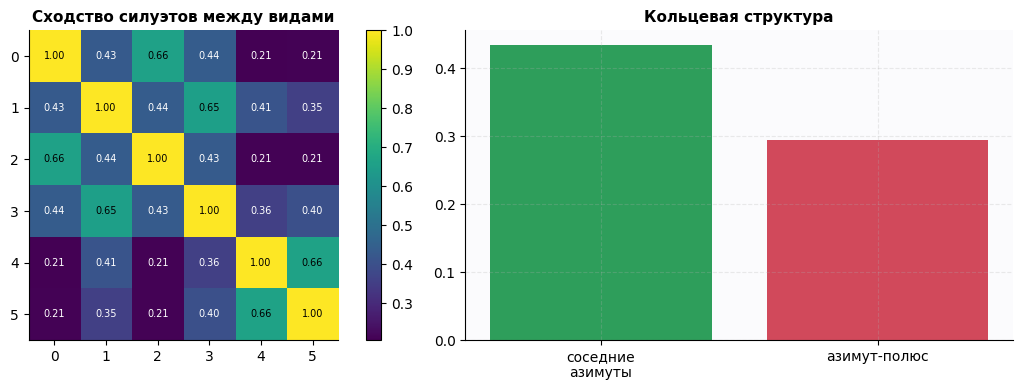

  [+] раскладка подтверждена (кольцо 0.434 > крест 0.295) — 16 симметрий включены, TTA x8


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

  [+] модель собрана: logits (2, 11), attention (2, 11, 385), параметров 90.7M
    токенов в декодере               6 видов x 8^2 = 384 + 1 гео

  vitb336: фолд 0 / 5
  vit_base_patch14_reg4_dinov2 @ 336 | эпох 12
    объектов train / val             7161 / 1803
    шагов на эпоху                   3580 (оптимизаторских 298)
    LR бэкбона                       2.77e-07 … 2.00e-05 (затухание 0.7, блоков 12)


vitb336 f0 ep 1/12:   0%|          | 0/3580 [00:00<?, ?it/s]

...

  ep11/12 | метрика 14.745 (raw) = quality  7.52 + artefacts  7.22 | loss 0.254 | 4.9 мин | ост. 4м 52с <-- best
        abstr=0.81  artif=0.42  inter=0.24  lowpo=0.71  noisy=0.87  open=0.33  parti=0.66  scale=0.30  set=0.74  simpl=0.72  quali=0.75


vitb336 f0 ep12/12:   0%|          | 0/3580 [00:00<?, ?it/s]

val ep12 (TTA x1):   0%|          | 0/451 [00:00<?, ?it/s]

val-EMA ep12 (TTA x1):   0%|          | 0/451 [00:00<?, ?it/s]

  ep12/12 | метрика 14.800 (raw) = quality  7.56 + artefacts  7.24 | loss 0.250 | 4.9 мин | ост. 0м 00с <-- best
        abstr=0.81  artif=0.42  inter=0.26  lowpo=0.71  noisy=0.86  open=0.34  parti=0.66  scale=0.31  set=0.75  simpl=0.72  quali=0.76
    [зеркало] чекпоинт эпохи 12 -> Drive (908 МБ)


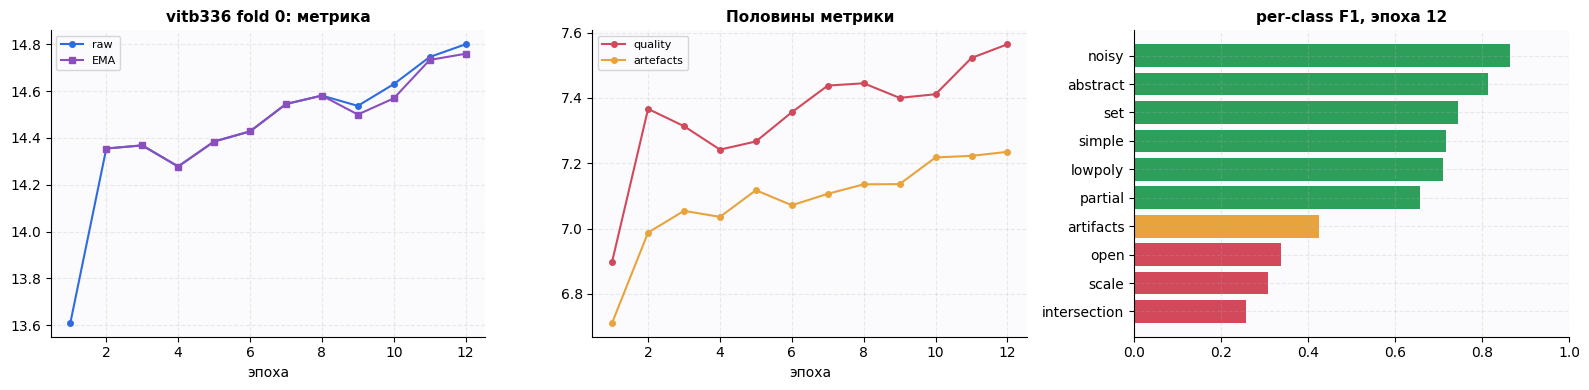

OOF snap1/3 (TTA x8):   0%|          | 0/451 [00:00<?, ?it/s]

test snap1/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

OOF snap2/3 (TTA x8):   0%|          | 0/451 [00:00<?, ?it/s]

test snap2/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

OOF snap3/3 (TTA x8):   0%|          | 0/451 [00:00<?, ?it/s]

...

  ep11/12 | метрика 14.706 (raw) = quality  7.72 + artefacts  6.99 | loss 0.247 | 5.0 мин | ост. 4м 57с
        abstr=0.78  artif=0.36  inter=0.17  lowpo=0.67  noisy=0.85  open=0.34  parti=0.58  scale=0.33  set=0.66  simpl=0.73  quali=0.77


vitb336 f1 ep12/12:   0%|          | 0/3590 [00:00<?, ?it/s]

val ep12 (TTA x1):   0%|          | 0/446 [00:00<?, ?it/s]

val-EMA ep12 (TTA x1):   0%|          | 0/446 [00:00<?, ?it/s]

  ep12/12 | метрика 14.681 (raw) = quality  7.72 + artefacts  6.96 | loss 0.244 | 4.9 мин | ост. 0м 00с
        abstr=0.78  artif=0.36  inter=0.17  lowpo=0.67  noisy=0.84  open=0.35  parti=0.57  scale=0.33  set=0.66  simpl=0.73  quali=0.77
    [зеркало] чекпоинт эпохи 12 -> Drive (908 МБ)


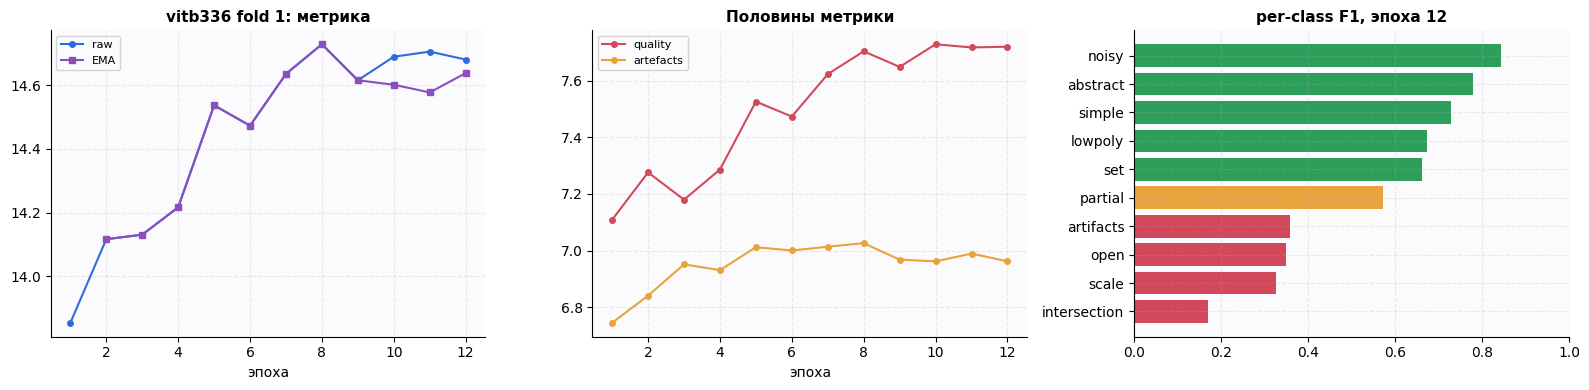

OOF snap1/3 (TTA x8):   0%|          | 0/446 [00:00<?, ?it/s]

test snap1/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

OOF snap2/3 (TTA x8):   0%|          | 0/446 [00:00<?, ?it/s]

test snap2/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

OOF snap3/3 (TTA x8):   0%|          | 0/446 [00:00<?, ?it/s]

...

  ep11/12 | метрика 14.659 (EMA) = quality  7.45 + artefacts  7.21 | loss 0.246 | 4.9 мин | ост. 4м 56с
        abstr=0.81  artif=0.41  inter=0.11  lowpo=0.67  noisy=0.87  open=0.35  parti=0.63  scale=0.39  set=0.70  simpl=0.75  quali=0.74


vitb336 f2 ep12/12:   0%|          | 0/3596 [00:00<?, ?it/s]

val ep12 (TTA x1):   0%|          | 0/443 [00:00<?, ?it/s]

val-EMA ep12 (TTA x1):   0%|          | 0/443 [00:00<?, ?it/s]

  ep12/12 | метрика 14.613 (EMA) = quality  7.40 + artefacts  7.21 | loss 0.245 | 4.9 мин | ост. 0м 00с
        abstr=0.82  artif=0.41  inter=0.11  lowpo=0.67  noisy=0.87  open=0.36  parti=0.62  scale=0.36  set=0.70  simpl=0.75  quali=0.74
    [зеркало] чекпоинт эпохи 12 -> Drive (908 МБ)


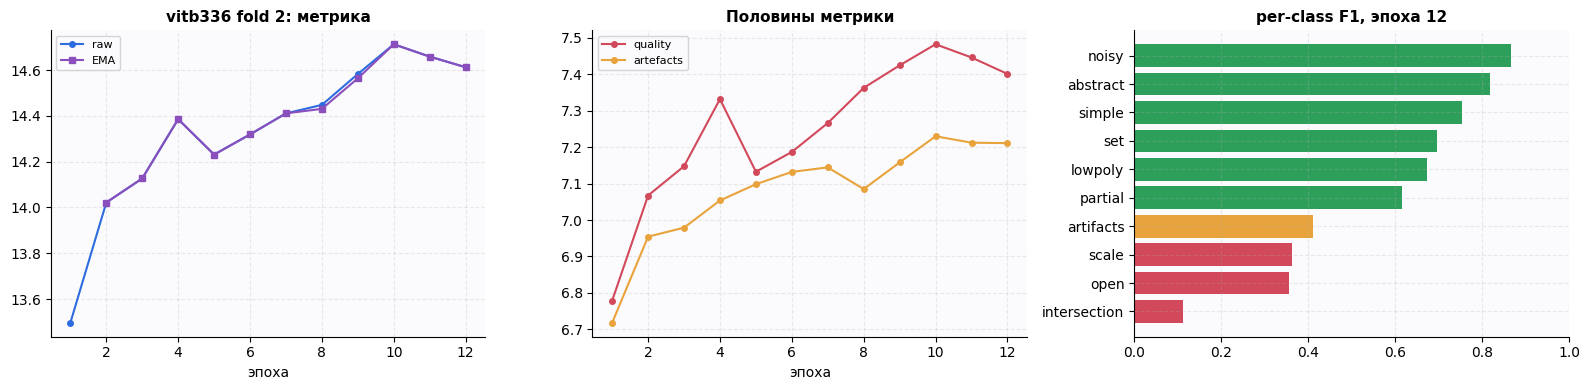

OOF snap1/3 (TTA x8):   0%|          | 0/443 [00:00<?, ?it/s]

test snap1/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

OOF snap2/3 (TTA x8):   0%|          | 0/443 [00:00<?, ?it/s]

test snap2/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

OOF snap3/3 (TTA x8):   0%|          | 0/443 [00:00<?, ?it/s]

...

  ep11/12 | метрика 14.412 (raw) = quality  7.30 + artefacts  7.11 | loss 0.240 | 4.9 мин | ост. 4м 56с <-- best
        abstr=0.79  artif=0.33  inter=0.17  lowpo=0.67  noisy=0.87  open=0.38  parti=0.58  scale=0.27  set=0.69  simpl=0.75  quali=0.73


vitb336 f3 ep12/12:   0%|          | 0/3578 [00:00<?, ?it/s]

val ep12 (TTA x1):   0%|          | 0/452 [00:00<?, ?it/s]

val-EMA ep12 (TTA x1):   0%|          | 0/452 [00:00<?, ?it/s]

  ep12/12 | метрика 14.388 (EMA) = quality  7.28 + artefacts  7.11 | loss 0.236 | 5.0 мин | ост. 0м 00с
        abstr=0.79  artif=0.33  inter=0.17  lowpo=0.68  noisy=0.87  open=0.36  parti=0.58  scale=0.27  set=0.68  simpl=0.75  quali=0.73
    [зеркало] чекпоинт эпохи 12 -> Drive (908 МБ)


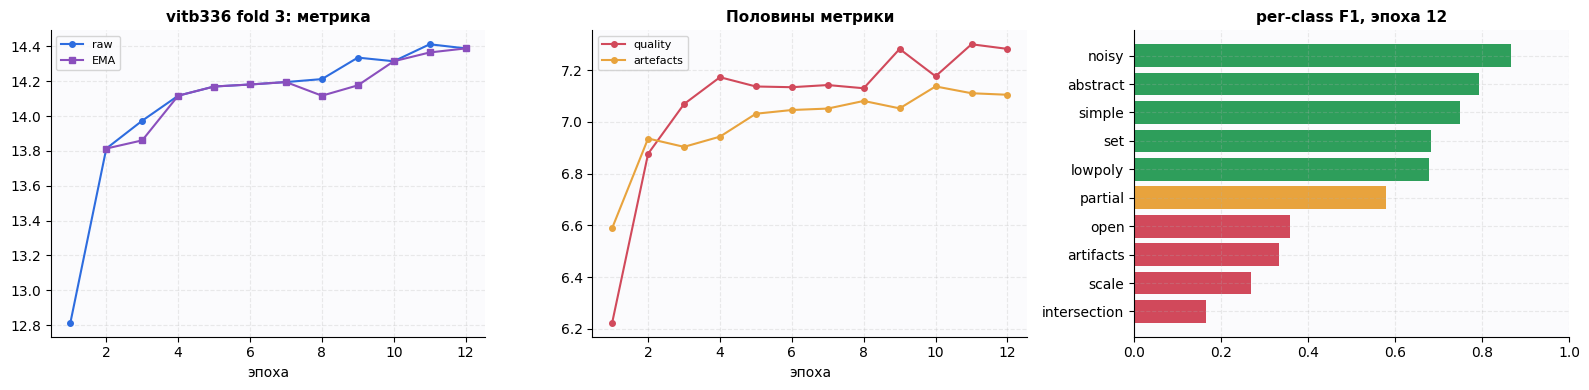

OOF snap1/3 (TTA x8):   0%|          | 0/452 [00:00<?, ?it/s]

test snap1/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

OOF snap2/3 (TTA x8):   0%|          | 0/452 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4d3f855f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4d3f855f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

test snap2/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

...

  ep11/12 | метрика 14.494 (raw) = quality  7.35 + artefacts  7.15 | loss 0.252 | 5.0 мин | ост. 4м 57с
        abstr=0.84  artif=0.35  inter=0.12  lowpo=0.66  noisy=0.86  open=0.32  parti=0.62  scale=0.29  set=0.69  simpl=0.76  quali=0.73


vitb336 f4 ep12/12:   0%|          | 0/3583 [00:00<?, ?it/s]

val ep12 (TTA x1):   0%|          | 0/450 [00:00<?, ?it/s]

val-EMA ep12 (TTA x1):   0%|          | 0/450 [00:00<?, ?it/s]

  ep12/12 | метрика 14.406 (raw) = quality  7.27 + artefacts  7.14 | loss 0.247 | 5.0 мин | ост. 0м 00с
        abstr=0.84  artif=0.35  inter=0.11  lowpo=0.66  noisy=0.86  open=0.32  parti=0.61  scale=0.29  set=0.69  simpl=0.76  quali=0.73
    [зеркало] чекпоинт эпохи 12 -> Drive (908 МБ)


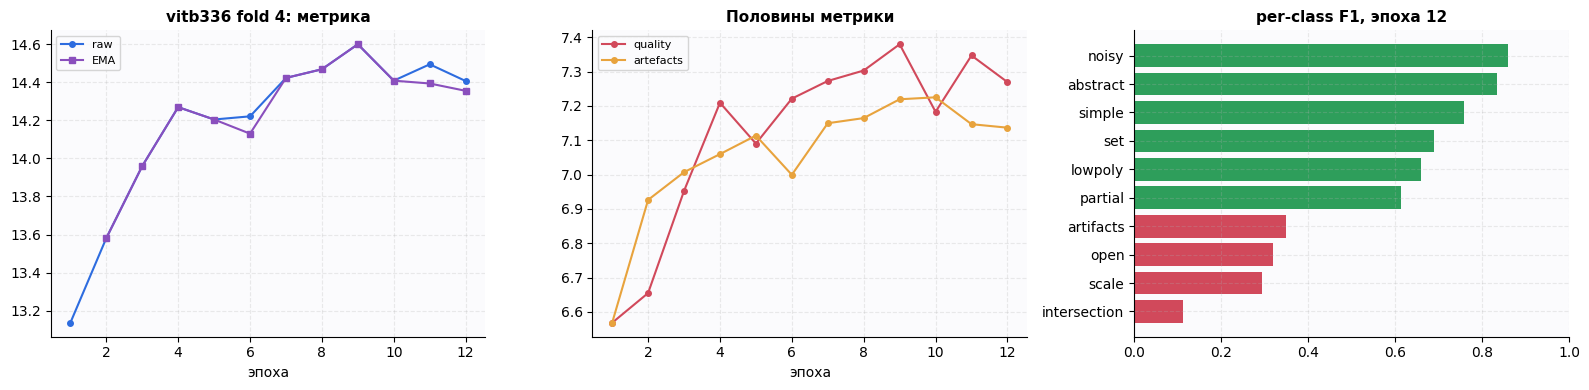

OOF snap1/3 (TTA x8):   0%|          | 0/450 [00:00<?, ?it/s]

test snap1/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

OOF snap2/3 (TTA x8):   0%|          | 0/450 [00:00<?, ?it/s]

test snap2/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

OOF snap3/3 (TTA x8):   0%|          | 0/450 [00:00<?, ?it/s]

test snap3/3 (TTA x8):   0%|          | 0/168 [00:00<?, ?it/s]

  лучшая эпоха 14.599 -> снапшот-ансамбль + TTA 14.464 (-0.135)
    фолд 4                 |##################..................| 14.464
>>> vitb336: 5/5 фолдов | от старта 6.2 ч
    OOF метрика                      14.482
    по фолдам                        0:14.80, 1:14.71, 2:14.76, 3:14.38, 4:14.46
    ветка vitb336          |##################..................| 14.482


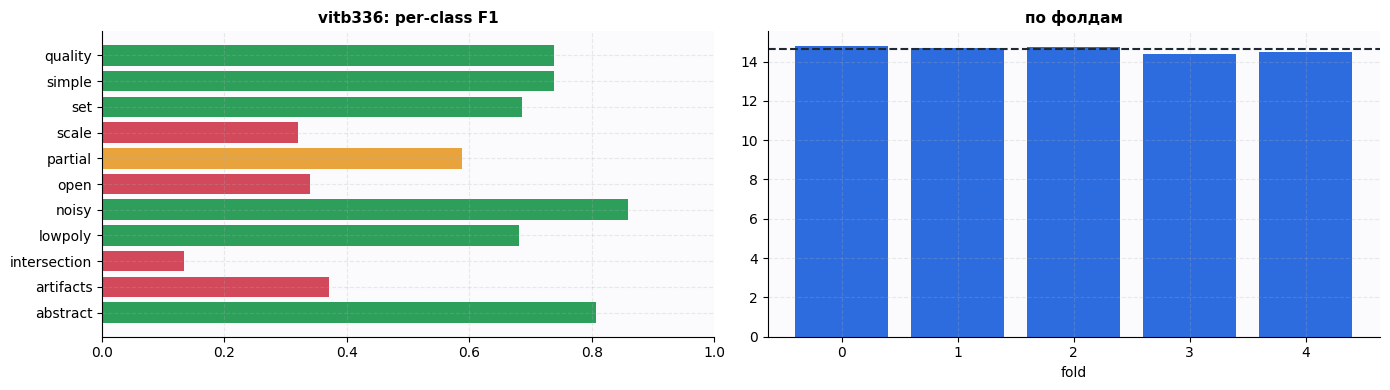

In [21]:
RUNS = globals().get('RUNS', {})
RUNS['vitb336'] = run_branch('vitb336')

### 10.2. Ветка `v5_224` — ViT-S/14 DINOv2 @224, gated pooling

В исходнике `sber_meshqc_multiview_v5` она называлась `dinos224_geo2_v5`; здесь
переименована только ради унификации ансамбля. Признаки — её собственные: геометрия
`v4selfint` с капом самопересечений 120k граней и силуэты считаются **одним проходом**
(`build_features`), CLIP — по кэшу рендеров @224, затем дедупликация колонок.

In [22]:
prepare_branch('v5_224')


  ПОДГОТОВКА ВЕТКИ v5_224
  vit_small_patch14_reg4_dinov2 @ 224 | 16 эпох | batch 12x2 | вес в ансамбле 0.5


cache train:   0%|          | 0/8964 [00:00<?, ?it/s]

train: закэшировано 8964/8964
train: всего в кэше 8964/8964, нет картинки у 0


cache test:   0%|          | 0/669 [00:00<?, ?it/s]

test: закэшировано 669/669
test: всего в кэше 669/669, нет картинки у 0
  [+] рендеры готовы — выполните ячейку признаков этой ветки


In [23]:
import os, gc, math, numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
from scipy import ndimage
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import ConvexHull, QhullError
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures.process import BrokenProcessPool
import multiprocessing as mp

FACE_CAP  = 300_000
VERT_CAP  = 200_000
HULL_CAP  = 20_000
COMP_CAP  = 3_000_000
WELD_TOL  = 1e-6         # доля диагонали bbox
FEAT_VER  = 'v4selfint'  # версия набора фич: входит в имя кэша. Поднята с v3weld, т.к.
                         # добавлены §4.5.1-4.5.3 (самопересечения/качество треугольников/
                         # non-manifold вершины) — старый parquet без них не подхватится молча
N_WORKERS = min(4, os.cpu_count() or 2)
CHUNK     = 1024

def _pack21(q):
    """Три целых из [0, 2**21) -> один int64. Точно, без коллизий."""
    return (q[:, 0] << 42) | (q[:, 1] << 21) | q[:, 2]

def _hash3(q):
    q = q.astype(np.int64, copy=False)
    return (q[:, 0] * 73856093) ^ (q[:, 1] * 19349663) ^ (q[:, 2] * 83492791)

def _stats(x, pref):
    keys = ['mean', 'std', 'p10', 'p50', 'p90', 'max', 'cv']
    if len(x) == 0:
        return {f'{pref}_{k}': 0.0 for k in keys}
    x = np.asarray(x, dtype=np.float32)
    m, s = float(x.mean()), float(x.std())
    q10, q50, q90 = np.percentile(x, [10, 50, 90])
    return {f'{pref}_mean': m, f'{pref}_std': s, f'{pref}_p10': float(q10),
            f'{pref}_p50': float(q50), f'{pref}_p90': float(q90),
            f'{pref}_max': float(x.max()), f'{pref}_cv': float(s / (abs(m) + 1e-9))}

def _edge_table(Fi, nfw):
    """Рёбра -> (номер группы, число граней на ребро, отсортированные id граней)."""
    E = np.concatenate([Fi[:, [0, 1]], Fi[:, [1, 2]], Fi[:, [2, 0]]], 0)
    E.sort(axis=1)
    fid = np.tile(np.arange(nfw, dtype=np.int32), 3)
    order = np.lexsort((E[:, 1], E[:, 0]))
    Es, fids = E[order], fid[order]
    new = np.ones(len(Es), dtype=bool)
    new[1:] = (Es[1:] != Es[:-1]).any(1)
    grp = np.cumsum(new) - 1
    counts = np.bincount(grp)
    return E, Es, fids, grp, counts, new

def mesh_features(npz_path):
    f = {'geo_ok': 0.0, 'geo_subsampled': 0.0}
    try:
        f['npz_mb'] = os.path.getsize(npz_path) / 1e6
    except Exception:
        return f
    try:
        with np.load(npz_path, allow_pickle=False) as d:
            keys = list(d.keys())
            V = np.asarray(d['vertices' if 'vertices' in keys else keys[0]], dtype=np.float32)
            Fc = None
            for k in ('faces', 'triangles', 'f'):
                if k in keys:
                    Fc = np.asarray(d[k], dtype=np.int64); break
            if Fc is None and len(keys) > 1:
                Fc = np.asarray(d[keys[1]], dtype=np.int64)
    except Exception:
        return f
    if V.ndim != 2 or V.shape[1] != 3 or len(V) == 0:
        return f
    if Fc is None or Fc.ndim != 2 or Fc.shape[1] != 3 or len(Fc) == 0:
        Fc = np.zeros((0, 3), dtype=np.int64)
    else:
        Fc = Fc[(Fc >= 0).all(1) & (Fc < len(V)).all(1)]

    f['geo_ok'] = 1.0
    nv_raw, nf_raw = len(V), len(Fc)
    vmin, vmax = V.min(0), V.max(0)
    ext = (vmax - vmin).astype(np.float64)
    ext_s = np.sort(ext)[::-1]
    diag = float(np.linalg.norm(ext)) + 1e-12
    center = ((vmin + vmax) / 2).astype(np.float32)
    inv_s = np.float32(1.0 / diag)
    f.update({'n_verts_raw': float(nv_raw), 'n_faces': float(nf_raw),
              'log_verts': math.log1p(nv_raw), 'log_faces': math.log1p(nf_raw),
              'ext_max': float(ext_s[0]), 'ext_mid': float(ext_s[1]), 'ext_min': float(ext_s[2]),
              'ext_ratio_min': float(ext_s[2] / (ext_s[0] + 1e-12)),
              'ext_ratio_mid': float(ext_s[1] / (ext_s[0] + 1e-12)),
              'bbox_diag': diag,
              'bbox_fill': float(nv_raw / (ext.prod() + 1e-12)) if ext.prod() > 0 else 0.0})

    # ================== СВАРКА ВЕРШИН ==================
    # Экспортёры (glTF/OBJ с раздельными нормалями и UV) дублируют вершины на каждую грань.
    # Без сварки НИ ОДНО ребро не имеет двух граней: двугранные углы пусты, boundary=1.0,
    # компонент столько же, сколько треугольников. Вся топология обязана считаться после сварки.
    step = np.float32(diag * WELD_TOL)
    q = np.clip(np.rint((V - vmin) / step), 0, (1 << 21) - 1).astype(np.int64)
    code = _pack21(q)
    del q
    ucode, first, invmap = np.unique(code, return_index=True, return_inverse=True)
    del code, ucode
    nv = len(first)
    f['n_verts'] = float(nv)
    f['weld_ratio'] = float(1.0 - nv / max(nv_raw, 1))          # 0 = уже сварен, ~0.83 = по 3 вершины на грань
    f['f_per_v'] = nf_raw / max(nv, 1)
    Vw_full = V[first]
    del first

    if nf_raw:
        Fw = invmap[Fc]
        ok = (Fw[:, 0] != Fw[:, 1]) & (Fw[:, 1] != Fw[:, 2]) & (Fw[:, 0] != Fw[:, 2])
        f['degen_after_weld'] = float(1.0 - ok.mean())
        Fw = Fw[ok]
        hf = _hash3(np.sort(Fw, axis=1))
        _, uidx = np.unique(hf, return_index=True)
        f['dup_face_ratio'] = float(1.0 - len(uidx) / max(len(Fw), 1))
        Fw = Fw[np.sort(uidx)]
        del hf, uidx, ok
    else:
        Fw = np.zeros((0, 3), dtype=np.int64)
        f['degen_after_weld'] = 0.0; f['dup_face_ratio'] = 0.0
    del invmap, Fc
    nf = len(Fw)

    # ---- вершинные статистики (подвыборка) ----
    Vs = Vw_full[::max(1, int(np.ceil(nv / VERT_CAP)))]
    if nv > VERT_CAP:
        f['geo_subsampled'] = 1.0
    Vs = (Vs - center) * inv_s
    try:
        if len(Vs) < 3:
            raise ValueError('too few vertices')
        ev = np.clip(np.linalg.eigvalsh(np.cov(Vs.T.astype(np.float64)))[::-1], 1e-16, None)
        f.update({'pca_1': float(ev[0]), 'pca_2': float(ev[1]), 'pca_3': float(ev[2]),
                  'pca_flat': float(ev[2] / ev[0]), 'pca_lin': float(ev[1] / ev[0]),
                  'pca_aniso': float((ev[0] - ev[2]) / ev.sum())})
    except Exception:
        f.update({k: 0.0 for k in ['pca_1', 'pca_2', 'pca_3', 'pca_flat', 'pca_lin', 'pca_aniso']})

    # ---- выпуклая оболочка: solidity/сферичность -> simple, open ----
    f.update({'hull_ok': 0.0, 'solidity': 0.0, 'solidity_signed': 0.0, 'hull_area_ratio': 0.0,
              'hull_pts_frac': 0.0, 'sphericity': 0.0, 'hull_vol': 0.0, 'hull_area': 0.0})
    try:
        Vh = Vs[::max(1, int(np.ceil(len(Vs) / HULL_CAP)))].astype(np.float64)
        if len(Vh) >= 8:
            hull = ConvexHull(Vh, qhull_options='QJ')
            f['hull_ok'] = 1.0
            f['hull_vol'] = float(hull.volume)
            f['hull_pts_frac'] = len(hull.vertices) / len(Vh)
            f['hull_area'] = float(hull.area)
    except (QhullError, ValueError, MemoryError):
        pass

    if nf == 0:
        f['no_faces'] = 1.0
        f.update({'area_total': 0.0, 'volume': 0.0, 'abs_volume': 0.0, 'vol_ratio': 0.0,
                  'vol_over_area': 0.0, 'absvol_over_area': 0.0, 'vol_over_bbox': 0.0,
                  'absvol_over_bbox': 0.0})
        for pref in ('dihed', 'dihedf', 'farea', 'elen', 'aspect', 'valence', 'defect'):
            f.update(_stats([], pref))
        return f
    f['no_faces'] = 0.0

    # ---- точные площадь/объём по полному сваренному мешу ----
    total_area, vol6, absvol6 = 0.0, 0.0, 0.0
    for s0 in range(0, nf, 500_000):
        Pc = ((Vw_full[Fw[s0:s0 + 500_000]] - center) * inv_s).astype(np.float64)
        cr_c = np.cross(Pc[:, 1] - Pc[:, 0], Pc[:, 2] - Pc[:, 0])
        total_area += 0.5 * float(np.linalg.norm(cr_c, axis=1).sum())
        contrib = (Pc[:, 0] * np.cross(Pc[:, 1], Pc[:, 2])).sum(1)
        vol6 += float(contrib.sum()); absvol6 += float(np.abs(contrib).sum())
        del Pc, cr_c, contrib
    total_area += 1e-12
    vol = abs(vol6 / 6.0)
    absvol = absvol6 / 6.0
    # vol_ratio ~1 у корректно ориентированного меша и ~0 при несогласованной намотке граней
    # (сама по себе сильная улика для artifacts/noisy). Объём для solidity берём устойчивый.
    f.update({'area_total': total_area, 'volume': vol, 'abs_volume': absvol,
              'vol_ratio': vol / (absvol + 1e-12),
              'vol_over_area': vol / (total_area ** 1.5 + 1e-12),
              'absvol_over_area': absvol / (total_area ** 1.5 + 1e-12),
              'vol_over_bbox': vol / (float(np.prod(ext * inv_s)) + 1e-12),
              'absvol_over_bbox': absvol / (float(np.prod(ext * inv_s)) + 1e-12)})
    if f['hull_ok']:
        f['solidity'] = absvol / (f['hull_vol'] + 1e-12)
        f['solidity_signed'] = vol / (f['hull_vol'] + 1e-12)
        f['hull_area_ratio'] = total_area / (f.get('hull_area', 0.0) + 1e-12)
        f['sphericity'] = (math.pi ** (1 / 3)) * (6 * absvol) ** (2 / 3) / (total_area + 1e-12)

    # ---- компоненты связности на полном СВАРЕННОМ меше ----
    f.update({'n_comp': 1.0, 'n_comp_big': 1.0, 'comp_top1': 1.0, 'comp_top2': 0.0,
              'comp_entropy': 0.0, 'bbox_iou_max': 0.0, 'bbox_iou_mean': 0.0,
              'bbox_iou_frac_pos': 0.0, 'comp_sep_max': 0.0, 'comp_sep_mean': 0.0,
              'inside_frac_max': 0.0, 'comp_exact': 1.0})
    if nf <= COMP_CAP:
        try:
            Ef = np.concatenate([Fw[:, [0, 1]], Fw[:, [1, 2]], Fw[:, [2, 0]]], 0).astype(np.int32)
            A = coo_matrix((np.ones(len(Ef), dtype=np.int8), (Ef[:, 0], Ef[:, 1])), shape=(nv, nv))
            del Ef
            ncomp, lab = connected_components(A, directed=False)
            del A
            used = np.unique(Fw)
            sizes_all = np.bincount(lab[used], minlength=ncomp).astype(np.float64)
            sizes = np.sort(sizes_all[sizes_all > 0])[::-1]
            tot = sizes.sum()
            big_idx = np.where(sizes_all > 0.005 * tot)[0]
            f.update({'n_comp': float(len(sizes)), 'n_comp_big': float(len(big_idx)),
                      'comp_top1': float(sizes[0] / tot),
                      'comp_top2': float(sizes[1] / tot) if len(sizes) > 1 else 0.0,
                      'comp_entropy': float(-((sizes / tot) * np.log(sizes / tot + 1e-12)).sum())})
            if len(big_idx) > 1:
                top = big_idx[np.argsort(-sizes_all[big_idx])][:8]
                pts_l, boxes = [], []
                for c in top:
                    ic = used[lab[used] == c]
                    if len(ic) > 20_000:
                        ic = ic[::len(ic) // 20_000 + 1]
                    p = (Vw_full[ic] - center) * inv_s
                    pts_l.append(p); boxes.append((p.min(0), p.max(0)))
                ious, seps, insides = [], [], []
                for i in range(len(boxes)):
                    for j in range(len(boxes)):
                        if i == j:
                            continue
                        lo, hi = boxes[j]
                        insides.append(float(((pts_l[i] >= lo) & (pts_l[i] <= hi)).all(1).mean()))
                        if j <= i:
                            continue
                        lo2 = np.maximum(boxes[i][0], boxes[j][0])
                        hi2 = np.minimum(boxes[i][1], boxes[j][1])
                        it = float(np.prod(np.clip(hi2 - lo2, 0, None)))
                        vi = float(np.prod(np.clip(boxes[i][1] - boxes[i][0], 1e-6, None)))
                        vj = float(np.prod(np.clip(boxes[j][1] - boxes[j][0], 1e-6, None)))
                        ious.append(it / (vi + vj - it + 1e-12))
                        seps.append(float(np.linalg.norm(
                            (boxes[i][0] + boxes[i][1]) / 2 - (boxes[j][0] + boxes[j][1]) / 2)))
                f.update({'bbox_iou_max': float(max(ious)), 'bbox_iou_mean': float(np.mean(ious)),
                          'bbox_iou_frac_pos': float(np.mean(np.asarray(ious) > 1e-6)),
                          'comp_sep_max': float(max(seps)), 'comp_sep_mean': float(np.mean(seps)),
                          'inside_frac_max': float(max(insides))})
            del lab, sizes_all, sizes, used
        except Exception:
            f['comp_exact'] = 0.0
    else:
        f['comp_exact'] = 0.0

    # ---- пространственный патч для рёберной топологии ----
    if nf > FACE_CAP:
        f['geo_subsampled'] = 1.0
        anchor = (Vw_full[Fw[:, 0]] - vmin) / (ext.astype(np.float32) + 1e-9)
        Fp, g = None, 1
        while g < 40:
            g += 1
            cid = np.minimum((anchor * g).astype(np.int32), g - 1)
            key = (cid[:, 0] * g + cid[:, 1]) * g + cid[:, 2]
            cnt = np.bincount(key, minlength=g ** 3)
            best = int(np.argmax(cnt))
            if cnt[best] <= FACE_CAP:
                Fp = Fw[key == best]; break
        if Fp is None or len(Fp) < 1000:
            Fp = Fw[:FACE_CAP]
        f['patch_grid'] = float(g)
        del anchor
    else:
        Fp = Fw
        f['patch_grid'] = 1.0
    f['patch_face_frac'] = len(Fp) / max(nf, 1)
    del Fw
    nfw = len(Fp)

    uvp, Fi = np.unique(Fp, return_inverse=True)
    Fi = Fi.reshape(nfw, 3).astype(np.int32)
    Vp = ((Vw_full[uvp] - center) * inv_s).astype(np.float32)
    nvp = len(uvp)
    del uvp, Fp, Vw_full, V

    P = Vp[Fi]
    cr = np.cross(P[:, 1] - P[:, 0], P[:, 2] - P[:, 0])
    area2 = np.linalg.norm(cr, axis=1)
    area = 0.5 * area2
    nrm = cr / (area2[:, None] + 1e-12)
    del cr
    f.update(_stats(area / (area.mean() + 1e-12), 'farea'))
    f['degenerate_ratio'] = float((area < 1e-10).mean())

    L = np.stack([np.linalg.norm(P[:, 1] - P[:, 0], axis=1),
                  np.linalg.norm(P[:, 2] - P[:, 1], axis=1),
                  np.linalg.norm(P[:, 0] - P[:, 2], axis=1)], 1)
    f.update(_stats(L.ravel() / (L.mean() + 1e-12), 'elen'))
    aspect = L.max(1) / (L.min(1) + 1e-12)
    f.update(_stats(np.log1p(aspect), 'aspect'))
    f['sliver_ratio'] = float((aspect > 20).mean())

    # ---- §4.5.2 качество треугольников: худший угол + нормализованная форма ----
    # min-угол — классический индикатор "плохого" элемента (aspect ratio его не всегда
    # ловит: длинный тупоугольный треугольник может иметь умеренный aspect, но острый
    # min-угол). tri_quality = 4*sqrt(3)*area/(l0^2+l1^2+l2^2) -> 1.0 для равностороннего,
    # ->0 для вырожденного; оба считаются векторно из уже посчитанных L и area, без
    # дополнительного прохода по мешу.
    L0, L1, L2 = L[:, 0], L[:, 1], L[:, 2]
    with np.errstate(divide='ignore', invalid='ignore'):
        cA = np.clip((L1 ** 2 + L2 ** 2 - L0 ** 2) / (2 * L1 * L2 + 1e-12), -1, 1)
        cB = np.clip((L0 ** 2 + L2 ** 2 - L1 ** 2) / (2 * L0 * L2 + 1e-12), -1, 1)
        cC = np.clip((L0 ** 2 + L1 ** 2 - L2 ** 2) / (2 * L0 * L1 + 1e-12), -1, 1)
    tri_ang = np.degrees(np.arccos(np.stack([cA, cB, cC], 1)))
    min_ang, max_ang = tri_ang.min(1), tri_ang.max(1)
    f.update(_stats(min_ang, 'minang')); f.update(_stats(max_ang, 'maxang'))
    f['sliver_angle_ratio'] = float((min_ang < 5).mean())
    tri_quality = np.clip((4 * math.sqrt(3) * area) / (L0 ** 2 + L1 ** 2 + L2 ** 2 + 1e-12), 0, 1)
    f.update(_stats(tri_quality, 'triq'))
    del L0, L1, L2, cA, cB, cC, tri_ang, min_ang, max_ang, tri_quality

    for qd in (1, 2):
        f[f'uniq_normals_q{qd}'] = len(np.unique(_hash3(np.rint(nrm * 10 ** qd)))) / nfw
    # концентрация нормалей: доля площади в 6 крупнейших кластерах -> примитивы
    hn = _hash3(np.rint(nrm * 20))
    _, ninv = np.unique(hn, return_inverse=True)
    mass = np.bincount(ninv, weights=area)
    mass = np.sort(mass)[::-1]
    f['normal_top6_mass'] = float(mass[:6].sum() / (mass.sum() + 1e-12))
    f['normal_top1_mass'] = float(mass[0] / (mass.sum() + 1e-12))
    del hn, ninv, mass

    # ---- §4.5.1 самопересечения: близкие по центроиду грани без общей вершины ----
    # intersection сейчас ловится только CNN с рендеров; хуже того, его confusion
    # портит quality (10 из 16 баллов), даже когда сам класс почти ничего не весит
    # (см. §14, "потолок по классам": intersection+scale = 0.18 балла при идеальном
    # предсказании) — поэтому цель этих фич не "поднять F1(intersection)" сама по себе,
    # а снизить количество ложных срабатываний, которые размывают quality.
    # cKDTree.query_pairs даёт кандидатов почти даром; точный тест — 6 рёберно-плоскостных
    # проверок на кандидата (Möller-style), полностью векторизован по всем парам разом.
    f.update({'selfint_ok': 0.0, 'selfint_pair_ratio': 0.0, 'selfint_face_ratio': 0.0,
              'selfint_any': 0.0, 'selfint_capped': 0.0})
    SELFINT_FACE_CAP = 120_000
    SELFINT_PAIR_CAP = 400_000
    if 0 < nfw <= SELFINT_FACE_CAP:
        try:
            from scipy.spatial import cKDTree
            cen = Vp[Fi].mean(1)
            elen_med = float(np.median(L)) if len(L) else 1e-6
            r = max(elen_med * 2.5, 1e-6)
            pairs = cKDTree(cen).query_pairs(r=r, output_type='ndarray')
            if len(pairs):
                share = (Fi[pairs[:, 0], :, None] == Fi[pairs[:, 1], None, :]).any((1, 2))
                pairs = pairs[~share]
            if len(pairs) > SELFINT_PAIR_CAP:
                sel = np.random.default_rng(0).choice(len(pairs), SELFINT_PAIR_CAP, replace=False)
                pairs = pairs[sel]
                f['selfint_capped'] = 1.0
            f['selfint_ok'] = 1.0
            if len(pairs):
                ii, jj = pairs[:, 0], pairs[:, 1]
                PA, PB = Vp[Fi[ii]], Vp[Fi[jj]]
                nA, nB = nrm[ii], nrm[jj]

                def _edge_hits(a, b, p0, p1, p2, n):
                    d = np.einsum('ij,ij->i', n, p0)
                    ta = np.einsum('ij,ij->i', n, a) - d
                    tb = np.einsum('ij,ij->i', n, b) - d
                    denom = ta - tb
                    safe = np.abs(denom) > 1e-12
                    t = np.clip(np.divide(ta, denom, out=np.zeros_like(ta), where=safe), 0.0, 1.0)
                    pt = a + t[:, None] * (b - a)
                    e0 = np.cross(p1 - p0, pt - p0); e1 = np.cross(p2 - p1, pt - p1)
                    e2 = np.cross(p0 - p2, pt - p2)
                    s0 = np.einsum('ij,ij->i', e0, n); s1 = np.einsum('ij,ij->i', e1, n)
                    s2 = np.einsum('ij,ij->i', e2, n)
                    inside = (((s0 >= -1e-9) & (s1 >= -1e-9) & (s2 >= -1e-9)) |
                              ((s0 <= 1e-9) & (s1 <= 1e-9) & (s2 <= 1e-9)))
                    return (ta * tb <= 0) & safe & inside

                hit = np.zeros(len(pairs), dtype=bool)
                for e in range(3):
                    hit |= _edge_hits(PA[:, e], PA[:, (e + 1) % 3], PB[:, 0], PB[:, 1], PB[:, 2], nB)
                for e in range(3):
                    hit |= _edge_hits(PB[:, e], PB[:, (e + 1) % 3], PA[:, 0], PA[:, 1], PA[:, 2], nA)
                n_hit = int(hit.sum())
                f['selfint_pair_ratio'] = float(n_hit / max(nfw, 1))
                f['selfint_any'] = float(n_hit > 0)
                if n_hit:
                    f['selfint_face_ratio'] = float(
                        len(np.unique(np.concatenate([ii[hit], jj[hit]]))) / max(nfw, 1))
                del PA, PB, nA, nB, hit
            del cen, pairs
        except Exception:
            pass
    else:
        f['selfint_capped'] = 1.0

    # ---- рёбра/углы ПОСЛЕ сварки + диагностика "как было бы БЕЗ сварки" ----
    E, Es, fids, grp, counts, _ = _edge_table(Fi, nfw)
    n_edges = len(counts)
    f.update({'n_edges': float(n_edges),
              'boundary_edge_ratio': float((counts == 1).mean()),
              'nonmanifold_edge_ratio': float((counts >= 3).mean()),
              'euler_norm': float((nvp - n_edges + nfw) / max(nfw, 1)),
              'euler_char': float(nvp - n_edges + nfw),
              'watertight': float((counts == 1).sum() == 0 and (counts >= 3).sum() == 0),
              'manifold_edge_ratio': float((counts == 2).mean())})

    # число граничных петель -> сколько «дыр» в поверхности (open)
    bnd = np.where(counts == 1)[0]
    f['nonmanifold_vert_ratio'] = 0.0
    if len(bnd):
        st = np.searchsorted(grp, bnd)
        be = Es[st]
        try:
            Ab = coo_matrix((np.ones(len(be), dtype=np.int8), (be[:, 0], be[:, 1])), shape=(nvp, nvp))
            nb_comp, lb = connected_components(Ab, directed=False)
            used_b = np.unique(be)
            f['n_boundary_loops'] = float(len(np.unique(lb[used_b])))
            f['boundary_vert_frac'] = float(len(used_b) / nvp)
            del Ab, lb, used_b
        except Exception:
            f['n_boundary_loops'] = 0.0; f['boundary_vert_frac'] = 0.0
        # ---- §4.5.3 non-manifold вершины: степень >2 в графе граничных рёбер ----
        # у нормальной граничной петли каждая вершина имеет ровно 2 инцидентных
        # граничных ребра; степень >2 -> вершина, где встречаются несколько "дыр"
        # или веток границы (типичная примета artifacts/open после плохого шва).
        # Это дополняет уже имеющиеся nonmanifold_edge_ratio/watertight на уровне
        # вершин, а не рёбер, и считается одним bincount без дополнительного графа.
        deg_b = np.bincount(be.ravel(), minlength=nvp)
        f['nonmanifold_vert_ratio'] = float((deg_b > 2).sum() / max(nvp, 1))
        del be, st, deg_b
    else:
        f['n_boundary_loops'] = 0.0; f['boundary_vert_frac'] = 0.0

    two = np.where(counts == 2)[0]
    if len(two):
        st = np.searchsorted(grp, two)
        fa, fb = fids[st], fids[st + 1]
        cosang = np.clip((nrm[fa] * nrm[fb]).sum(1), -1, 1)
        ang = np.degrees(np.arccos(cosang))
        angf = np.degrees(np.arccos(np.abs(cosang)))
        f.update(_stats(ang, 'dihed')); f.update(_stats(angf, 'dihedf'))
        for t in (10, 30, 60, 90):
            f[f'dihed_gt{t}'] = float((ang > t).mean())
        for t in (5, 15, 30, 60):
            f[f'dihedf_gt{t}'] = float((angf > t).mean())
        f['flip_ratio'] = float((cosang < 0).mean())
        hist = np.bincount((angf / 5).astype(np.int32).clip(0, 17), minlength=18).astype(np.float64)
        p = hist / max(hist.sum(), 1)
        f['dihed_entropy'] = float(-(p[p > 0] * np.log(p[p > 0])).sum())
        f['smoothness'] = float(angf.mean() * math.sqrt(nfw) / 100.0)
        # взвешенный по длине ребра угол: устойчивее к мелким треугольникам
        el = np.linalg.norm(Vp[Es[st][:, 0]] - Vp[Es[st][:, 1]], axis=1)
        f['dihedf_areaw'] = float((angf * el).sum() / (el.sum() + 1e-12))
        del fa, fb, cosang, ang, angf, el
    else:
        f.update(_stats([], 'dihed')); f.update(_stats([], 'dihedf'))
        for t in (10, 30, 60, 90):
            f[f'dihed_gt{t}'] = 0.0
        for t in (5, 15, 30, 60):
            f[f'dihedf_gt{t}'] = 0.0
        f.update({'flip_ratio': 0.0, 'dihed_entropy': 0.0, 'smoothness': 0.0, 'dihedf_areaw': 0.0})

    # ---- валентность вершин и угловой дефект (гауссова кривизна) ----
    val = np.bincount(Fi.ravel(), minlength=nvp).astype(np.float32)
    f.update(_stats(val, 'valence'))
    f['valence_le3'] = float((val <= 3).mean())
    f['valence_ge8'] = float((val >= 8).mean())
    e01 = P[:, 1] - P[:, 0]; e12 = P[:, 2] - P[:, 1]; e20 = P[:, 0] - P[:, 2]
    def _ang(u, v):
        cu = (u * v).sum(1) / (np.linalg.norm(u, axis=1) * np.linalg.norm(v, axis=1) + 1e-12)
        return np.arccos(np.clip(cu, -1, 1))
    a0 = _ang(e01, -e20); a1 = _ang(e12, -e01); a2 = _ang(e20, -e12)
    defect = np.full(nvp, 2 * np.pi, dtype=np.float64)
    np.subtract.at(defect, Fi[:, 0], a0)
    np.subtract.at(defect, Fi[:, 1], a1)
    np.subtract.at(defect, Fi[:, 2], a2)
    interior = val > 0
    f.update(_stats(np.abs(defect[interior]), 'defect'))
    f['defect_sum'] = float(defect[interior].sum() / (2 * np.pi))     # ~ эйлерова характеристика
    f['defect_gt05'] = float((np.abs(defect[interior]) > 0.5).mean())
    del defect, val, a0, a1, a2, e01, e12, e20

    del E, Es, fids, grp, counts, two, nrm, P, Vp, Fi, L, aspect, area, area2
    return f

In [24]:
def image_features(png_path):
    f = {'img_ok': 0.0}
    try:
        img = Image.open(png_path).convert('L')
    except Exception:
        return f
    a = np.asarray(img, dtype=np.float32) / 255.0
    t = CFG.tile
    f['img_ok'] = 1.0
    covs, comps, edens, stds, bws, bhs = [], [], [], [], [], []
    for k in range(6):
        v = a[(k // 3) * t:(k // 3 + 1) * t, (k % 3) * t:(k % 3 + 1) * t]
        bg = np.median(np.concatenate([v[0], v[-1], v[:, 0], v[:, -1]]))
        mask = np.abs(v - bg) > 0.06
        cov = float(mask.mean()); covs.append(cov)
        if mask.any():
            ys, xs = np.where(mask)
            bws.append((xs.max() - xs.min() + 1) / t)
            bhs.append((ys.max() - ys.min() + 1) / t)
            lab, ncc = ndimage.label(mask)
            if ncc:
                sz = np.bincount(lab.ravel())[1:]
                comps.append(float((sz > 0.01 * sz.sum()).sum()))
            else:
                comps.append(0.0)
        else:
            bws.append(0.0); bhs.append(0.0); comps.append(0.0)
        edens.append(float(np.abs(np.diff(v, axis=1)).mean() + np.abs(np.diff(v, axis=0)).mean()))
        stds.append(float(v.std()))
    def agg(vals, pref):
        v = np.asarray(vals, dtype=np.float64)
        return {f'{pref}_mean': v.mean(), f'{pref}_min': v.min(), f'{pref}_max': v.max(),
                f'{pref}_std': v.std(), f'{pref}_range': v.max() - v.min()}
    f.update(agg(covs, 'cov')); f.update(agg(comps, 'ncc')); f.update(agg(edens, 'edge'))
    f.update(agg(stds, 'pxstd')); f.update(agg(bws, 'bw')); f.update(agg(bhs, 'bh'))
    f['cov_empty_views'] = float((np.asarray(covs) < 0.01).sum())
    f['bbox_fill_view'] = float(np.mean(np.asarray(covs) /
                                        (np.asarray(bws) * np.asarray(bhs) + 1e-6)))
    return f

def _feat_one(args):
    iid, npz, png = args
    d = {'item_id': iid}
    try:
        d.update(mesh_features(npz))
    except (MemoryError, Exception):
        d['geo_ok'] = 0.0
    try:
        d.update(image_features(png))
    except Exception:
        d['img_ok'] = 0.0
    return d

def build_features(ids, npz_dir, img_dir, split):
    """Чанками, с чекпоинтом и резюмированием. Повторный запуск после падения
    продолжает с последнего сохранённого чанка."""
    final = CFG.cache / f'feats_{split}_{CFG.tile}_{FEAT_VER}.parquet'
    ckpt  = CFG.cache / f'feats_{split}_{CFG.tile}_{FEAT_VER}_partial.parquet'
    if final.exists():
        df = pd.read_parquet(final); print(f'{split}: фичи из кэша {df.shape}'); return df

    done = pd.read_parquet(ckpt) if ckpt.exists() else pd.DataFrame(columns=['item_id'])
    have = set(done['item_id'].astype(str)) if len(done) else set()
    todo = [i for i in ids if i not in have]
    print(f'{split}: уже готово {len(have)}, осталось {len(todo)}, воркеров {N_WORKERS}')

    rows = [done] if len(done) else []
    for s in range(0, len(todo), CHUNK):
        part = todo[s:s + CHUNK]
        jobs = [(i, str(Path(npz_dir) / f'{i}.npz'), str(Path(img_dir) / f'{i}.png')) for i in part]
        # ВАЖНО: max_tasks_per_child переключает старт-метод на 'spawn', а при spawn воркер
        # заново импортирует __main__ — в ноутбуке там пусто, функция не находится и пул падает
        # (в прошлом прогоне так упал КАЖДЫЙ чанк, всё считалось последовательно).
        # Явно требуем 'fork': воркер наследует определения ячейки.
        try:
            ctx = mp.get_context('fork')
        except ValueError:
            ctx = None
        try:
            with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
                got = list(tqdm(ex.map(_feat_one, jobs, chunksize=4), total=len(jobs),
                                desc=f'{split} {s + len(part)}/{len(todo)}', leave=False))
        except (BrokenProcessPool, OSError, MemoryError) as e:
            print(f'  пул упал ({type(e).__name__}), чанк считается последовательно')
            got = [_feat_one(j) for j in tqdm(jobs, desc='serial', leave=False)]
        rows.append(pd.DataFrame(got))
        _atomic(ckpt, lambda p: pd.concat(rows, ignore_index=True).to_parquet(p, index=False))
        gc.collect()

    df = pd.concat(rows, ignore_index=True).drop_duplicates('item_id')
    df = df.set_index('item_id').reindex([str(i) for i in ids]).reset_index()
    df = df.fillna(0.0)
    _atomic(final, lambda p: df.to_parquet(p, index=False))
    if ckpt.exists():
        ckpt.unlink()
    print(f'{split}: фичи посчитаны {df.shape}')
    return df

feat_tr = build_features(train_df['item_id'].tolist(), TRAIN_DIR, IMG_TRAIN, 'train')
feat_te = build_features(test_df['item_id'].tolist(),  TEST_DIR,  IMG_TEST,  'test')

train: уже готово 0, осталось 8964, воркеров 4


train 1024/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

train 2048/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

train 3072/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

train 4096/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

...

train 8192/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

train 8964/8964:   0%|          | 0/772 [00:00<?, ?it/s]

train: фичи посчитаны (8964, 198)
test: уже готово 0, осталось 669, воркеров 4


test 669/669:   0%|          | 0/669 [00:00<?, ?it/s]

test: фичи посчитаны (669, 198)


In [25]:
CLIP_PROMPTS = {
    # --- то, что размечено как abstract ---
    'abs_text':     ['3D text lettering', 'a sign with written words', 'an extruded logo'],
    'abs_chart':    ['a bar chart', 'a pie chart', 'a graph plot', 'a diagram', 'a flowchart',
                     'a table with data', 'an infographic'],
    'abs_support':  ['3D printing support structure', 'scaffolding lattice'],
    'abs_voxel':    ['minecraft voxel blocks', 'blocky pixelated cubes'],
    # --- предметные объекты: контраст к abstract ---
    'obj_single':   ['a 3D model of a single object', 'a product render on white background'],
    'obj_semantic': ['a chair', 'a car', 'a building', 'a plant', 'a character figure',
                     'a tool', 'furniture'],
    # --- прокси для остальных классов ---
    'p_lowpoly':    ['a low-poly 3D model with visible flat facets'],
    'p_noisy':      ['a noisy 3D scan with rough surface', 'a point cloud scan'],
    'p_broken':     ['a broken mesh with holes and artifacts'],
    'p_hollow':     ['a hollow thin shell', 'a flat plane'],
    'p_multi':      ['several separate objects scattered apart', 'a collection of many objects'],
    'p_small':      ['a tiny object in the middle of a large empty frame'],
    'p_smooth':     ['a smooth clean 3D render of one object'],
}

def compute_clip_features(ids, img_dir, split):
    import open_clip
    name, pretrained = CFG.clip_model
    model, _, _ = open_clip.create_model_and_transforms(name, pretrained=pretrained)
    tokenizer = open_clip.get_tokenizer(name)
    model = model.to(CFG.device).eval()

    groups = list(CLIP_PROMPTS)
    flat, owner = [], []
    for g in groups:
        flat += CLIP_PROMPTS[g]; owner += [g] * len(CLIP_PROMPTS[g])
    with torch.no_grad():
        tf = model.encode_text(tokenizer(flat).to(CFG.device)).float()
        tf = tf / tf.norm(dim=-1, keepdim=True)
    owner = np.array(owner)

    size = model.visual.image_size
    size = size[0] if isinstance(size, (tuple, list)) else int(size)
    mean = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=CFG.device).view(1, 3, 1, 1)
    std = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=CFG.device).view(1, 3, 1, 1)

    rows, bs = [], 24
    for s0 in tqdm(range(0, len(ids), bs), desc=f'CLIP {split}'):
        chunk = ids[s0:s0 + bs]
        batch = []
        for iid in chunk:
            p = Path(img_dir) / f'{iid}.png'
            if p.exists():
                vs = [np.asarray(v.resize((size, size), Image.BILINEAR), dtype=np.uint8)
                      for v in split_views(Image.open(p).convert('RGB'))]
            else:
                vs = [np.full((size, size, 3), 255, np.uint8)] * 6
            batch.append(np.stack(vs))
        x = torch.from_numpy(np.stack(batch)).to(CFG.device)           # (B,6,size,size,3)
        B = x.shape[0]
        x = x.permute(0, 1, 4, 2, 3).reshape(B * 6, 3, size, size).float() / 255.0
        x = (x - mean) / std
        with torch.no_grad():
            im = model.encode_image(x).float()
        im = im / im.norm(dim=-1, keepdim=True)
        sim = (im @ tf.T).view(B, 6, -1).cpu().numpy()

        gsim = np.stack([sim[:, :, owner == g].max(-1) for g in groups], -1)   # (B,6,n_groups)
        feat = {}
        for j, g in enumerate(groups):
            v = gsim[:, :, j]
            feat[f'clip_{g}_mean'] = v.mean(1)
            feat[f'clip_{g}_max'] = v.max(1)
            feat[f'clip_{g}_std'] = v.std(1)
        abs_max = np.stack([feat[f'clip_{g}_max'] for g in groups if g.startswith('abs_')], 1).max(1)
        obj_max = np.stack([feat[f'clip_{g}_max'] for g in groups if g.startswith('obj_')], 1).max(1)
        def_max = np.stack([feat[f'clip_{g}_max'] for g in groups
                            if g.startswith('p_') and g != 'p_smooth'], 1).max(1)
        feat['clip_abstract_margin'] = abs_max - obj_max
        feat['clip_abstract_prob'] = 1 / (1 + np.exp(-100 * (abs_max - obj_max)))
        feat['clip_defect_margin'] = def_max - feat['clip_p_smooth_max']
        rows.append(pd.DataFrame(feat, index=list(chunk)))
    del model
    gc.collect(); torch.cuda.empty_cache()
    return pd.concat(rows).rename_axis('item_id').reset_index()

if CFG.use_clip:
    clip_tr = cached(f'clip_train_{CFG.clip_model[0]}_{CFG.run_tag}',
                     lambda: compute_clip_features(train_df['item_id'].tolist(), IMG_TRAIN, 'train'))
    clip_te = cached(f'clip_test_{CFG.clip_model[0]}_{CFG.run_tag}',
                     lambda: compute_clip_features(test_df['item_id'].tolist(), IMG_TEST, 'test'))
    feat_tr = feat_tr.merge(clip_tr, on='item_id', how='left')
    feat_te = feat_te.merge(clip_te, on='item_id', how='left')
    print('добавлено CLIP-признаков:', clip_tr.shape[1] - 1)

    _m = train_df.merge(clip_tr, on='item_id', how='left').fillna(0)
    cc = pd.Series({c: np.corrcoef(_m[c], _m['abstract'])[0, 1]
                    for c in clip_tr.columns if c != 'item_id'}).sort_values(key=abs, ascending=False)
    print('\nкорреляция CLIP-признаков с abstract (топ-8):')
    print(cc.head(8).round(3).to_string())
    print('\nдля сравнения: лучший геометро-визуальный признак давал по abstract r = +0.51')
else:
    print('CLIP выключен (CFG.use_clip = False)')

CLIP train:   0%|          | 0/374 [00:00<?, ?it/s]

  [новое] clip_train_ViT-B-32_v5_224: посчитано за 93 c


CLIP test:   0%|          | 0/28 [00:00<?, ?it/s]

  [новое] clip_test_ViT-B-32_v5_224: посчитано за 10 c
добавлено CLIP-признаков: 42

корреляция CLIP-признаков с abstract (топ-8):
clip_abs_chart_max      0.296
clip_p_smooth_mean     -0.294
clip_p_noisy_max       -0.273
clip_abstract_margin    0.269
clip_p_noisy_mean      -0.266
clip_abstract_prob      0.265
clip_abs_chart_mean     0.264
clip_p_lowpoly_mean    -0.255

для сравнения: лучший геометро-визуальный признак давал по abstract r = +0.51


In [26]:
_ALL_COLS = [c for c in feat_tr.columns if c != 'item_id' and c in feat_te.columns]
feat_tr[_ALL_COLS] = feat_tr[_ALL_COLS].replace([np.inf, -np.inf], 0).astype(np.float32)
feat_te[_ALL_COLS] = feat_te[_ALL_COLS].replace([np.inf, -np.inf], 0).astype(np.float32)

def dedup_feature_columns():
    """Убираем константные и буквально совпадающие колонки: они только замедляют GBM
    и размывают важность фич между копиями. Сравнение по хешу содержимого колонки."""
    import hashlib
    keep, seen, const, dup = [], {}, [], []
    for c in _ALL_COLS:
        v = np.nan_to_num(feat_tr[c].values.astype(np.float64))
        if v.std() == 0:
            const.append(c); continue
        key = hashlib.md5(np.ascontiguousarray(np.round(v, 9)).tobytes()).hexdigest()
        if key in seen:
            dup.append((c, seen[key])); continue
        seen[key] = c; keep.append(c)
    return {'cols': keep, 'const': const, 'dup': dup}

_fc = cached(f'feat_cols_{CFG.tile}_{FEAT_VER}', dedup_feature_columns)
FEAT_COLS = [c for c in _fc['cols'] if c in feat_te.columns]
print(f'фич всего {len(_ALL_COLS)} -> после дедупликации {len(FEAT_COLS)}')
if _fc['const']:
    print('  константные (выброшены):', ', '.join(_fc['const'][:12]),
          '…' if len(_fc['const']) > 12 else '')
if _fc['dup']:
    print('  дубликаты (выброшены, в скобках — оставленный оригинал):',
          ', '.join(f'{a}({b})' for a, b in _fc['dup'][:12]), '…' if len(_fc['dup']) > 12 else '')
print('подвыборка применялась к', f"{feat_tr['geo_subsampled'].mean():.1%}", 'мешей train')
R.kv(**{'ветка': CFG.run_tag, 'FEAT_VER': FEAT_VER, 'признаков на входе': len(FEAT_COLS)})

  [новое] feat_cols_224_v4selfint: посчитано за 0 c
фич всего 239 -> после дедупликации 235
  константные (выброшены): geo_ok, hull_ok, no_faces, img_ok 
подвыборка применялась к 22.6% мешей train
    ветка                            v5_224
    FEAT_VER                         v4selfint
    признаков на входе               235



  ВЕТКА v5_224
  vit_small_patch14_reg4_dinov2 @ 224 | признаков 235 (v4selfint) | вес в ансамбле 0.5


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  [+] модель собрана: logits (2, 11), attention (2, 6), параметров 22.1M

  v5_224: фолд 0 / 5
  vit_small_patch14_reg4_dinov2 @ 224 | эпох 16
    объектов train / val             7161 / 1803
    шагов на эпоху                   596 (оптимизаторских 298)
    LR бэкбона                       1.27e-06 … 4.00e-05 (затухание 0.75, блоков 12)


v5_224 f0 ep 1/16:   0%|          | 0/596 [00:00<?, ?it/s]

...

val ep15 (TTA x1):   0%|          | 0/76 [00:00<?, ?it/s]

  ep15/16 | метрика 14.241 (raw) = quality  7.17 + artefacts  7.07 | loss 0.155 | 0.9 мин | ост. 0м 51с
        abstr=0.82  artif=0.41  inter=0.16  lowpo=0.66  noisy=0.86  open=0.29  parti=0.55  scale=0.44  set=0.73  simpl=0.72  quali=0.72
    [зеркало] чекпоинт эпохи 15 -> Drive (222 МБ)


v5_224 f0 ep16/16:   0%|          | 0/596 [00:00<?, ?it/s]

val ep16 (TTA x1):   0%|          | 0/76 [00:00<?, ?it/s]

  ep16/16 | метрика 14.150 (raw) = quality  7.13 + artefacts  7.02 | loss 0.156 | 0.8 мин | ост. 0м 00с
        abstr=0.81  artif=0.41  inter=0.15  lowpo=0.66  noisy=0.86  open=0.28  parti=0.55  scale=0.37  set=0.72  simpl=0.71  quali=0.71
    [зеркало] чекпоинт эпохи 16 -> Drive (222 МБ)


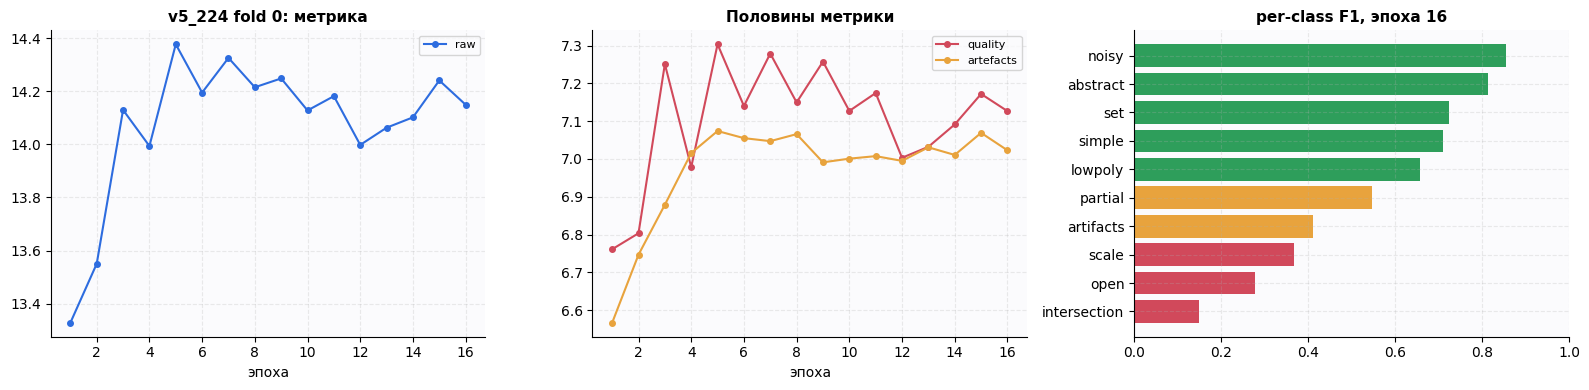

OOF snap1/3 (TTA x2):   0%|          | 0/76 [00:00<?, ?it/s]

test snap1/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap2/3 (TTA x2):   0%|          | 0/76 [00:00<?, ?it/s]

test snap2/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap3/3 (TTA x2):   0%|          | 0/76 [00:00<?, ?it/s]

...

val ep15 (TTA x1):   0%|          | 0/75 [00:00<?, ?it/s]

  ep15/16 | метрика 13.904 (raw) = quality  7.09 + artefacts  6.81 | loss 0.152 | 0.9 мин | ост. 0м 51с
        abstr=0.79  artif=0.33  inter=0.11  lowpo=0.62  noisy=0.85  open=0.37  parti=0.54  scale=0.31  set=0.63  simpl=0.70  quali=0.71
    [зеркало] чекпоинт эпохи 15 -> Drive (222 МБ)


v5_224 f1 ep16/16:   0%|          | 0/598 [00:00<?, ?it/s]

val ep16 (TTA x1):   0%|          | 0/75 [00:00<?, ?it/s]

  ep16/16 | метрика 13.862 (raw) = quality  7.06 + artefacts  6.80 | loss 0.155 | 0.9 мин | ост. 0м 00с
        abstr=0.79  artif=0.33  inter=0.12  lowpo=0.62  noisy=0.84  open=0.36  parti=0.55  scale=0.30  set=0.63  simpl=0.71  quali=0.71
    [зеркало] чекпоинт эпохи 16 -> Drive (222 МБ)


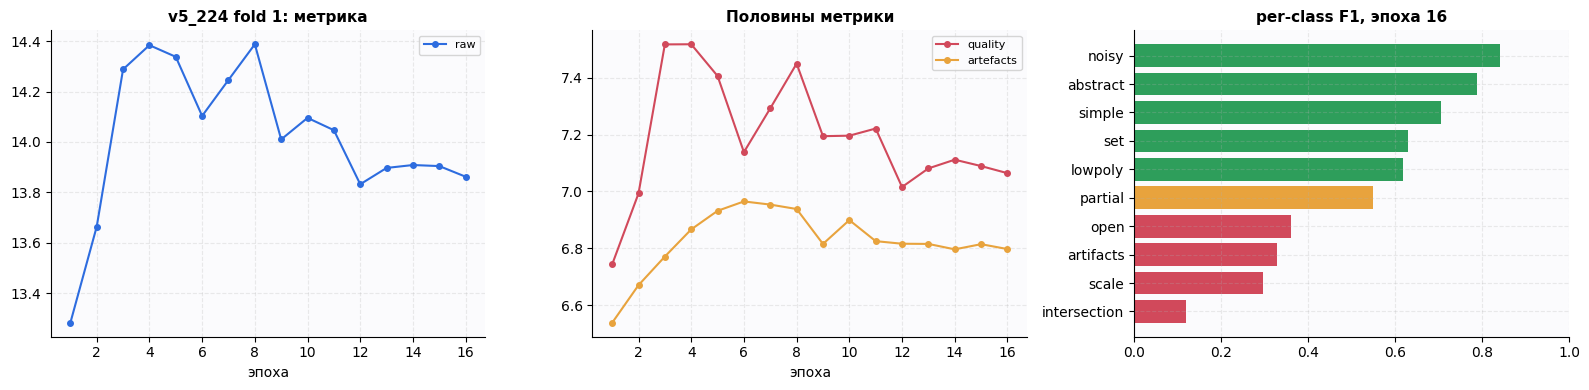

OOF snap1/3 (TTA x2):   0%|          | 0/75 [00:00<?, ?it/s]

test snap1/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap2/3 (TTA x2):   0%|          | 0/75 [00:00<?, ?it/s]

test snap2/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap3/3 (TTA x2):   0%|          | 0/75 [00:00<?, ?it/s]

...

val ep15 (TTA x1):   0%|          | 0/74 [00:00<?, ?it/s]

  ep15/16 | метрика 13.789 (raw) = quality  6.85 + artefacts  6.94 | loss 0.160 | 0.9 мин | ост. 0м 52с
        abstr=0.78  artif=0.28  inter=0.16  lowpo=0.67  noisy=0.84  open=0.36  parti=0.59  scale=0.27  set=0.67  simpl=0.73  quali=0.68
    [зеркало] чекпоинт эпохи 15 -> Drive (222 МБ)


v5_224 f2 ep16/16:   0%|          | 0/599 [00:00<?, ?it/s]

val ep16 (TTA x1):   0%|          | 0/74 [00:00<?, ?it/s]

  ep16/16 | метрика 13.844 (raw) = quality  6.91 + artefacts  6.94 | loss 0.159 | 0.9 мин | ост. 0м 00с
        abstr=0.79  artif=0.30  inter=0.15  lowpo=0.67  noisy=0.84  open=0.35  parti=0.59  scale=0.28  set=0.68  simpl=0.73  quali=0.69
    [зеркало] чекпоинт эпохи 16 -> Drive (222 МБ)


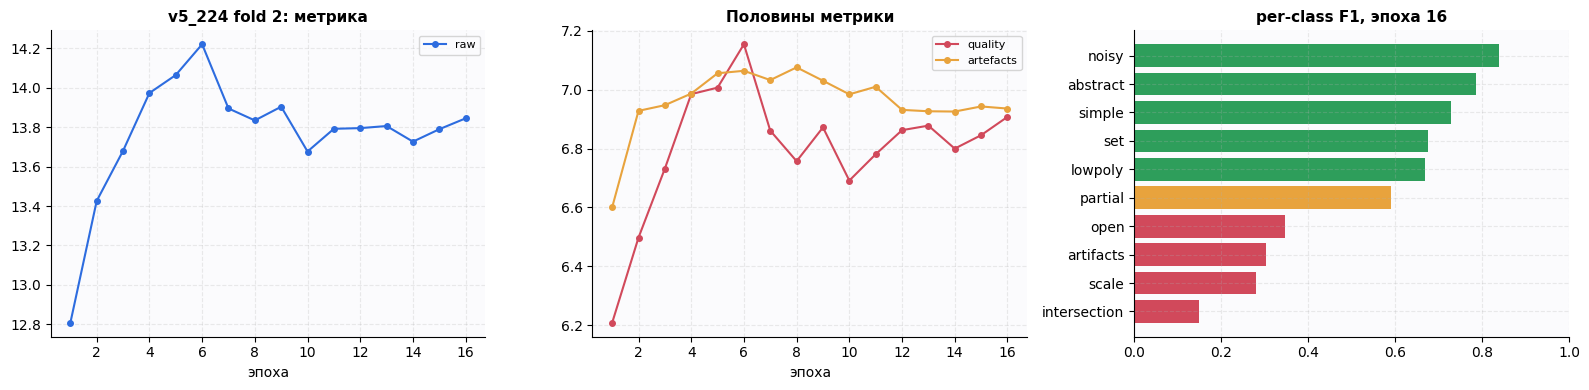

OOF snap1/3 (TTA x2):   0%|          | 0/74 [00:00<?, ?it/s]

test snap1/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap2/3 (TTA x2):   0%|          | 0/74 [00:00<?, ?it/s]

test snap2/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap3/3 (TTA x2):   0%|          | 0/74 [00:00<?, ?it/s]

...

val ep15 (TTA x1):   0%|          | 0/76 [00:00<?, ?it/s]

  ep15/16 | метрика 13.750 (raw) = quality  6.84 + artefacts  6.91 | loss 0.158 | 0.9 мин | ост. 0м 52с
        abstr=0.78  artif=0.31  inter=0.18  lowpo=0.64  noisy=0.86  open=0.34  parti=0.59  scale=0.22  set=0.64  simpl=0.73  quali=0.68
    [зеркало] чекпоинт эпохи 15 -> Drive (222 МБ)


v5_224 f3 ep16/16:   0%|          | 0/596 [00:00<?, ?it/s]

val ep16 (TTA x1):   0%|          | 0/76 [00:00<?, ?it/s]

  ep16/16 | метрика 13.797 (raw) = quality  6.85 + artefacts  6.95 | loss 0.153 | 0.9 мин | ост. 0м 00с
        abstr=0.78  artif=0.31  inter=0.15  lowpo=0.65  noisy=0.86  open=0.35  parti=0.59  scale=0.27  set=0.63  simpl=0.74  quali=0.69
    [зеркало] чекпоинт эпохи 16 -> Drive (222 МБ)


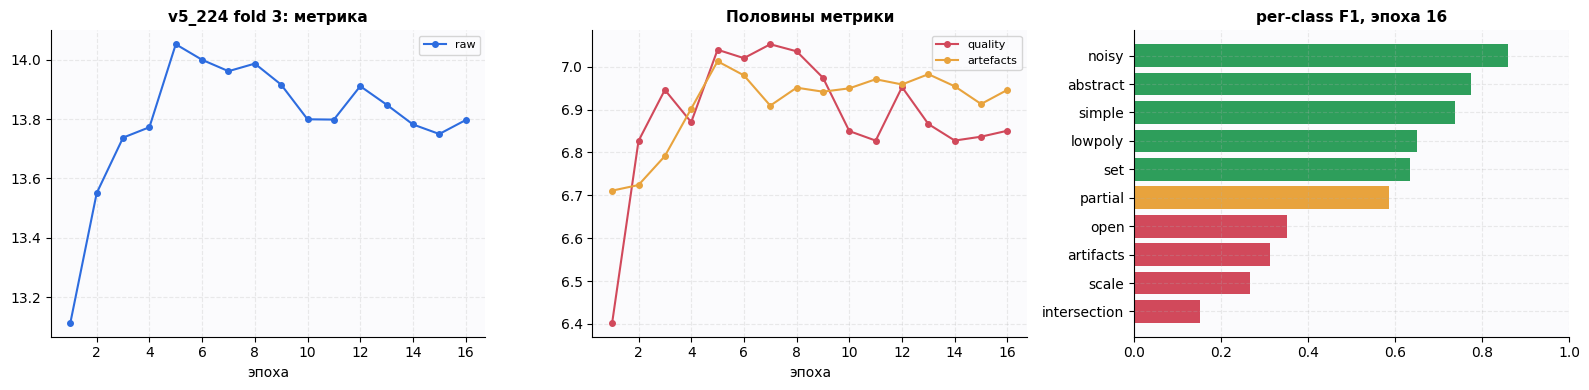

OOF snap1/3 (TTA x2):   0%|          | 0/76 [00:00<?, ?it/s]

test snap1/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap2/3 (TTA x2):   0%|          | 0/76 [00:00<?, ?it/s]

test snap2/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap3/3 (TTA x2):   0%|          | 0/76 [00:00<?, ?it/s]

...

val ep15 (TTA x1):   0%|          | 0/75 [00:00<?, ?it/s]

  ep15/16 | метрика 13.994 (raw) = quality  7.05 + artefacts  6.94 | loss 0.155 | 0.9 мин | ост. 0м 52с
        abstr=0.80  artif=0.35  inter=0.14  lowpo=0.62  noisy=0.85  open=0.34  parti=0.60  scale=0.40  set=0.64  simpl=0.74  quali=0.71
    [зеркало] чекпоинт эпохи 15 -> Drive (222 МБ)


v5_224 f4 ep16/16:   0%|          | 0/597 [00:00<?, ?it/s]

val ep16 (TTA x1):   0%|          | 0/75 [00:00<?, ?it/s]

  ep16/16 | метрика 13.989 (raw) = quality  7.00 + artefacts  6.99 | loss 0.158 | 0.9 мин | ост. 0м 00с
        abstr=0.80  artif=0.36  inter=0.15  lowpo=0.62  noisy=0.85  open=0.35  parti=0.61  scale=0.41  set=0.65  simpl=0.74  quali=0.70
    [зеркало] чекпоинт эпохи 16 -> Drive (222 МБ)


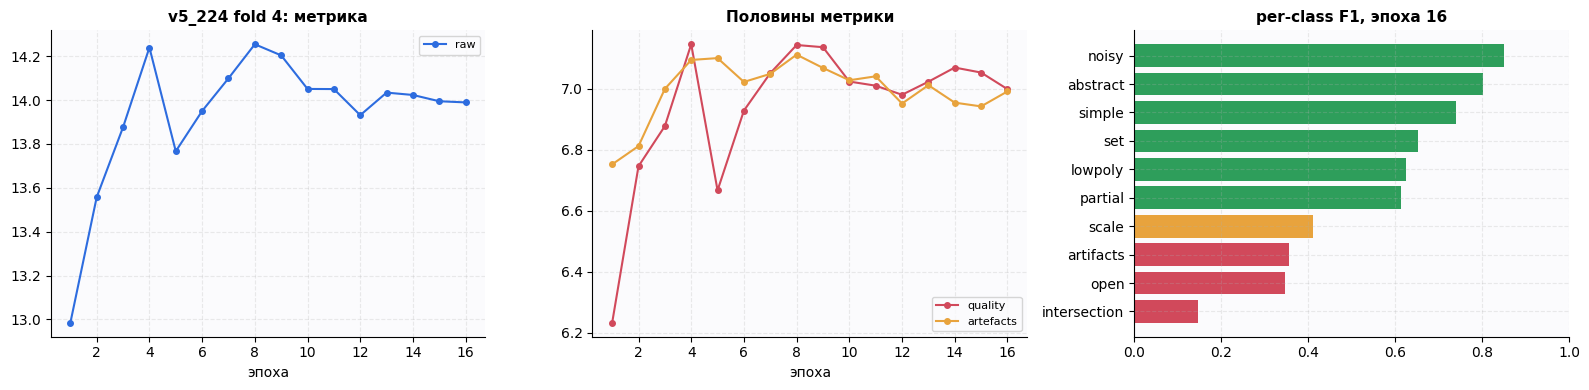

OOF snap1/3 (TTA x2):   0%|          | 0/75 [00:00<?, ?it/s]

test snap1/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap2/3 (TTA x2):   0%|          | 0/75 [00:00<?, ?it/s]

test snap2/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

OOF snap3/3 (TTA x2):   0%|          | 0/75 [00:00<?, ?it/s]

test snap3/3 (TTA x2):   0%|          | 0/28 [00:00<?, ?it/s]

  лучшая эпоха 14.254 -> снапшот-ансамбль + TTA 14.486 (+0.232)
    фолд 4                 |##################..................| 14.486
>>> v5_224: 5/5 фолдов | от старта 9.0 ч
    OOF метрика                      14.266
    по фолдам                        0:14.46, 1:14.71, 2:14.30, 3:14.30, 4:14.49
    ветка v5_224           |################....................| 14.266


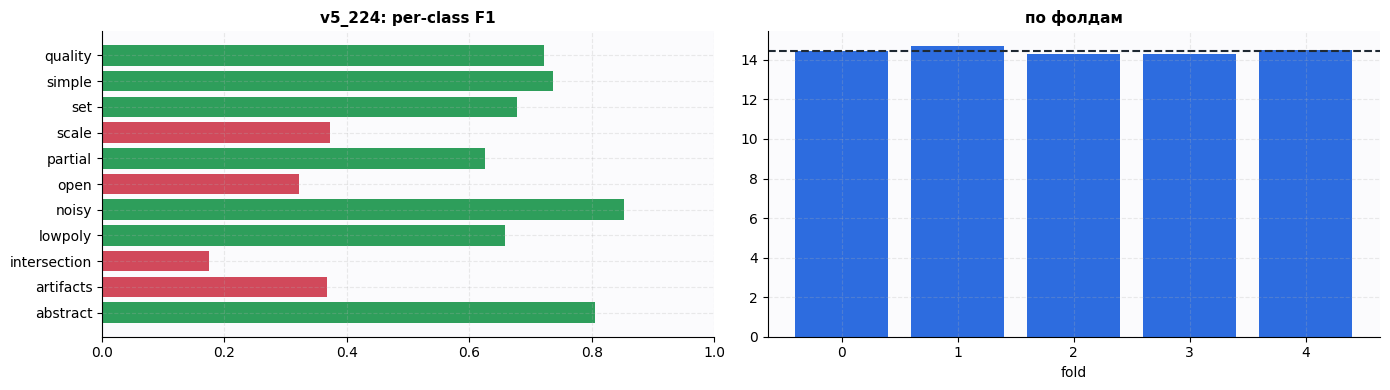

In [27]:
RUNS['v5_224'] = run_branch('v5_224')

### 10.3. Ветка `dino448_s2` — ViT-S/14 DINOv2 @448, attention pooling, EMA

Признаки — из `sber_meshqc_multiview_(21)`: геометрия версии `v3weld` (без
самопересечений, качества треугольников и non-manifold вершин), силуэты тем же проходом,
CLIP по кэшу рендеров @448 и санация с обрезкой по `FEAT_CLIP = 1e9` — та самая, без
которой `inf` в `bbox_fill` ломал статистики BatchNorm гео-ветки.

In [28]:
prepare_branch('dino448_s2')


  ПОДГОТОВКА ВЕТКИ dino448_s2
  vit_small_patch14_reg4_dinov2 @ 448 | 16 эпох | batch 6x1 | вес в ансамбле 1.0


cache train:   0%|          | 0/8964 [00:00<?, ?it/s]

train: закэшировано 8964/8964
train: всего в кэше 8964/8964, нет картинки у 0


cache test:   0%|          | 0/669 [00:00<?, ?it/s]

test: закэшировано 669/669
test: всего в кэше 669/669, нет картинки у 0
  [+] рендеры готовы — выполните ячейку признаков этой ветки


In [29]:
import os, gc, math, numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
from scipy import ndimage
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import ConvexHull, QhullError
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures.process import BrokenProcessPool
import multiprocessing as mp

FACE_CAP  = 300_000
VERT_CAP  = 200_000
HULL_CAP  = 20_000
COMP_CAP  = 3_000_000
WELD_TOL  = 1e-6         # доля диагонали bbox
FEAT_VER  = 'v3weld'     # версия набора фич: входит в имя кэша, чтобы старый parquet
                         # (посчитанный БЕЗ сварки вершин) не подхватился молча
N_WORKERS = min(4, os.cpu_count() or 2)
CHUNK     = 1024

def _pack21(q):
    """Три целых из [0, 2**21) -> один int64. Точно, без коллизий."""
    return (q[:, 0] << 42) | (q[:, 1] << 21) | q[:, 2]

def _hash3(q):
    q = q.astype(np.int64, copy=False)
    return (q[:, 0] * 73856093) ^ (q[:, 1] * 19349663) ^ (q[:, 2] * 83492791)

def _stats(x, pref):
    keys = ['mean', 'std', 'p10', 'p50', 'p90', 'max', 'cv']
    if len(x) == 0:
        return {f'{pref}_{k}': 0.0 for k in keys}
    x = np.asarray(x, dtype=np.float32)
    m, s = float(x.mean()), float(x.std())
    q10, q50, q90 = np.percentile(x, [10, 50, 90])
    return {f'{pref}_mean': m, f'{pref}_std': s, f'{pref}_p10': float(q10),
            f'{pref}_p50': float(q50), f'{pref}_p90': float(q90),
            f'{pref}_max': float(x.max()), f'{pref}_cv': float(s / (abs(m) + 1e-9))}

def _edge_table(Fi, nfw):
    """Рёбра -> (номер группы, число граней на ребро, отсортированные id граней)."""
    E = np.concatenate([Fi[:, [0, 1]], Fi[:, [1, 2]], Fi[:, [2, 0]]], 0)
    E.sort(axis=1)
    fid = np.tile(np.arange(nfw, dtype=np.int32), 3)
    order = np.lexsort((E[:, 1], E[:, 0]))
    Es, fids = E[order], fid[order]
    new = np.ones(len(Es), dtype=bool)
    new[1:] = (Es[1:] != Es[:-1]).any(1)
    grp = np.cumsum(new) - 1
    counts = np.bincount(grp)
    return E, Es, fids, grp, counts, new

def mesh_features(npz_path):
    f = {'geo_ok': 0.0, 'geo_subsampled': 0.0}
    try:
        f['npz_mb'] = os.path.getsize(npz_path) / 1e6
    except Exception:
        return f
    try:
        with np.load(npz_path, allow_pickle=False) as d:
            keys = list(d.keys())
            V = np.asarray(d['vertices' if 'vertices' in keys else keys[0]], dtype=np.float32)
            Fc = None
            for k in ('faces', 'triangles', 'f'):
                if k in keys:
                    Fc = np.asarray(d[k], dtype=np.int64); break
            if Fc is None and len(keys) > 1:
                Fc = np.asarray(d[keys[1]], dtype=np.int64)
    except Exception:
        return f
    if V.ndim != 2 or V.shape[1] != 3 or len(V) == 0:
        return f
    if Fc is None or Fc.ndim != 2 or Fc.shape[1] != 3 or len(Fc) == 0:
        Fc = np.zeros((0, 3), dtype=np.int64)
    else:
        Fc = Fc[(Fc >= 0).all(1) & (Fc < len(V)).all(1)]

    f['geo_ok'] = 1.0
    nv_raw, nf_raw = len(V), len(Fc)
    vmin, vmax = V.min(0), V.max(0)
    ext = (vmax - vmin).astype(np.float64)
    ext_s = np.sort(ext)[::-1]
    diag = float(np.linalg.norm(ext)) + 1e-12
    center = ((vmin + vmax) / 2).astype(np.float32)
    inv_s = np.float32(1.0 / diag)
    f.update({'n_verts_raw': float(nv_raw), 'n_faces': float(nf_raw),
              'log_verts': math.log1p(nv_raw), 'log_faces': math.log1p(nf_raw),
              'ext_max': float(ext_s[0]), 'ext_mid': float(ext_s[1]), 'ext_min': float(ext_s[2]),
              'ext_ratio_min': float(ext_s[2] / (ext_s[0] + 1e-12)),
              'ext_ratio_mid': float(ext_s[1] / (ext_s[0] + 1e-12)),
              'bbox_diag': diag,
              'bbox_fill': float(nv_raw / (ext.prod() + 1e-12)) if ext.prod() > 0 else 0.0})

    # ================== СВАРКА ВЕРШИН ==================
    # Экспортёры (glTF/OBJ с раздельными нормалями и UV) дублируют вершины на каждую грань.
    # Без сварки НИ ОДНО ребро не имеет двух граней: двугранные углы пусты, boundary=1.0,
    # компонент столько же, сколько треугольников. Вся топология обязана считаться после сварки.
    step = np.float32(diag * WELD_TOL)
    q = np.clip(np.rint((V - vmin) / step), 0, (1 << 21) - 1).astype(np.int64)
    code = _pack21(q)
    del q
    ucode, first, invmap = np.unique(code, return_index=True, return_inverse=True)
    del code, ucode
    nv = len(first)
    f['n_verts'] = float(nv)
    f['weld_ratio'] = float(1.0 - nv / max(nv_raw, 1))          # 0 = уже сварен, ~0.83 = по 3 вершины на грань
    f['f_per_v'] = nf_raw / max(nv, 1)
    Vw_full = V[first]
    del first

    if nf_raw:
        Fw = invmap[Fc]
        ok = (Fw[:, 0] != Fw[:, 1]) & (Fw[:, 1] != Fw[:, 2]) & (Fw[:, 0] != Fw[:, 2])
        f['degen_after_weld'] = float(1.0 - ok.mean())
        Fw = Fw[ok]
        hf = _hash3(np.sort(Fw, axis=1))
        _, uidx = np.unique(hf, return_index=True)
        f['dup_face_ratio'] = float(1.0 - len(uidx) / max(len(Fw), 1))
        Fw = Fw[np.sort(uidx)]
        del hf, uidx, ok
    else:
        Fw = np.zeros((0, 3), dtype=np.int64)
        f['degen_after_weld'] = 0.0; f['dup_face_ratio'] = 0.0
    del invmap, Fc
    nf = len(Fw)

    # ---- вершинные статистики (подвыборка) ----
    Vs = Vw_full[::max(1, int(np.ceil(nv / VERT_CAP)))]
    if nv > VERT_CAP:
        f['geo_subsampled'] = 1.0
    Vs = (Vs - center) * inv_s
    try:
        if len(Vs) < 3:
            raise ValueError('too few vertices')
        ev = np.clip(np.linalg.eigvalsh(np.cov(Vs.T.astype(np.float64)))[::-1], 1e-16, None)
        f.update({'pca_1': float(ev[0]), 'pca_2': float(ev[1]), 'pca_3': float(ev[2]),
                  'pca_flat': float(ev[2] / ev[0]), 'pca_lin': float(ev[1] / ev[0]),
                  'pca_aniso': float((ev[0] - ev[2]) / ev.sum())})
    except Exception:
        f.update({k: 0.0 for k in ['pca_1', 'pca_2', 'pca_3', 'pca_flat', 'pca_lin', 'pca_aniso']})

    # ---- выпуклая оболочка: solidity/сферичность -> simple, open ----
    f.update({'hull_ok': 0.0, 'solidity': 0.0, 'solidity_signed': 0.0, 'hull_area_ratio': 0.0,
              'hull_pts_frac': 0.0, 'sphericity': 0.0, 'hull_vol': 0.0, 'hull_area': 0.0})
    try:
        Vh = Vs[::max(1, int(np.ceil(len(Vs) / HULL_CAP)))].astype(np.float64)
        if len(Vh) >= 8:
            hull = ConvexHull(Vh, qhull_options='QJ')
            f['hull_ok'] = 1.0
            f['hull_vol'] = float(hull.volume)
            f['hull_pts_frac'] = len(hull.vertices) / len(Vh)
            f['hull_area'] = float(hull.area)
    except (QhullError, ValueError, MemoryError):
        pass

    if nf == 0:
        f['no_faces'] = 1.0
        f.update({'area_total': 0.0, 'volume': 0.0, 'abs_volume': 0.0, 'vol_ratio': 0.0,
                  'vol_over_area': 0.0, 'absvol_over_area': 0.0, 'vol_over_bbox': 0.0,
                  'absvol_over_bbox': 0.0})
        for pref in ('dihed', 'dihedf', 'farea', 'elen', 'aspect', 'valence', 'defect'):
            f.update(_stats([], pref))
        return f
    f['no_faces'] = 0.0

    # ---- точные площадь/объём по полному сваренному мешу ----
    total_area, vol6, absvol6 = 0.0, 0.0, 0.0
    for s0 in range(0, nf, 500_000):
        Pc = ((Vw_full[Fw[s0:s0 + 500_000]] - center) * inv_s).astype(np.float64)
        cr_c = np.cross(Pc[:, 1] - Pc[:, 0], Pc[:, 2] - Pc[:, 0])
        total_area += 0.5 * float(np.linalg.norm(cr_c, axis=1).sum())
        contrib = (Pc[:, 0] * np.cross(Pc[:, 1], Pc[:, 2])).sum(1)
        vol6 += float(contrib.sum()); absvol6 += float(np.abs(contrib).sum())
        del Pc, cr_c, contrib
    total_area += 1e-12
    vol = abs(vol6 / 6.0)
    absvol = absvol6 / 6.0
    # vol_ratio ~1 у корректно ориентированного меша и ~0 при несогласованной намотке граней
    # (сама по себе сильная улика для artifacts/noisy). Объём для solidity берём устойчивый.
    f.update({'area_total': total_area, 'volume': vol, 'abs_volume': absvol,
              'vol_ratio': vol / (absvol + 1e-12),
              'vol_over_area': vol / (total_area ** 1.5 + 1e-12),
              'absvol_over_area': absvol / (total_area ** 1.5 + 1e-12),
              'vol_over_bbox': vol / (float(np.prod(ext * inv_s)) + 1e-12),
              'absvol_over_bbox': absvol / (float(np.prod(ext * inv_s)) + 1e-12)})
    if f['hull_ok']:
        f['solidity'] = absvol / (f['hull_vol'] + 1e-12)
        f['solidity_signed'] = vol / (f['hull_vol'] + 1e-12)
        f['hull_area_ratio'] = total_area / (f.get('hull_area', 0.0) + 1e-12)
        f['sphericity'] = (math.pi ** (1 / 3)) * (6 * absvol) ** (2 / 3) / (total_area + 1e-12)

    # ---- компоненты связности на полном СВАРЕННОМ меше ----
    f.update({'n_comp': 1.0, 'n_comp_big': 1.0, 'comp_top1': 1.0, 'comp_top2': 0.0,
              'comp_entropy': 0.0, 'bbox_iou_max': 0.0, 'bbox_iou_mean': 0.0,
              'bbox_iou_frac_pos': 0.0, 'comp_sep_max': 0.0, 'comp_sep_mean': 0.0,
              'inside_frac_max': 0.0, 'comp_exact': 1.0})
    if nf <= COMP_CAP:
        try:
            Ef = np.concatenate([Fw[:, [0, 1]], Fw[:, [1, 2]], Fw[:, [2, 0]]], 0).astype(np.int32)
            A = coo_matrix((np.ones(len(Ef), dtype=np.int8), (Ef[:, 0], Ef[:, 1])), shape=(nv, nv))
            del Ef
            ncomp, lab = connected_components(A, directed=False)
            del A
            used = np.unique(Fw)
            sizes_all = np.bincount(lab[used], minlength=ncomp).astype(np.float64)
            sizes = np.sort(sizes_all[sizes_all > 0])[::-1]
            tot = sizes.sum()
            big_idx = np.where(sizes_all > 0.005 * tot)[0]
            f.update({'n_comp': float(len(sizes)), 'n_comp_big': float(len(big_idx)),
                      'comp_top1': float(sizes[0] / tot),
                      'comp_top2': float(sizes[1] / tot) if len(sizes) > 1 else 0.0,
                      'comp_entropy': float(-((sizes / tot) * np.log(sizes / tot + 1e-12)).sum())})
            if len(big_idx) > 1:
                top = big_idx[np.argsort(-sizes_all[big_idx])][:8]
                pts_l, boxes = [], []
                for c in top:
                    ic = used[lab[used] == c]
                    if len(ic) > 20_000:
                        ic = ic[::len(ic) // 20_000 + 1]
                    p = (Vw_full[ic] - center) * inv_s
                    pts_l.append(p); boxes.append((p.min(0), p.max(0)))
                ious, seps, insides = [], [], []
                for i in range(len(boxes)):
                    for j in range(len(boxes)):
                        if i == j:
                            continue
                        lo, hi = boxes[j]
                        insides.append(float(((pts_l[i] >= lo) & (pts_l[i] <= hi)).all(1).mean()))
                        if j <= i:
                            continue
                        lo2 = np.maximum(boxes[i][0], boxes[j][0])
                        hi2 = np.minimum(boxes[i][1], boxes[j][1])
                        it = float(np.prod(np.clip(hi2 - lo2, 0, None)))
                        vi = float(np.prod(np.clip(boxes[i][1] - boxes[i][0], 1e-6, None)))
                        vj = float(np.prod(np.clip(boxes[j][1] - boxes[j][0], 1e-6, None)))
                        ious.append(it / (vi + vj - it + 1e-12))
                        seps.append(float(np.linalg.norm(
                            (boxes[i][0] + boxes[i][1]) / 2 - (boxes[j][0] + boxes[j][1]) / 2)))
                f.update({'bbox_iou_max': float(max(ious)), 'bbox_iou_mean': float(np.mean(ious)),
                          'bbox_iou_frac_pos': float(np.mean(np.asarray(ious) > 1e-6)),
                          'comp_sep_max': float(max(seps)), 'comp_sep_mean': float(np.mean(seps)),
                          'inside_frac_max': float(max(insides))})
            del lab, sizes_all, sizes, used
        except Exception:
            f['comp_exact'] = 0.0
    else:
        f['comp_exact'] = 0.0

    # ---- пространственный патч для рёберной топологии ----
    if nf > FACE_CAP:
        f['geo_subsampled'] = 1.0
        anchor = (Vw_full[Fw[:, 0]] - vmin) / (ext.astype(np.float32) + 1e-9)
        Fp, g = None, 1
        while g < 40:
            g += 1
            cid = np.minimum((anchor * g).astype(np.int32), g - 1)
            key = (cid[:, 0] * g + cid[:, 1]) * g + cid[:, 2]
            cnt = np.bincount(key, minlength=g ** 3)
            best = int(np.argmax(cnt))
            if cnt[best] <= FACE_CAP:
                Fp = Fw[key == best]; break
        if Fp is None or len(Fp) < 1000:
            Fp = Fw[:FACE_CAP]
        f['patch_grid'] = float(g)
        del anchor
    else:
        Fp = Fw
        f['patch_grid'] = 1.0
    f['patch_face_frac'] = len(Fp) / max(nf, 1)
    del Fw
    nfw = len(Fp)

    uvp, Fi = np.unique(Fp, return_inverse=True)
    Fi = Fi.reshape(nfw, 3).astype(np.int32)
    Vp = ((Vw_full[uvp] - center) * inv_s).astype(np.float32)
    nvp = len(uvp)
    del uvp, Fp, Vw_full, V

    P = Vp[Fi]
    cr = np.cross(P[:, 1] - P[:, 0], P[:, 2] - P[:, 0])
    area2 = np.linalg.norm(cr, axis=1)
    area = 0.5 * area2
    nrm = cr / (area2[:, None] + 1e-12)
    del cr
    f.update(_stats(area / (area.mean() + 1e-12), 'farea'))
    f['degenerate_ratio'] = float((area < 1e-10).mean())

    L = np.stack([np.linalg.norm(P[:, 1] - P[:, 0], axis=1),
                  np.linalg.norm(P[:, 2] - P[:, 1], axis=1),
                  np.linalg.norm(P[:, 0] - P[:, 2], axis=1)], 1)
    f.update(_stats(L.ravel() / (L.mean() + 1e-12), 'elen'))
    aspect = L.max(1) / (L.min(1) + 1e-12)
    f.update(_stats(np.log1p(aspect), 'aspect'))
    f['sliver_ratio'] = float((aspect > 20).mean())

    for qd in (1, 2):
        f[f'uniq_normals_q{qd}'] = len(np.unique(_hash3(np.rint(nrm * 10 ** qd)))) / nfw
    # концентрация нормалей: доля площади в 6 крупнейших кластерах -> примитивы
    hn = _hash3(np.rint(nrm * 20))
    _, ninv = np.unique(hn, return_inverse=True)
    mass = np.bincount(ninv, weights=area)
    mass = np.sort(mass)[::-1]
    f['normal_top6_mass'] = float(mass[:6].sum() / (mass.sum() + 1e-12))
    f['normal_top1_mass'] = float(mass[0] / (mass.sum() + 1e-12))
    del hn, ninv, mass

    # ---- рёбра/углы ПОСЛЕ сварки + диагностика "как было бы БЕЗ сварки" ----
    E, Es, fids, grp, counts, _ = _edge_table(Fi, nfw)
    n_edges = len(counts)
    f.update({'n_edges': float(n_edges),
              'boundary_edge_ratio': float((counts == 1).mean()),
              'nonmanifold_edge_ratio': float((counts >= 3).mean()),
              'euler_norm': float((nvp - n_edges + nfw) / max(nfw, 1)),
              'euler_char': float(nvp - n_edges + nfw),
              'watertight': float((counts == 1).sum() == 0 and (counts >= 3).sum() == 0),
              'manifold_edge_ratio': float((counts == 2).mean())})

    # число граничных петель -> сколько «дыр» в поверхности (open)
    bnd = np.where(counts == 1)[0]
    if len(bnd):
        st = np.searchsorted(grp, bnd)
        be = Es[st]
        try:
            Ab = coo_matrix((np.ones(len(be), dtype=np.int8), (be[:, 0], be[:, 1])), shape=(nvp, nvp))
            nb_comp, lb = connected_components(Ab, directed=False)
            used_b = np.unique(be)
            f['n_boundary_loops'] = float(len(np.unique(lb[used_b])))
            f['boundary_vert_frac'] = float(len(used_b) / nvp)
            del Ab, lb, used_b
        except Exception:
            f['n_boundary_loops'] = 0.0; f['boundary_vert_frac'] = 0.0
        del be, st
    else:
        f['n_boundary_loops'] = 0.0; f['boundary_vert_frac'] = 0.0

    two = np.where(counts == 2)[0]
    if len(two):
        st = np.searchsorted(grp, two)
        fa, fb = fids[st], fids[st + 1]
        cosang = np.clip((nrm[fa] * nrm[fb]).sum(1), -1, 1)
        ang = np.degrees(np.arccos(cosang))
        angf = np.degrees(np.arccos(np.abs(cosang)))
        f.update(_stats(ang, 'dihed')); f.update(_stats(angf, 'dihedf'))
        for t in (10, 30, 60, 90):
            f[f'dihed_gt{t}'] = float((ang > t).mean())
        for t in (5, 15, 30, 60):
            f[f'dihedf_gt{t}'] = float((angf > t).mean())
        f['flip_ratio'] = float((cosang < 0).mean())
        hist = np.bincount((angf / 5).astype(np.int32).clip(0, 17), minlength=18).astype(np.float64)
        p = hist / max(hist.sum(), 1)
        f['dihed_entropy'] = float(-(p[p > 0] * np.log(p[p > 0])).sum())
        f['smoothness'] = float(angf.mean() * math.sqrt(nfw) / 100.0)
        # взвешенный по длине ребра угол: устойчивее к мелким треугольникам
        el = np.linalg.norm(Vp[Es[st][:, 0]] - Vp[Es[st][:, 1]], axis=1)
        f['dihedf_areaw'] = float((angf * el).sum() / (el.sum() + 1e-12))
        del fa, fb, cosang, ang, angf, el
    else:
        f.update(_stats([], 'dihed')); f.update(_stats([], 'dihedf'))
        for t in (10, 30, 60, 90):
            f[f'dihed_gt{t}'] = 0.0
        for t in (5, 15, 30, 60):
            f[f'dihedf_gt{t}'] = 0.0
        f.update({'flip_ratio': 0.0, 'dihed_entropy': 0.0, 'smoothness': 0.0, 'dihedf_areaw': 0.0})

    # ---- валентность вершин и угловой дефект (гауссова кривизна) ----
    val = np.bincount(Fi.ravel(), minlength=nvp).astype(np.float32)
    f.update(_stats(val, 'valence'))
    f['valence_le3'] = float((val <= 3).mean())
    f['valence_ge8'] = float((val >= 8).mean())
    e01 = P[:, 1] - P[:, 0]; e12 = P[:, 2] - P[:, 1]; e20 = P[:, 0] - P[:, 2]
    def _ang(u, v):
        cu = (u * v).sum(1) / (np.linalg.norm(u, axis=1) * np.linalg.norm(v, axis=1) + 1e-12)
        return np.arccos(np.clip(cu, -1, 1))
    a0 = _ang(e01, -e20); a1 = _ang(e12, -e01); a2 = _ang(e20, -e12)
    defect = np.full(nvp, 2 * np.pi, dtype=np.float64)
    np.subtract.at(defect, Fi[:, 0], a0)
    np.subtract.at(defect, Fi[:, 1], a1)
    np.subtract.at(defect, Fi[:, 2], a2)
    interior = val > 0
    f.update(_stats(np.abs(defect[interior]), 'defect'))
    f['defect_sum'] = float(defect[interior].sum() / (2 * np.pi))     # ~ эйлерова характеристика
    f['defect_gt05'] = float((np.abs(defect[interior]) > 0.5).mean())
    del defect, val, a0, a1, a2, e01, e12, e20

    del E, Es, fids, grp, counts, two, nrm, P, Vp, Fi, L, aspect, area, area2
    return f

In [30]:
def image_features(png_path):
    f = {'img_ok': 0.0}
    try:
        img = Image.open(png_path).convert('L')
    except Exception:
        return f
    a = np.asarray(img, dtype=np.float32) / 255.0
    t = CFG.tile
    f['img_ok'] = 1.0
    covs, comps, edens, stds, bws, bhs = [], [], [], [], [], []
    for k in range(6):
        v = a[(k // 3) * t:(k // 3 + 1) * t, (k % 3) * t:(k % 3 + 1) * t]
        bg = np.median(np.concatenate([v[0], v[-1], v[:, 0], v[:, -1]]))
        mask = np.abs(v - bg) > 0.06
        cov = float(mask.mean()); covs.append(cov)
        if mask.any():
            ys, xs = np.where(mask)
            bws.append((xs.max() - xs.min() + 1) / t)
            bhs.append((ys.max() - ys.min() + 1) / t)
            lab, ncc = ndimage.label(mask)
            if ncc:
                sz = np.bincount(lab.ravel())[1:]
                comps.append(float((sz > 0.01 * sz.sum()).sum()))
            else:
                comps.append(0.0)
        else:
            bws.append(0.0); bhs.append(0.0); comps.append(0.0)
        edens.append(float(np.abs(np.diff(v, axis=1)).mean() + np.abs(np.diff(v, axis=0)).mean()))
        stds.append(float(v.std()))
    def agg(vals, pref):
        v = np.asarray(vals, dtype=np.float64)
        return {f'{pref}_mean': v.mean(), f'{pref}_min': v.min(), f'{pref}_max': v.max(),
                f'{pref}_std': v.std(), f'{pref}_range': v.max() - v.min()}
    f.update(agg(covs, 'cov')); f.update(agg(comps, 'ncc')); f.update(agg(edens, 'edge'))
    f.update(agg(stds, 'pxstd')); f.update(agg(bws, 'bw')); f.update(agg(bhs, 'bh'))
    f['cov_empty_views'] = float((np.asarray(covs) < 0.01).sum())
    f['bbox_fill_view'] = float(np.mean(np.asarray(covs) /
                                        (np.asarray(bws) * np.asarray(bhs) + 1e-6)))
    return f

def _feat_one(args):
    iid, npz, png = args
    d = {'item_id': iid}
    try:
        d.update(mesh_features(npz))
    except (MemoryError, Exception):
        d['geo_ok'] = 0.0
    try:
        d.update(image_features(png))
    except Exception:
        d['img_ok'] = 0.0
    return d

def build_features(ids, npz_dir, img_dir, split):
    """Чанками, с чекпоинтом и резюмированием. Повторный запуск после падения
    продолжает с последнего сохранённого чанка."""
    final = CFG.cache / f'feats_{split}_{CFG.tile}_{FEAT_VER}.parquet'
    ckpt  = CFG.cache / f'feats_{split}_{CFG.tile}_{FEAT_VER}_partial.parquet'
    if final.exists():
        df = pd.read_parquet(final); print(f'{split}: фичи из кэша {df.shape}'); return df

    done = pd.read_parquet(ckpt) if ckpt.exists() else pd.DataFrame(columns=['item_id'])
    have = set(done['item_id'].astype(str)) if len(done) else set()
    todo = [i for i in ids if i not in have]
    print(f'{split}: уже готово {len(have)}, осталось {len(todo)}, воркеров {N_WORKERS}')

    rows = [done] if len(done) else []
    for s in range(0, len(todo), CHUNK):
        part = todo[s:s + CHUNK]
        jobs = [(i, str(Path(npz_dir) / f'{i}.npz'), str(Path(img_dir) / f'{i}.png')) for i in part]
        # ВАЖНО: max_tasks_per_child переключает старт-метод на 'spawn', а при spawn воркер
        # заново импортирует __main__ — в ноутбуке там пусто, функция не находится и пул падает
        # (в прошлом прогоне так упал КАЖДЫЙ чанк, всё считалось последовательно).
        # Явно требуем 'fork': воркер наследует определения ячейки.
        try:
            ctx = mp.get_context('fork')
        except ValueError:
            ctx = None
        try:
            with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
                got = list(tqdm(ex.map(_feat_one, jobs, chunksize=4), total=len(jobs),
                                desc=f'{split} {s + len(part)}/{len(todo)}', leave=False))
        except (BrokenProcessPool, OSError, MemoryError) as e:
            print(f'  пул упал ({type(e).__name__}), чанк считается последовательно')
            got = [_feat_one(j) for j in tqdm(jobs, desc='serial', leave=False)]
        rows.append(pd.DataFrame(got))
        _atomic(ckpt, lambda p: pd.concat(rows, ignore_index=True).to_parquet(p, index=False))
        gc.collect()

    df = pd.concat(rows, ignore_index=True).drop_duplicates('item_id')
    df = df.set_index('item_id').reindex([str(i) for i in ids]).reset_index()
    df = df.fillna(0.0)
    _atomic(final, lambda p: df.to_parquet(p, index=False))
    if ckpt.exists():
        ckpt.unlink()
    print(f'{split}: фичи посчитаны {df.shape}')
    return df

feat_tr = build_features(train_df['item_id'].tolist(), TRAIN_DIR, IMG_TRAIN, 'train')
feat_te = build_features(test_df['item_id'].tolist(),  TEST_DIR,  IMG_TEST,  'test')

train: уже готово 0, осталось 8964, воркеров 4


train 1024/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

train 2048/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

train 3072/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

train 4096/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

...

train 8192/8964:   0%|          | 0/1024 [00:00<?, ?it/s]

train 8964/8964:   0%|          | 0/772 [00:00<?, ?it/s]

train: фичи посчитаны (8964, 170)
test: уже готово 0, осталось 669, воркеров 4


test 669/669:   0%|          | 0/669 [00:00<?, ?it/s]

test: фичи посчитаны (669, 170)


In [31]:
CLIP_PROMPTS = {
    # --- то, что размечено как abstract ---
    'abs_text':     ['3D text lettering', 'a sign with written words', 'an extruded logo'],
    'abs_chart':    ['a bar chart', 'a pie chart', 'a graph plot', 'a diagram', 'a flowchart',
                     'a table with data', 'an infographic'],
    'abs_support':  ['3D printing support structure', 'scaffolding lattice'],
    'abs_voxel':    ['minecraft voxel blocks', 'blocky pixelated cubes'],
    # --- предметные объекты: контраст к abstract ---
    'obj_single':   ['a 3D model of a single object', 'a product render on white background'],
    'obj_semantic': ['a chair', 'a car', 'a building', 'a plant', 'a character figure',
                     'a tool', 'furniture'],
    # --- прокси для остальных классов ---
    'p_lowpoly':    ['a low-poly 3D model with visible flat facets'],
    'p_noisy':      ['a noisy 3D scan with rough surface', 'a point cloud scan'],
    'p_broken':     ['a broken mesh with holes and artifacts'],
    'p_hollow':     ['a hollow thin shell', 'a flat plane'],
    'p_multi':      ['several separate objects scattered apart', 'a collection of many objects'],
    'p_small':      ['a tiny object in the middle of a large empty frame'],
    'p_smooth':     ['a smooth clean 3D render of one object'],
}

def compute_clip_features(ids, img_dir, split):
    import open_clip
    name, pretrained = CFG.clip_model
    model, _, _ = open_clip.create_model_and_transforms(name, pretrained=pretrained)
    tokenizer = open_clip.get_tokenizer(name)
    model = model.to(CFG.device).eval()

    groups = list(CLIP_PROMPTS)
    flat, owner = [], []
    for g in groups:
        flat += CLIP_PROMPTS[g]; owner += [g] * len(CLIP_PROMPTS[g])
    with torch.no_grad():
        tf = model.encode_text(tokenizer(flat).to(CFG.device)).float()
        tf = tf / tf.norm(dim=-1, keepdim=True)
    owner = np.array(owner)

    size = model.visual.image_size
    size = size[0] if isinstance(size, (tuple, list)) else int(size)
    mean = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=CFG.device).view(1, 3, 1, 1)
    std = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=CFG.device).view(1, 3, 1, 1)

    rows, bs = [], 24
    for s0 in tqdm(range(0, len(ids), bs), desc=f'CLIP {split}'):
        chunk = ids[s0:s0 + bs]
        batch = []
        for iid in chunk:
            p = Path(img_dir) / f'{iid}.png'
            if p.exists():
                vs = [np.asarray(v.resize((size, size), Image.BILINEAR), dtype=np.uint8)
                      for v in split_views(Image.open(p).convert('RGB'))]
            else:
                vs = [np.full((size, size, 3), 255, np.uint8)] * 6
            batch.append(np.stack(vs))
        x = torch.from_numpy(np.stack(batch)).to(CFG.device)           # (B,6,size,size,3)
        B = x.shape[0]
        x = x.permute(0, 1, 4, 2, 3).reshape(B * 6, 3, size, size).float() / 255.0
        x = (x - mean) / std
        with torch.no_grad():
            im = model.encode_image(x).float()
        im = im / im.norm(dim=-1, keepdim=True)
        sim = (im @ tf.T).view(B, 6, -1).cpu().numpy()

        gsim = np.stack([sim[:, :, owner == g].max(-1) for g in groups], -1)   # (B,6,n_groups)
        feat = {}
        for j, g in enumerate(groups):
            v = gsim[:, :, j]
            feat[f'clip_{g}_mean'] = v.mean(1)
            feat[f'clip_{g}_max'] = v.max(1)
            feat[f'clip_{g}_std'] = v.std(1)
        abs_max = np.stack([feat[f'clip_{g}_max'] for g in groups if g.startswith('abs_')], 1).max(1)
        obj_max = np.stack([feat[f'clip_{g}_max'] for g in groups if g.startswith('obj_')], 1).max(1)
        def_max = np.stack([feat[f'clip_{g}_max'] for g in groups
                            if g.startswith('p_') and g != 'p_smooth'], 1).max(1)
        feat['clip_abstract_margin'] = abs_max - obj_max
        feat['clip_abstract_prob'] = 1 / (1 + np.exp(-100 * (abs_max - obj_max)))
        feat['clip_defect_margin'] = def_max - feat['clip_p_smooth_max']
        rows.append(pd.DataFrame(feat, index=list(chunk)))
    del model
    gc.collect(); torch.cuda.empty_cache()
    return pd.concat(rows).rename_axis('item_id').reset_index()

if CFG.use_clip:
    clip_tr = cached(f'clip_train_{CFG.clip_model[0]}_{CFG.run_tag}',
                     lambda: compute_clip_features(train_df['item_id'].tolist(), IMG_TRAIN, 'train'))
    clip_te = cached(f'clip_test_{CFG.clip_model[0]}_{CFG.run_tag}',
                     lambda: compute_clip_features(test_df['item_id'].tolist(), IMG_TEST, 'test'))
    feat_tr = feat_tr.merge(clip_tr, on='item_id', how='left')
    feat_te = feat_te.merge(clip_te, on='item_id', how='left')
    print('добавлено CLIP-признаков:', clip_tr.shape[1] - 1)

    _m = train_df.merge(clip_tr, on='item_id', how='left').fillna(0)
    cc = pd.Series({c: np.corrcoef(_m[c], _m['abstract'])[0, 1]
                    for c in clip_tr.columns if c != 'item_id'}).sort_values(key=abs, ascending=False)
    print('\nкорреляция CLIP-признаков с abstract (топ-8):')
    print(cc.head(8).round(3).to_string())
    print('\nдля сравнения: лучший геометро-визуальный признак давал по abstract r = +0.51')
else:
    print('CLIP выключен (CFG.use_clip = False)')

CLIP train:   0%|          | 0/374 [00:00<?, ?it/s]

  [новое] clip_train_ViT-B-32_dino448_s2: посчитано за 312 c


CLIP test:   0%|          | 0/28 [00:00<?, ?it/s]

  [новое] clip_test_ViT-B-32_dino448_s2: посчитано за 25 c
добавлено CLIP-признаков: 42

корреляция CLIP-признаков с abstract (топ-8):
clip_abs_chart_max      0.296
clip_p_smooth_mean     -0.291
clip_p_noisy_max       -0.267
clip_abstract_margin    0.266
clip_p_noisy_mean      -0.263
clip_abs_chart_mean     0.262
clip_abstract_prob      0.261
clip_p_lowpoly_mean    -0.258

для сравнения: лучший геометро-визуальный признак давал по abstract r = +0.51


In [32]:
_ALL_COLS = [c for c in feat_tr.columns if c != 'item_id' and c in feat_te.columns]
# Экстремальные значения (напр. bbox_fill у почти плоских мешей) при переводе во float32
# превращались в inf, а их квадраты переполняли статистики BatchNorm. Отсюда NaN у нескольких
# объектов в предсказаниях всех сетей и испорченные running_mean/var гео-ветки у dino448.
FEAT_CLIP = 1e9                  # квадрат 1e18 помещается во float32

def sanitize_feature_frame(df, cols):
    x = df[cols].to_numpy(dtype=np.float64, copy=True)
    x[~np.isfinite(x)] = 0.0
    np.clip(x, -FEAT_CLIP, FEAT_CLIP, out=x)
    df[cols] = x.astype(np.float32)
    return df

_raw = feat_tr[_ALL_COLS].to_numpy(dtype=np.float64)
print(f'признаки train: нечисловых значений {int((~np.isfinite(_raw)).sum())}, '
      f'по модулю больше {FEAT_CLIP:.0e}: {int((np.abs(np.where(np.isfinite(_raw), _raw, 0)) > FEAT_CLIP).sum())} '
      f'— обнуляются и обрезаются')
sanitize_feature_frame(feat_tr, _ALL_COLS)
sanitize_feature_frame(feat_te, _ALL_COLS)

def dedup_feature_columns():
    """Убираем константные и буквально совпадающие колонки: они только замедляют GBM
    и размывают важность фич между копиями. Сравнение по хешу содержимого колонки."""
    import hashlib
    keep, seen, const, dup = [], {}, [], []
    for c in _ALL_COLS:
        v = np.nan_to_num(feat_tr[c].values.astype(np.float64))
        if v.std() == 0:
            const.append(c); continue
        key = hashlib.md5(np.ascontiguousarray(np.round(v, 9)).tobytes()).hexdigest()
        if key in seen:
            dup.append((c, seen[key])); continue
        seen[key] = c; keep.append(c)
    return {'cols': keep, 'const': const, 'dup': dup}

_fc = cached(f'feat_cols_{CFG.tile}_{FEAT_VER}', dedup_feature_columns)
FEAT_COLS = [c for c in _fc['cols'] if c in feat_te.columns]
print(f'фич всего {len(_ALL_COLS)} -> после дедупликации {len(FEAT_COLS)}')
if _fc['const']:
    print('  константные (выброшены):', ', '.join(_fc['const'][:12]),
          '…' if len(_fc['const']) > 12 else '')
if _fc['dup']:
    print('  дубликаты (выброшены, в скобках — оставленный оригинал):',
          ', '.join(f'{a}({b})' for a, b in _fc['dup'][:12]), '…' if len(_fc['dup']) > 12 else '')
print('подвыборка применялась к', f"{feat_tr['geo_subsampled'].mean():.1%}", 'мешей train')

# Подпись набора признаков входит в имена артефактов 2-го уровня. Без неё GBM, обученный на
# другом наборе (например, без CLIP), молча подгружался из кэша и ломал ячейку важности.
FEAT_SIG = f'{FEAT_VER}_t{CFG.tile}_f{len(FEAT_COLS)}'
L2_SIG = f'{FEAT_SIG}_s{max(1, getattr(CFG, "level2_seeds", 1))}'   # + число сидов level-2
print('подпись набора признаков:', FEAT_SIG, '| level-2:', L2_SIG)
R.kv(**{'ветка': CFG.run_tag, 'FEAT_VER': FEAT_VER, 'признаков на входе': len(FEAT_COLS)})

признаки train: нечисловых значений 0, по модулю больше 1e+09: 12 — обнуляются и обрезаются
  [новое] feat_cols_448_v3weld: посчитано за 0 c
фич всего 211 -> после дедупликации 207
  константные (выброшены): geo_ok, hull_ok, no_faces, img_ok 
подвыборка применялась к 22.6% мешей train
подпись набора признаков: v3weld_t448_f207 | level-2: v3weld_t448_f207_s1
    ветка                            dino448_s2
    FEAT_VER                         v3weld
    признаков на входе               207



  ВЕТКА dino448_s2
  vit_small_patch14_reg4_dinov2 @ 448 | признаков 207 (v3weld) | вес в ансамбле 1.0
  [+] модель собрана: logits (2, 11), attention (2, 6), параметров 22.4M

  dino448_s2: фолд 0 / 5
  vit_small_patch14_reg4_dinov2 @ 448 | эпох 16
    объектов train / val             7161 / 1803
    шагов на эпоху                   1193 (оптимизаторских 1193)
    LR бэкбона                       1.27e-06 … 4.00e-05 (затухание 0.75, блоков 12)


dino448_s2 f0 ep 1/16:   0%|          | 0/1193 [00:00<?, ?it/s]

val ep1 (TTA x1):   0%|          | 0/151 [00:00<?, ?it/s]

  ep 1/16 | метрика 13.560 (raw) = quality  6.92 + artefacts  6.64 | loss 0.513 | 3.0 мин | ост. 44м 54с <-- best
        abstr=0.78  artif=0.34  inter=0.07  lowpo=0.65  noisy=0.81  open=0.29  parti=0.56  scale=0.15  set=0.62  simpl=0.69  quali=0.69


dino448_s2 f0 ep 2/16:   0%|          | 0/1193 [00:00<?, ?it/s]

...

  ep15/16 | метрика 14.430 (EMA) = quality  7.40 + artefacts  7.03 | loss 0.198 | 4.1 мин | ост. 3м 46с
        abstr=0.82  artif=0.37  inter=0.16  lowpo=0.69  noisy=0.86  open=0.25  parti=0.57  scale=0.31  set=0.72  simpl=0.70  quali=0.74
    [зеркало] чекпоинт эпохи 15 -> Drive (225 МБ)


dino448_s2 f0 ep16/16:   0%|          | 0/1193 [00:00<?, ?it/s]

val ep16 (TTA x1):   0%|          | 0/151 [00:00<?, ?it/s]

val-EMA ep16 (TTA x1):   0%|          | 0/151 [00:00<?, ?it/s]

  ep16/16 | метрика 14.425 (EMA) = quality  7.40 + artefacts  7.02 | loss 0.194 | 3.5 мин | ост. 0м 00с
        abstr=0.82  artif=0.38  inter=0.17  lowpo=0.69  noisy=0.86  open=0.24  parti=0.57  scale=0.31  set=0.72  simpl=0.70  quali=0.74
    [зеркало] чекпоинт эпохи 16 -> Drive (225 МБ)


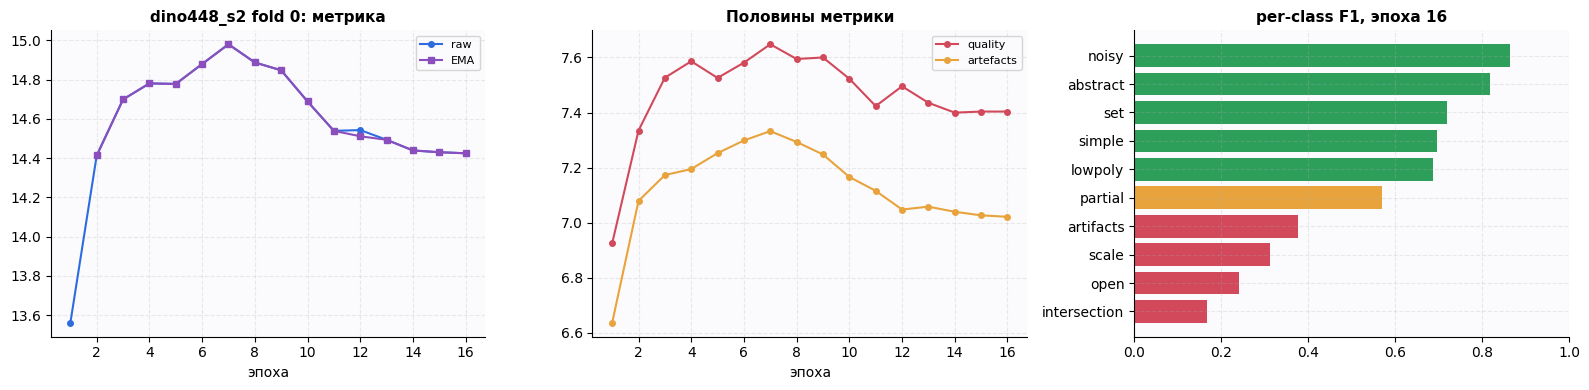

OOF snap1/3 (TTA x2):   0%|          | 0/151 [00:00<?, ?it/s]

test snap1/3 (TTA x2):   0%|          | 0/56 [00:00<?, ?it/s]

OOF snap2/3 (TTA x2):   0%|          | 0/151 [00:00<?, ?it/s]

test snap2/3 (TTA x2):   0%|          | 0/56 [00:00<?, ?it/s]

OOF snap3/3 (TTA x2):   0%|          | 0/151 [00:00<?, ?it/s]

...

  ep15/16 | метрика 14.373 (EMA) = quality  7.48 + artefacts  6.89 | loss 0.204 | 3.5 мин | ост. 3м 28с
        abstr=0.78  artif=0.35  inter=0.06  lowpo=0.65  noisy=0.85  open=0.36  parti=0.57  scale=0.29  set=0.64  simpl=0.71  quali=0.75
    [зеркало] чекпоинт эпохи 15 -> Drive (225 МБ)


dino448_s2 f1 ep16/16:   0%|          | 0/1196 [00:00<?, ?it/s]

val ep16 (TTA x1):   0%|          | 0/149 [00:00<?, ?it/s]

val-EMA ep16 (TTA x1):   0%|          | 0/149 [00:00<?, ?it/s]

  ep16/16 | метрика 14.351 (EMA) = quality  7.46 + artefacts  6.89 | loss 0.202 | 3.8 мин | ост. 0м 00с
        abstr=0.78  artif=0.34  inter=0.06  lowpo=0.65  noisy=0.85  open=0.36  parti=0.57  scale=0.27  set=0.65  simpl=0.71  quali=0.75
    [зеркало] чекпоинт эпохи 16 -> Drive (225 МБ)


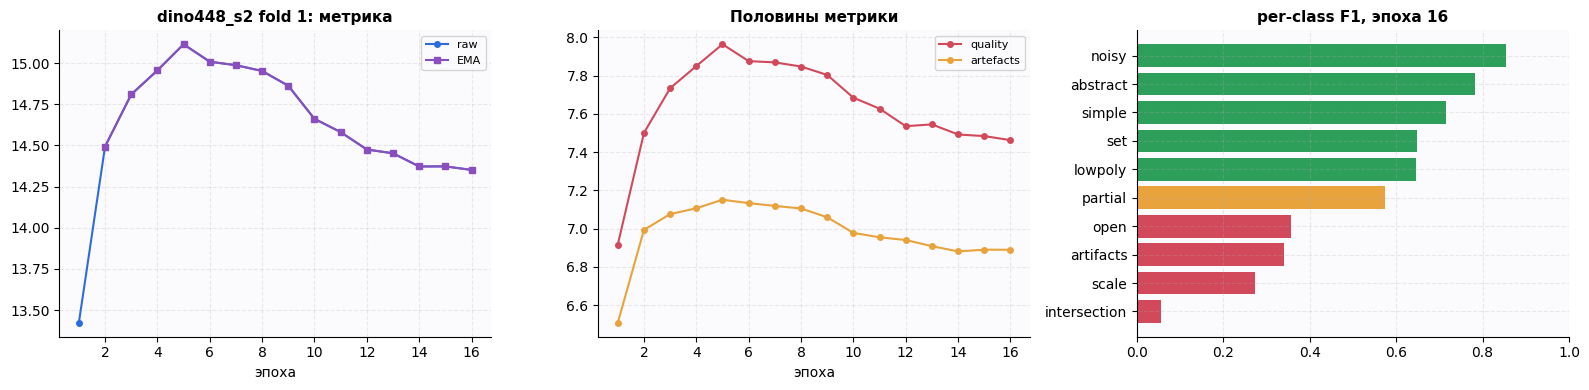

OOF snap1/3 (TTA x2):   0%|          | 0/149 [00:00<?, ?it/s]

test snap1/3 (TTA x2):   0%|          | 0/56 [00:00<?, ?it/s]

OOF snap2/3 (TTA x2):   0%|          | 0/149 [00:00<?, ?it/s]

test snap2/3 (TTA x2):   0%|          | 0/56 [00:00<?, ?it/s]

OOF snap3/3 (TTA x2):   0%|          | 0/149 [00:00<?, ?it/s]

...

  ep15/16 | метрика 14.103 (EMA) = quality  6.97 + artefacts  7.13 | loss 0.201 | 4.1 мин | ост. 3м 29с
        abstr=0.80  artif=0.32  inter=0.26  lowpo=0.71  noisy=0.86  open=0.38  parti=0.62  scale=0.44  set=0.66  simpl=0.73  quali=0.70
    [зеркало] чекпоинт эпохи 15 -> Drive (225 МБ)


dino448_s2 f2 ep16/16:   0%|          | 0/1198 [00:00<?, ?it/s]

val ep16 (TTA x1):   0%|          | 0/148 [00:00<?, ?it/s]

val-EMA ep16 (TTA x1):   0%|          | 0/148 [00:00<?, ?it/s]

  ep16/16 | метрика 14.141 (raw) = quality  7.01 + artefacts  7.13 | loss 0.197 | 3.5 мин | ост. 0м 00с
        abstr=0.80  artif=0.32  inter=0.24  lowpo=0.71  noisy=0.86  open=0.38  parti=0.62  scale=0.43  set=0.67  simpl=0.73  quali=0.70
    [зеркало] чекпоинт эпохи 16 -> Drive (225 МБ)


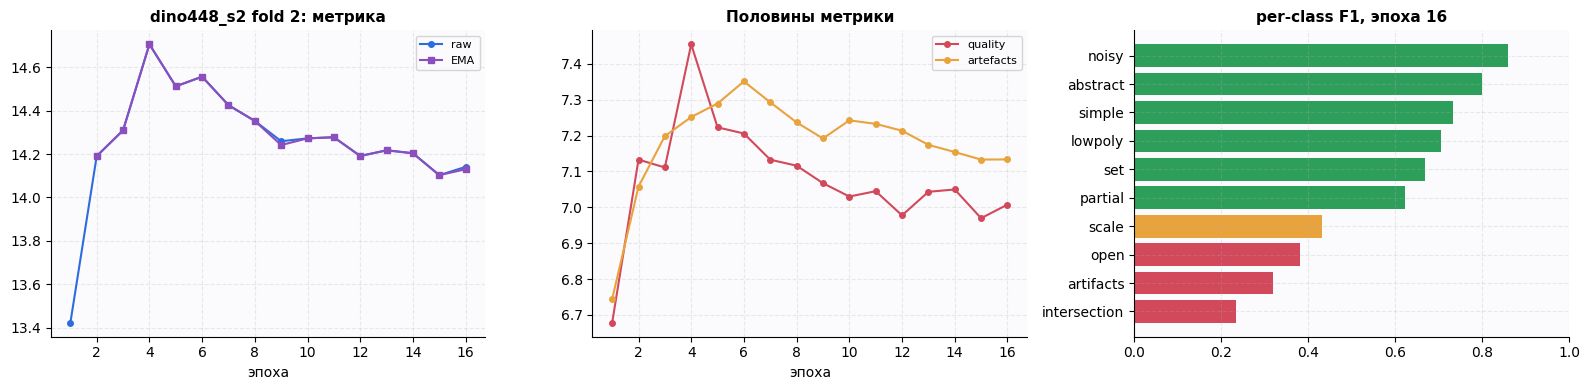

OOF snap1/3 (TTA x2):   0%|          | 0/148 [00:00<?, ?it/s]

test snap1/3 (TTA x2):   0%|          | 0/56 [00:00<?, ?it/s]

OOF snap2/3 (TTA x2):   0%|          | 0/148 [00:00<?, ?it/s]

test snap2/3 (TTA x2):   0%|          | 0/56 [00:00<?, ?it/s]

OOF snap3/3 (TTA x2):   0%|          | 0/148 [00:00<?, ?it/s]

...

dino448_s2 f3 ep13/16:   0%|          | 0/1192 [00:00<?, ?it/s]

val ep13 (TTA x1):   0%|          | 0/151 [00:00<?, ?it/s]

val-EMA ep13 (TTA x1):   0%|          | 0/151 [00:00<?, ?it/s]

  ep13/16 | метрика 14.340 (raw) = quality  7.37 + artefacts  6.97 | loss 0.219 | 4.2 мин | ост. 10м 31с
        abstr=0.79  artif=0.31  inter=0.12  lowpo=0.67  noisy=0.86  open=0.34  parti=0.61  scale=0.36  set=0.65  simpl=0.72  quali=0.74


dino448_s2 f3 ep14/16:   0%|          | 0/1192 [00:00<?, ?it/s]

In [ ]:
RUNS['dino448_s2'] = run_branch('dino448_s2')

### 10.4. Сводка по веткам

In [ ]:
R.section('Ветки: OOF по каждой')
rows = []
for name, run in RUNS.items():
    rows.append({'ветка': name, 'backbone': str(run['backbone']).split('.')[0],
                 'tile': run['tile'], 'OOF': round(run['score'], 3),
                 'вес': ENS_WEIGHTS[name],
                 'фолды': ', '.join(f'{k}:{v:.2f}' for k, v in run['folds'].items())})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
_atomic(LOCAL / 'branch_summary.csv', lambda p: summary.to_csv(p, index=False))

if LOG_CSV.exists():
    lg = pd.read_csv(LOG_CSV)
    fig, ax = plt.subplots(figsize=(9, 4))
    for name, g in lg.groupby('run'):
        m = g.groupby('epoch')['val_metric'].mean()
        ax.plot(m.index, m.values, '-o', ms=3, label=name)
    ax.set_xlabel('эпоха'); ax.set_ylabel('метрика на валидации'); ax.legend()
    ax.set_title('Обучение трёх веток (среднее по фолдам)')
    plt.tight_layout(); plt.show()

## 11. Ансамбль: фиксированные веса и пороги по OOF

Веса заданы условием: `vitb336 = 0.75`, `dino448_s2 = 1.00`, `v5_224 = 0.50` — они не
подбираются по OOF. Подбираются только пороги по каждому из 11 классов, и честность
этого подбора проверяется вложенной оценкой: пороги настраиваются на 4 фолдах, метрика
считается на пятом.

In [ ]:
R.section('Ансамбль трёх веток', f'веса {ENS_WEIGHTS}')

CC = ['cnn_' + c for c in CFG.target_cols]
IDX_TR = train_df['item_id'].tolist()
IDX_TE = test_df['item_id'].tolist()

mask = np.ones(len(train_df), dtype=bool)
for run in RUNS.values():
    mask &= run['mask']
print('объектов с OOF во всех трёх ветках:', int(mask.sum()), 'из', len(train_df))

wsum = sum(ENS_WEIGHTS[n] for n in RUNS)
P_oof = np.zeros((int(mask.sum()), 11))
P_te = np.zeros((len(test_df), 11))
for name, run in RUNS.items():
    w = ENS_WEIGHTS[name] / wsum
    P_oof += w * run['oof'].loc[mask, CC].values
    te = run['te'].set_index('item_id').reindex(IDX_TE)[CC].values
    P_te += w * te

Y = train_df.loc[mask, CFG.target_cols].values
TH = np.array([exact_f1_threshold(Y[:, i], P_oof[:, i])[0] for i in range(11)])
pred_oof = (P_oof > TH).astype(int)
score, fq, fa = competition_metric(Y, pred_oof)

# --- вложенная оценка: пороги на 4 фолдах, метрика на пятом ---
folds_masked = train_df.loc[mask, 'fold'].values
nested = []
for k in range(CFG.n_folds):
    tr_i, va_i = folds_masked != k, folds_masked == k
    if va_i.sum() == 0:
        continue
    th_k = np.array([exact_f1_threshold(Y[tr_i, i], P_oof[tr_i, i])[0] for i in range(11)])
    nested.append(competition_metric(Y[va_i], (P_oof[va_i] > th_k).astype(int))[0])
nested = np.array(nested)

R.kv(**{'OOF ансамбля': f'{score:.3f} (quality {10 * fq:.2f} + artefacts {10 * fa:.2f})',
        'вложенная оценка': f'{nested.mean():.3f} ± {nested.std():.3f}',
        'по фолдам': np.round(nested, 3)})
for name, run in RUNS.items():
    R.bar(run['score'], label=name)
R.bar(score, label='АНСАМБЛЬ')

rep = pd.DataFrame({'f1': [f1_score(Y[:, i], pred_oof[:, i], zero_division=0) for i in range(11)],
                    'порог': TH.round(3),
                    'доля в train': Y.mean(0).round(3),
                    'доля предсказанная': pred_oof.mean(0).round(3)}, index=CFG.target_cols)
print()
print(rep.round(3).to_string())
save_artifact('ensemble_state', {'weights': ENS_WEIGHTS, 'th': TH, 'oof': P_oof, 'te': P_te,
                                 'mask': mask, 'score': score, 'nested': nested})

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].barh(rep.index, rep['f1'].values,
           color=[PAL['bad'] if v < .4 else PAL['warn'] if v < .6 else PAL['good']
                  for v in rep['f1'].values])
ax[0].set_xlim(0, 1); ax[0].set_title('Ансамбль: per-class F1 (OOF)')
names = list(RUNS) + ['ансамбль']
vals = [RUNS[n]['score'] for n in RUNS] + [score]
ax[1].bar(names, vals, color=[PAL['main']] * len(RUNS) + [PAL['good']])
ax[1].set_ylim(min(vals) - 0.5, max(vals) + 0.3); ax[1].set_title('OOF: ветки и ансамбль')
plt.tight_layout(); plt.show()

## 12. Предсказание на тесте и сабмит

Пороги — те же, что настроены по OOF. Дополнительно согласуем `quality` с тождеством
разметки: в train `quality = 1` ровно тогда, когда не выставлен ни один из 10 дефектов.
Вариант согласования выбирается по OOF, а не «на глаз».

In [ ]:
R.section('Сабмит')


def postprocess(pred):
    """quality приводится к тождеству разметки: нет дефектов <=> quality=1."""
    out = pred.copy()
    out[:, 10] = (out[:, :10].sum(1) == 0).astype(int)
    return out


cands = {'как есть': pred_oof, 'quality из дефектов': postprocess(pred_oof)}
best_name, best_sc = None, -1
for nm, pp in cands.items():
    sc = competition_metric(Y, pp)[0]
    print(f'  {nm:<24s} OOF {sc:.3f}')
    if sc > best_sc:
        best_name, best_sc = nm, sc
R.ok(f'выбрано: {best_name} (OOF {best_sc:.3f})')

pred_te = (P_te > TH).astype(int)
if best_name != 'как есть':
    pred_te = postprocess(pred_te)

sub = pd.DataFrame(pred_te, columns=CFG.target_cols)
sub.insert(0, 'item_id', IDX_TE)
stamp = time.strftime('%Y%m%d_%H%M')
name = f'submission_ens3_{stamp}.csv'
_atomic(SUB / name, lambda p: sub.to_csv(p, index=False))
sub.to_csv('submission.csv', index=False)          # копия в корень рантайма

print()
print('доли предсказанных меток на тесте против train:')
print(pd.DataFrame({'test': sub[CFG.target_cols].mean().round(3),
                    'train': train_df[CFG.target_cols].mean().round(3)}).to_string())
R.kv(**{'файл': SUB / name, 'копия': 'submission.csv', 'объектов': len(sub),
        'OOF ансамбля': f'{best_sc:.3f}',
        'вложенная оценка': f'{nested.mean():.3f} ± {nested.std():.3f}',
        'всего времени': f'{(time.time() - RUN_T0) / 3600:.1f} ч'})
print(sub.head().to_string(index=False))

## 13. Что лежит в папке прогона

`RUN_DIR/artifacts` — предсказания каждого фолда каждой ветки, таблицы признаков, CLIP,
состояние ансамбля; `RUN_DIR/ckpt` — незавершённые фолды; `RUN_DIR/submissions` — сабмиты
с меткой времени; `RUN_DIR/training_log.csv` — построчный лог всех эпох всех веток.

In [ ]:
R.section('Содержимое папки прогона', str(LOCAL))
for sub_ in ('artifacts', 'ckpt', 'submissions'):
    d = LOCAL / sub_
    files = sorted(d.glob('*')) if d.exists() else []
    print(f'  {sub_}: {len(files)} файлов, '
          f'{sum(f.stat().st_size for f in files) / 1e6:.0f} МБ')
    for f in files[:12]:
        print(f'      {f.name:<52s} {f.stat().st_size / 1e6:8.1f} МБ')
if LOG_CSV.exists():
    print(f'  training_log.csv: {len(pd.read_csv(LOG_CSV))} строк')

## 14. Интерпретируемость: почему модель поставила именно такой ответ

Раздел использует уже готовые признаки и рендеры ветки `dino448_s2` — она обучалась
последней (§10.3), поэтому её `feat_tr`/`feat_te`/`IMG_TRAIN`/`IMG_TEST`/`FEAT_COLS`
ещё в памяти, а её вес в ансамбле максимальный (1.0, §11). Сама обученная модель к
этому моменту уже удалена из памяти (`train_fold`, §9, чистит её после каждого
фолда) — веса лучшего снапшота фолда 0 сохраняются отдельно, специально для этого
раздела, в `INTERPRET/{run_tag}_fold0_best.pt` (§9) и не удаляются `drop_ckpt()`.

Два независимых метода объяснения одного предсказания:

1. **Внутреннее внимание модели** — gated attention pooling (§8) сам выдаёт вес
   каждого из 6 видов при агрегации в один вектор: какой ракурс модель использовала.
2. **Occlusion sensitivity** — независимая проверка: по очереди закрываем часть
   каждого вида нейтральным фоном и смотрим, насколько падает вероятность класса.
   Метод не зависит от внутреннего устройства модели и не требует градиентов,
   поэтому служит перекрёстной проверкой первому.

Объекты берутся в двух режимах: **OOF** (валидация внутри train, истинные метки
известны — можно честно отделить fail-кейс от хорошего) и **test** (соревновательная
тестовая выборка без меток — кейсы отбираются по уверенности модели: высокая
уверенность = «хороший отобранный вариант», вероятность около 0.5 = «неуверенный/
fail-подобный случай», в терминах задания на баллы за это раздел).

In [ ]:
assert CFG.run_tag == 'dino448_s2', 'секция ожидает CFG в состоянии после §10.3'
_ckpt_path = INTERPRET / 'dino448_s2_fold0_best.pt'
assert _ckpt_path.exists(), (
    f'{_ckpt_path} не найден — раздел требует, чтобы фолд 0 ветки dino448_s2 был обучен (§10.3)')

_ckpt = torch.load(_ckpt_path, map_location='cpu', weights_only=False)
model_explain = MultiViewNet(_ckpt['n_feats']).to(CFG.device)
model_explain.load_state_dict(_to_fp32(_ckpt['model']))
model_explain.eval()
for p_ in model_explain.parameters():
    p_.requires_grad_(False)
R.ok(f'веса dino448_s2 (фолд 0, лучший снапшот) загружены для интерпретации '
     f'({sum(p_.numel() for p_ in model_explain.parameters()) / 1e6:.1f}M параметров)')

In [ ]:
_WHITE_NORM = torch.tensor((1.0 - MEAN) / STD, dtype=torch.float32,
                           device=CFG.device).view(1, 3, 1, 1)


@torch.no_grad()
def explain_object(item_id, img_dir, feats_df, target_class, occlude_grid=3):
    """Два метода объяснения для одного объекта и одного класса:
    (1) веса gated attention pooling по 6 видам, (2) occlusion sensitivity —
    падение вероятности класса при закрытии части каждого вида фоном."""
    j = CFG.target_cols.index(target_class)
    ds = MeshViewDataset(pd.DataFrame({'item_id': [item_id]}), img_dir, feats_df,
                         train=False, labels=False)
    b = ds[0]
    v = b['views'][None].to(CFG.device)          # (1,6,3,t,t)
    f = b['feats'][None].to(CFG.device)

    logits, att = model_explain(v, f, return_att=True)
    p0 = torch.sigmoid(logits)[0, j].item()
    w = att[0].detach().cpu().numpy()             # (6,) — вес вида в пулинге

    t = v.shape[-1]
    step = max(t // occlude_grid, 1)
    sens = np.zeros((6, occlude_grid, occlude_grid))
    for view in range(6):
        for gy in range(occlude_grid):
            for gx in range(occlude_grid):
                vv = v.clone()
                vv[0, view, :, gy * step:(gy + 1) * step, gx * step:(gx + 1) * step] = _WHITE_NORM[0]
                pj = torch.sigmoid(model_explain(vv, f))[0, j].item()
                sens[view, gy, gx] = p0 - pj       # положительное = регион важен для класса
    return {'p0': p0, 'att': w, 'sens': sens}


def plot_explanation(item_id, img_dir, feats_df, target_class, true_label=None, occlude_grid=3):
    res = explain_object(item_id, img_dir, feats_df, target_class, occlude_grid)
    views = split_views_raw(Image.open(Path(img_dir) / f'{item_id}.png').convert('RGB'))

    fig, axes = plt.subplots(2, 6, figsize=(15, 5.3))
    for k in range(6):
        axes[0, k].imshow(views[k]); axes[0, k].axis('off')
        axes[0, k].set_title(f'вид {k}\nвнимание {res["att"][k]:.2f}', fontsize=8)
        hm = res['sens'][k]
        reps_y = views[k].size[1] // hm.shape[0] + 1
        reps_x = views[k].size[0] // hm.shape[1] + 1
        hm_up = np.kron(hm, np.ones((reps_y, reps_x)))[:views[k].size[1], :views[k].size[0]]
        vmax = max(np.abs(res['sens']).max(), 1e-6)
        axes[1, k].imshow(views[k])
        axes[1, k].imshow(hm_up, cmap='jet', alpha=0.45, vmin=-vmax, vmax=vmax)
        axes[1, k].axis('off')

    truth = f' | истина={int(true_label)}' if true_label is not None else ' | истина неизвестна (test)'
    fig.suptitle(f'{item_id[:8]} · класс «{target_class}»: p={res["p0"]:.2f}{truth}\n'
                f'сверху — вес вида в пулинге, снизу — occlusion sensitivity (красное = важно)',
                fontsize=10)
    plt.tight_layout(); plt.show()
    return res


SHOWCASE_CLASSES = ['noisy', 'open']   # один частый/глобальный класс, один редкий/локальный

### 14.1. OOF: хорошие и fail-кейсы (истинные метки известны)

Для каждого класса из `SHOWCASE_CLASSES` — один уверенный правильный ответ
ансамбля и один настоящий fail-кейс (наибольшее расхождение предсказания
ансамбля `P_oof` с истинной меткой `Y`, §11). Объяснение строится по
`dino448_s2` — сильнейшему источнику, а не буквально по ансамблю.

In [ ]:
oof_ids_arr = np.asarray(IDX_TR)[mask]
for cls in SHOWCASE_CLASSES:
    j = CFG.target_cols.index(cls)
    err = np.abs(P_oof[:, j] - Y[:, j])
    correct_conf = np.where((Y[:, j] == (P_oof[:, j] > TH[j])) & (err < 0.15))[0]
    fail = np.argsort(-err)[:5]

    R.section(f'Класс «{cls}»')
    if len(correct_conf):
        i_good = correct_conf[np.argmax(P_oof[correct_conf, j] * (2 * Y[correct_conf, j] - 1))]
        print(f'хороший кейс: истина={int(Y[i_good, j])}, P_oof(ансамбль)={P_oof[i_good, j]:.2f}')
        plot_explanation(oof_ids_arr[i_good], IMG_TRAIN, feat_tr, cls, true_label=Y[i_good, j])
    i_fail = fail[0]
    print(f'fail-кейс: истина={int(Y[i_fail, j])}, P_oof(ансамбль)={P_oof[i_fail, j]:.2f} '
          f'(расхождение {err[i_fail]:.2f})')
    plot_explanation(oof_ids_arr[i_fail], IMG_TRAIN, feat_tr, cls, true_label=Y[i_fail, j])

### 14.2. Test: качественные примеры (истинных меток нет)

Соревновательный `test.csv` — без разметки, поэтому здесь «хороший» и
«неуверенный/fail-подобный» случай отбираются по уверенности предсказания
ансамбля `P_te`, а не по совпадению с истиной.

In [ ]:
P_te_full = pd.DataFrame(P_te, columns=CFG.target_cols, index=IDX_TE)
for cls in SHOWCASE_CLASSES:
    p = P_te_full[cls]
    confident = p[(p > 0.85) | (p < 0.15)].index
    borderline = (p - 0.5).abs().sort_values().index

    R.section(f'Класс «{cls}» (test)')
    if len(confident):
        iid = confident[np.random.RandomState(CFG.seed).randint(len(confident))]
        print(f'уверенный случай: P_te(ансамбль)={p[iid]:.2f}, предсказано {int(sub.set_index("item_id").loc[iid, cls])}')
        plot_explanation(iid, IMG_TEST, feat_te, cls)
    iid = borderline[0]
    print(f'неуверенный (fail-подобный) случай: P_te(ансамбль)={p[iid]:.2f}')
    plot_explanation(iid, IMG_TEST, feat_te, cls)

### 14.3. Итог раздела

Оба метода — внутреннее внимание пулинга и внешняя occlusion-проверка — по
конструкции не могут совпадать буквально (один смотрит на веса модели, другой
на изменение выхода), но должны указывать на **сопоставимые** виды/области для
уверенных случаев: если внимание и occlusion расходятся полностью, это сигнал
не доверять объяснению для конкретного объекта, а не только его классу. Раздел
не заменяет численную оценку (§9–§11) — он показывает, что предсказания ансамбля
объяснимы на уровне отдельных ракурсов, а не являются result-ом «чёрного ящика».